# Google Play Store App Market Analysis
### Exploratory Data Analysis of App Listings and User Reviews

## Project Name
**Google Play Store App Market Analysis** — Exploratory Data Analysis of App Listings and User Reviews

## Project Type
Exploratory Data Analysis (EDA) on two linked tables (app listings and user reviews) — univariate, bivariate (numerical–categorical, numerical–numerical, categorical–categorical), multivariate, sentiment/text analysis and statistical validation

## Project Summary
This project analyses the Google Play Store through two linked files: Play Store Data, with 10,841 app listings, and User Reviews, with 64,295 review rows that carry a sentiment label, a polarity score and a subjectivity score. After cleaning, the analysis covers 9,659 unique apps in 33 categories and 29,692 usable text reviews, of which 28,250 (816 apps) can be joined to app details. Each app has a category, star rating, review count, install band, size, price, content rating, genres, last-update date and minimum Android version. The market is overwhelmingly free (92.2% of apps) and heavily skewed toward a few winners.

The raw files needed careful preparation, and every step is recorded. One listing was shifted by a column and was removed; 483 exact duplicates were dropped and 698 repeated app names were collapsed to the row with the most reviews. Size, installs, price and dates were stored as text and were converted to numbers, keeping the raw columns beside them. Gaps that carry meaning were not filled: 15.1% of apps have no rating, and 12.7% have a size that varies with device. Status columns explain them instead. In the review file, 26,868 rows had no text and 7,735 were exact repeats, so both were removed. Unusual values, such as $399.99 novelty apps or perfect ratings on a handful of reviews, are flagged rather than deleted. Group comparisons use ratings backed by at least 100 reviews, and every headline comparison is checked with a non-parametric test, an effect size and bootstrap confidence intervals.

The notebook contains 41 charts covering completeness, distributions, comparisons across category, pricing model, content rating, install band and update recency, relationships between rating, reviews, installs, size and price, and a text analysis of user reviews. Each chart is followed by a plain-language explanation of why it was drawn, what the numbers show and what a publisher should do.

Four findings stand out. First, reach is extremely concentrated. The median app has about 1,000 reviews, the top 10% of apps hold 92.8% of all reviews, and the 14.2% of apps with 10 million or more installs account for roughly 94% of install volume. Second, ratings are high and compressed (median 4.3, only 23.3% below 4.0), so a rating alone separates apps poorly. Category explains only about 3% of rating variation, and rating is almost unrelated to installs (rank correlation 0.03). Third, pricing and upkeep matter more than they first appear. Paid apps are rated higher (mean 4.35 against 4.19) yet reach far fewer people, with a median of 1,000 installs against 100,000 and just 22 paid apps above one million installs. Apps updated in the last 30 days have a mean rating of 4.27 and 56.7% reach one million installs, against 4.06 and 18.5% for apps untouched for over a year. Fourth, users are mostly positive (64.0% of reviews), yet sentiment varies sharply by category: Health & Fitness is 77.9% positive while Game is only 58.8%, with 36.2% negative. Ads, crashes and login problems are the themes that separate negative from positive reviews.

The commercial reading is a set of clear priorities: keep apps freshly updated, treat free-plus-monetisation as the default route to scale, target under-served high-rated categories, fix the recurring complaints, and surface the 203 hidden gems that are highly rated yet modestly installed. Install bands are lower bounds and ratings come from the store page, so findings describe associations, not causes. The notebook runs top to bottom in one pass, so it serves as a monitoring baseline and as the foundation for a leakage-free model that predicts which apps reach one million installs.

## Problem Statement
The Play Store holds millions of apps, and a publisher deciding what to build, how to price it and how to maintain it faces a market that looks large but rewards very few. In this dataset 92.2% of apps are free, one third have fewer than 10,000 installs, and a small group of apps collects almost all reviews and installs. Star ratings are usually treated as the quality signal, yet they cluster between 4.0 and 4.7, so they say little about who will actually succeed. Metadata is uneven as well: 15.1% of apps show no rating, 12.7% hide their size, and only 8.4% of apps have any written reviews in the review file. Without a clear, data-backed picture, product and monetisation decisions rest on anecdotes about a few famous apps instead of on what the wider market shows.

## Business Objective
1. **Map** the market honestly: which categories are crowded, which are thin, how concentrated installs and reviews are, and how much of the data can be trusted (ratings with at least 100 reviews, categories with at least 40 apps).
2. **Explain** what is linked to quality and to reach: category, pricing model, content rating, size, update recency and Android support, using effect sizes and tests so small differences are not over-read.
3. **Listen** to users: measure review sentiment by category and rating tier, and identify the complaints that separate negative from positive reviews.
4. **Recommend** four data-backed actions for publishers and define a clean, leakage-free path to predictive modelling of high-reach apps.

## How this notebook is organised
- **Sections 1–8:** setup, loading, data-quality audit, cleaning, feature engineering, outlier flags, cleaned-data export and KPI snapshot.
- **Part A (sections 9–14):** 41 charts. Every chart cell is followed by *Why this chart / Insight / Business impact*; the numbers quoted are printed directly under each chart.
- **Part B:** supporting tables (category, genre, type, content rating, install band, update year, sentiment, standout apps, status fields, outliers).
- **Sections 15 onward:** statistical validation, evidence for the conclusion, automated quality checks, conclusion and GitHub link.

**To run:** place `Play Store Data.csv` and `User Reviews.csv` in `data/raw/` (or next to the notebook, or in `/content` on Google Colab), then *Restart & Run All*. Outputs go to `data/processed/` and `visualizations/`.

## 1. Setup — configuration, helpers and reproducibility

In [1]:
# --- Configuration: one place for paths, seed and plotting defaults ---
import re
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
SEED = 42                      # every random sample below passes random_state=SEED
np.random.seed(SEED)

# Works from the repo root, from /notebooks, from Google Colab (/content) or next to the CSV files.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SEARCH_DIRS = [ROOT / "data" / "raw", ROOT, Path("/content"), Path("/content/drive/MyDrive"), Path("/mnt/user-data/uploads")]
APP_FILE_NAMES = ["Play Store Data.csv", "Play_Store_Data.csv", "googleplaystore.csv"]
REVIEW_FILE_NAMES = ["User Reviews.csv", "User_Reviews.csv", "googleplaystore_user_reviews.csv"]
PROC_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "visualizations"
CLEAN_APPS_PATH = PROC_DIR / "play_store_apps_cleaned.csv"
CLEAN_REVIEWS_PATH = PROC_DIR / "user_reviews_cleaned.csv"
NOTEBOOK_NAME = "Play_Store_Complete_EDA_Project.ipynb"
for folder in (PROC_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)   # create output folders if missing

EXPECTED_RAW_APPS, EXPECTED_RAW_REVIEWS = 10_841, 64_295
MIN_REVIEWS = 100              # ratings backed by fewer than 100 reviews are too noisy for group comparisons
MIN_APPS = 40                  # minimum apps per category / genre for a fair group comparison

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11})

def find_file(names):
    for folder in SEARCH_DIRS:
        for name in names:
            if (folder / name).exists():
                return folder / name
    return None

RAW_APPS, RAW_REVIEWS = find_file(APP_FILE_NAMES), find_file(REVIEW_FILE_NAMES)
print("Project root        :", ROOT.name)
print("Play Store data     :", RAW_APPS)
print("User reviews data   :", RAW_REVIEWS)
assert RAW_APPS is not None and RAW_REVIEWS is not None, "Place both CSV files in data/raw/ (or next to the notebook)"

Project root        : work
Play Store data     : /home/claude/work/data/raw/Play Store Data.csv
User reviews data   : /home/claude/work/data/raw/User Reviews.csv


In [2]:
FREE_PAID = ["Free", "Paid"]
RATING_TIER_ORDER = ["Low (<4.0)", "Good (4.0-4.4)", "Excellent (4.5+)"]
INSTALL_BAND_ORDER = ["<1K", "1K-10K", "10K-100K", "100K-1M", "1M-10M", "10M+"]
SIZE_BAND_ORDER = ["<5 MB", "5-10 MB", "10-25 MB", "25-50 MB", "50+ MB"]
PRICE_BAND_ORDER = ["<= $1", "$1-2", "$2-5", "$5-10", "$10+"]
SENTIMENT_ORDER = ["Positive", "Neutral", "Negative"]
CONTENT_ORDER = ["Everyone", "Everyone 10+", "Teen", "Mature 17+", "Adults only 18+", "Unrated"]
PALETTE_TYPE = {"Free": "#4C78A8", "Paid": "#F28E2B"}
PALETTE_SENT = {"Positive": "#59A14F", "Neutral": "#BAB0AC", "Negative": "#E15759"}
PALETTE_TIER = dict(zip(RATING_TIER_ORDER, ["#E15759", "#BAB0AC", "#59A14F"]))
BASE_COLOR = "#4C78A8"

def pretty(cat):
    """ART_AND_DESIGN -> Art And Design (short, readable axis labels)."""
    return str(cat).replace("_AND_", " & ").replace("_", " ").title()

def human(x, pos=None):
    """Short tick labels (1K, 2.5M) so log axes stay readable."""
    for div, suffix in ((1e9, "B"), (1e6, "M"), (1e3, "K")):
        if abs(x) >= div:
            return f"{x / div:g}{suffix}"
    return f"{x:g}"

def humanize_axis(ax, axis="both"):
    fmt = mtick.FuncFormatter(human)
    if axis in ("x", "both"):
        ax.xaxis.set_major_formatter(fmt)
    if axis in ("y", "both"):
        ax.yaxis.set_major_formatter(fmt)

def save_fig(fig, name):
    """Save at 200 dpi first (so the PNG is complete), then display inline."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def plot_hist(s, title, xlabel, name, bins=40, log_x=False, log_y=False, color=BASE_COLOR, ylabel="Apps", ref=None, ref_label=None):
    """Histogram with a median line; log_x suits right-skewed counts."""
    s = s.dropna()
    if log_x:
        s = s[s > 0]                      # log of zero is undefined
    fig, ax = plt.subplots(figsize=(9, 5.5))
    sns.histplot(s, bins=bins, log_scale=log_x, color=color, edgecolor="white", ax=ax)
    if log_y:
        ax.set_yscale("log")
    ref = s.median() if ref is None else ref
    ax.axvline(ref, color="black", ls="--", lw=1.3, label=ref_label or f"Median = {human(ref) if log_x else round(ref, 2)}")
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel + (" (log scale)" if log_y else ""))
    humanize_axis(ax, "x" if log_x else "none")
    ax.legend(frameon=True)
    fig.tight_layout()
    save_fig(fig, name)

def plot_bar(counts, title, xlabel, ylabel, name, horizontal=True, color=BASE_COLOR, figsize=(9, 5.5), total=None):
    """Bar chart of counts, each bar labelled with count and share of `total` (default: sum of bars)."""
    total = counts.sum() if total is None else total
    fig, ax = plt.subplots(figsize=figsize)
    if horizontal:
        ax.barh(counts.index.astype(str), counts.values, color=color)
        ax.invert_yaxis()                 # largest category on top
    else:
        ax.bar(counts.index.astype(str), counts.values, color=color)
    ax.bar_label(ax.containers[0], labels=[f"{v:,} ({v / total:.1%})" for v in counts.values], padding=3, fontsize=9)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.margins(x=0.2 if horizontal else 0.02, y=0.12 if not horizontal else 0.02)
    (ax.xaxis if horizontal else ax.yaxis).set_major_formatter(mtick.FuncFormatter(lambda v, p: f"{v:,.0f}"))
    fig.tight_layout()
    save_fig(fig, name)

def plot_box(data, x, y, title, xlabel, ylabel, name, order=None, palette=None, log_y=False, ylim=None, figsize=(9, 5.8), rotate=0):
    """Box plot with n shown under each category."""
    order = order or list(data[x].value_counts().index)
    n = data[x].value_counts()
    fig, ax = plt.subplots(figsize=figsize)
    sns.boxplot(data=data, x=x, y=y, order=order, palette=palette, hue=x if palette else None, legend=False,
                fliersize=2, linewidth=1.1, dodge=False, ax=ax)
    if log_y:
        ax.set_yscale("log")
    if ylim:
        ax.set_ylim(*ylim)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([f"{o}\n(n={n[o]:,})" for o in order], rotation=rotate, ha="right" if rotate else "center")
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    if log_y:
        humanize_axis(ax, "y")
    fig.tight_layout()
    save_fig(fig, name)

def loglog_scatter(data, x, y, title, xlabel, ylabel, name, color=BASE_COLOR):
    """Log-log scatter with a fitted power-law line; returns fit statistics for the evidence printout."""
    d = data[[x, y]].dropna()
    d = d[(d[x] > 0) & (d[y] > 0)]
    slope, intercept = np.polyfit(np.log10(d[x]), np.log10(d[y]), 1)
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.scatter(d[x], d[y], s=10, alpha=0.3, color=color, edgecolors="none")
    grid = np.logspace(np.log10(d[x].min()), np.log10(d[x].max()), 50)
    ax.plot(grid, 10 ** intercept * grid ** slope, color="#E15759", lw=2, label=f"Fitted trend (slope {slope:.2f})")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    humanize_axis(ax)
    ax.legend(frameon=True, loc="upper left")
    fig.tight_layout()
    save_fig(fig, name)
    return {"n": len(d), "slope": float(slope), "spearman": float(d[x].corr(d[y], method="spearman"))}

def plot_stacked_pct(ct_pct, title, ylabel, name, order, palette, figsize=(9, 5.5)):
    """100% stacked horizontal bars with the percentage written on every segment."""
    fig, ax = plt.subplots(figsize=figsize)
    left = np.zeros(len(ct_pct))
    for col in order:
        vals = ct_pct[col].values * 100
        ax.barh([str(i) for i in ct_pct.index], vals, left=left, color=palette[col], label=col)
        for i, (v, l) in enumerate(zip(vals, left)):
            if v >= 4:
                ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        left += vals
    ax.invert_yaxis()
    ax.set(title=title, xlabel="Share (%)", ylabel=ylabel, xlim=(0, 100))
    ax.legend(ncol=len(order), loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
    fig.tight_layout()
    save_fig(fig, name)

def cliffs_delta(a, b):
    """Effect size for two groups: probability a random value from a beats one from b, rescaled to -1..+1."""
    u = stats.mannwhitneyu(a, b, alternative="two-sided").statistic
    return 2 * u / (len(a) * len(b)) - 1

print("Helpers ready.")

Helpers ready.


## 2. Load the raw data
There are two files. `Play Store Data.csv` has one row per app listing; `User Reviews.csv` has one row per translated review with its sentiment scores. The loader is defensive about encoding and strips any byte-order mark from the column names.

In [3]:
def read_raw_csv(path):
    """utf-8-sig strips a BOM if present; latin1 is the fallback for legacy exports."""
    for encoding in ("utf-8-sig", "latin1"):
        try:
            return pd.read_csv(path, encoding=encoding)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"Could not decode {path.name} with utf-8-sig or latin1")

apps_raw = read_raw_csv(RAW_APPS)
reviews_raw = read_raw_csv(RAW_REVIEWS)
apps_raw.columns = [c.replace("\ufeff", "").strip() for c in apps_raw.columns]
reviews_raw.columns = [c.replace("\ufeff", "").strip() for c in reviews_raw.columns]

assert apps_raw.shape[0] == EXPECTED_RAW_APPS, "Play Store file row count changed"
assert reviews_raw.shape[0] == EXPECTED_RAW_REVIEWS, "User reviews file row count changed"
print(f"Play Store Data : {apps_raw.shape[0]:,} rows x {apps_raw.shape[1]} columns")
print(f"User Reviews    : {reviews_raw.shape[0]:,} rows x {reviews_raw.shape[1]} columns")
apps_raw.head()

Play Store Data : 10,841 rows x 13 columns
User Reviews    : 64,295 rows x 5 columns


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.10,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.90,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.70,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.50,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.30,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


## 3. Data understanding — structure, grain and schema

In [4]:
print(f"apps    -> rows: {apps_raw.shape[0]:,}  |  columns: {apps_raw.shape[1]}")
display(apps_raw.dtypes.astype(str).to_frame("dtype").T)
print(f"reviews -> rows: {reviews_raw.shape[0]:,}  |  columns: {reviews_raw.shape[1]}")
display(reviews_raw.dtypes.astype(str).to_frame("dtype").T)
reviews_raw.head()

apps    -> rows: 10,841  |  columns: 13


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
dtype,str,str,float64,str,str,str,str,str,str,str,str,str,str


reviews -> rows: 64,295  |  columns: 5


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
dtype,str,str,str,float64,float64


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.53
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.29
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.88
4,10 Best Foods for You,Best idea us,Positive,1.00,0.30


### What is one row?

The two tables have different grains, so the analysis distinguishes:
- **app level** — one row per app after cleaning; most charts count apps;
- **review level** — one row per translated user review with a sentiment label, polarity (−1 to +1) and subjectivity (0 to 1);
- **app-review level** — reviews joined to app details by app name, used to link sentiment to category, price and rating;
- **genre level** — an app has one `Category` but a `Genres` field that can hold up to two values separated by `;`, so genre analysis uses the first genre as the primary one.

`Installs` is a **band** (for example `1,000+` means at least 1,000), not an exact count, and `Rating` is the average star rating on the store page.

## 4. Data-quality audit — duplicates, missingness and special values

In [5]:
def quality_table(frame):
    return pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "missing_count": frame.isna().sum(),
        "missing_pct": (frame.isna().mean() * 100).round(2),
        "unique_values": frame.nunique(dropna=True),
    }).sort_values(["missing_pct", "unique_values"], ascending=[False, False])

print("APPS (raw)")
display(quality_table(apps_raw))
print("REVIEWS (raw)")
display(quality_table(reviews_raw))
print(f"Duplicate complete rows  - apps: {apps_raw.duplicated().sum():,} | reviews: {reviews_raw.duplicated().sum():,}")
print(f"Repeated app names       - apps: {apps_raw['App'].str.strip().duplicated().sum():,}")

APPS (raw)


,dtype,missing_count,missing_pct,unique_values
Rating,float64,1474,13.60,40
Current Ver,str,8,0.07,2832
Android Ver,str,3,0.03,33
Content Rating,str,1,0.01,6
Type,str,1,0.01,3
App,str,0,0.00,9660
Reviews,str,0,0.00,6002
Last Updated,str,0,0.00,1378
Size,str,0,0.00,462
Genres,str,0,0.00,120


REVIEWS (raw)


,dtype,missing_count,missing_pct,unique_values
Translated_Review,str,26868,41.79,27994
Sentiment_Polarity,float64,26863,41.78,5410
Sentiment_Subjectivity,float64,26863,41.78,4474
Sentiment,str,26863,41.78,3
App,str,0,0.00,1074


Duplicate complete rows  - apps: 483 | reviews: 33,616
Repeated app names       - apps: 1,181


### Data-quality interpretation

The raw files contain ordinary missing values **and** structural or coded values. The latter must not be treated as random missingness because they carry meaning:
- almost every column of the app file is stored as text, including `Reviews`, `Size`, `Installs`, `Price` and `Last Updated`, so none can be used for calculations yet;
- one row is shifted by one column (its `Category` is `1.9`), so it holds values in the wrong fields;
- `Size` mixes kilobytes and megabytes with the coded text `Varies with device`, `Installs` is a text band such as `1,000+`, and `Price` carries a `$` sign;
- `Rating` is empty for apps that have never been rated, which is a real gap and not something to fill with an average;
- the same app can appear several times with slightly different review counts, and the review file repeats many identical reviews;
- 41.8% of review rows have no review text at all, so they carry no sentiment.

In [6]:
# Inspect coded / structural values before cleaning (they carry meaning, not randomness).
bad_row = apps_raw[apps_raw["Category"] == "1.9"]
print("Corrupted (column-shifted) rows       :", len(bad_row), "->", bad_row["App"].tolist())
print("Names with leading/trailing spaces    :", (apps_raw["App"] != apps_raw["App"].str.strip()).sum())
print("Size 'Varies with device'             :", (apps_raw["Size"] == "Varies with device").sum(), "| in KB:", apps_raw["Size"].str.endswith("k").sum(), "| in MB:", apps_raw["Size"].str.endswith("M").sum())
print("Price starting with '$' (paid)        :", apps_raw["Price"].str.startswith("$").sum(), "| Price == '0':", (apps_raw["Price"] == "0").sum())
print("Type values                           :", apps_raw["Type"].value_counts(dropna=False).to_dict())
print("Current Ver 'Varies with device'      :", (apps_raw["Current Ver"] == "Varies with device").sum(), "| Android Ver 'Varies with device':", (apps_raw["Android Ver"] == "Varies with device").sum())
clean_rating = pd.to_numeric(apps_raw["Rating"], errors="coerce")
print("Rating outside 1-5 (raw)              :", (clean_rating > 5).sum(), "| missing:", clean_rating.isna().sum())

print("\nReviews: rows without review text     :", reviews_raw["Translated_Review"].isna().sum(), f"({reviews_raw['Translated_Review'].isna().mean():.1%})")
print("Reviews: label present but no text    :", (reviews_raw["Translated_Review"].isna() & reviews_raw["Sentiment"].notna()).sum())
print("Reviews: sentiment labels             :", reviews_raw["Sentiment"].value_counts(dropna=False).to_dict())
print("Reviews: polarity outside -1..1       :", (~reviews_raw["Sentiment_Polarity"].dropna().between(-1, 1)).sum())
print("Reviews: subjectivity outside 0..1    :", (~reviews_raw["Sentiment_Subjectivity"].dropna().between(0, 1)).sum())

# Referential integrity between the two files (names compared after trimming spaces).
names_apps = set(apps_raw["App"].str.strip())
names_rev = set(reviews_raw["App"].str.strip())
print(f"\nReviewed apps: {len(names_rev):,} | reviewed apps missing from the app file: {len(names_rev - names_apps)} | app-file apps with reviews: {len(names_apps & names_rev):,}")

Corrupted (column-shifted) rows       : 1 -> ['Life Made WI-Fi Touchscreen Photo Frame']
Names with leading/trailing spaces    : 1
Size 'Varies with device'             : 1695 | in KB: 316 | in MB: 8829
Price starting with '$' (paid)        : 800 | Price == '0': 10040
Type values                           : {'Free': 10039, 'Paid': 800, nan: 1, '0': 1}
Current Ver 'Varies with device'      : 1459 | Android Ver 'Varies with device': 1362
Rating outside 1-5 (raw)              : 1 | missing: 1474

Reviews: rows without review text     : 26868 (41.8%)
Reviews: label present but no text    : 5
Reviews: sentiment labels             : {nan: 26863, 'Positive': 23998, 'Negative': 8271, 'Neutral': 5163}
Reviews: polarity outside -1..1       : 0
Reviews: subjectivity outside 0..1    : 0

Reviewed apps: 1,074 | reviewed apps missing from the app file: 54 | app-file apps with reviews: 1,020


## 5. Cleaning strategy
The cleaning follows *inspect → find the problem → apply the fix → verify*, and it never fills a value it cannot know:
1. remove the one corrupted row (found by its invalid `Category`, not by a hard-coded index);
2. trim spaces, remove exact duplicate rows, then keep **one row per app** (the row with the most reviews, ties broken by the latest update date);
3. convert `Reviews`, `Size`, `Installs`, `Price` and `Last Updated` to proper numbers and dates, keeping the raw text columns next to the clean ones;
4. fill only what can be derived with certainty (`Type` from `Price`); keep `Rating` and `Size_MB` empty when the value is genuinely unknown, and record why in status columns;
5. in the reviews file, drop rows with no review text and exact duplicate reviews, and flag reviews whose app is not in the app file instead of deleting them.

In [7]:
# ---------- APPS ----------
apps = apps_raw[apps_raw["Category"] != "1.9"].copy()                       # 1) corrupted row
for c in ["App", "Category", "Genres", "Current Ver", "Android Ver"]:
    apps[c] = apps[c].str.strip()                                           # 2) whitespace
n_exact = apps.duplicated().sum()
apps = apps.drop_duplicates()
apps["Reviews"] = apps["Reviews"].astype(int)                               # sort by number, not text
apps["Last Updated"] = pd.to_datetime(apps["Last Updated"], format="%B %d, %Y")   # strict format: a bad value raises an error
n_before_app_dedup = len(apps)
apps = (apps.sort_values(["Reviews", "Last Updated"], ascending=[False, False], kind="stable")
            .drop_duplicates(subset="App", keep="first")                    # one row per app: most reviews, then latest update
            .sort_index().reset_index(drop=True))
print(f"Corrupted row removed: 1 | exact duplicates removed: {n_exact} | repeated app names collapsed: {n_before_app_dedup - len(apps)} | apps left: {len(apps):,}")

# 3) text -> numbers, keeping the raw columns for traceability
def size_to_mb(x):
    if x.endswith("k"):
        return round(float(x[:-1]) / 1024, 2)
    if x.endswith("M"):
        return float(x[:-1])
    return np.nan                                                           # 'Varies with device' -> unknown, not guessed

apps["Size_MB"] = apps["Size"].map(size_to_mb)
apps["Installs_count"] = apps["Installs"].str.replace("+", "", regex=False).str.replace(",", "", regex=False).astype(int)
apps["Price_USD"] = apps["Price"].str.replace("$", "", regex=False).astype(float)

# 4) Type can be derived from Price with certainty; nothing else is filled with a guess
missing_type = apps["Type"].isna()
apps.loc[missing_type, "Type"] = np.where(apps.loc[missing_type, "Price_USD"] == 0, "Free", "Paid")
apps["Current Ver"] = apps["Current Ver"].fillna("Unknown")
apps["Android Ver"] = apps["Android Ver"].fillna("Unknown")
apps.columns = apps.columns.str.replace(" ", "_")

assert apps["App"].is_unique and apps["Rating"].dropna().between(1, 5).all()
assert ((apps["Type"] == "Free") == (apps["Price_USD"] == 0)).all(), "Type and Price must agree"
print("Type filled from price:", int(missing_type.sum()), "| Rating range:", apps["Rating"].min(), "to", apps["Rating"].max())

Corrupted row removed: 1 | exact duplicates removed: 483 | repeated app names collapsed: 698 | apps left: 9,659


Type filled from price: 1 | Rating range: 1.0 to 5.0


In [8]:
# ---------- REVIEWS ----------
reviews = reviews_raw.copy()
reviews["App"] = reviews["App"].str.strip()
n0 = len(reviews)
reviews = reviews.dropna(subset=["Translated_Review"])
reviews["Translated_Review"] = reviews["Translated_Review"].str.strip()
reviews = reviews[reviews["Translated_Review"] != ""]
n_no_text = n0 - len(reviews)
n1 = len(reviews)
reviews = reviews.drop_duplicates().reset_index(drop=True)
reviews["In_PlayStore_Data"] = reviews["App"].isin(apps["App"])           # flagged, not deleted: the review is valid on its own
reviews["Sentiment"] = pd.Categorical(reviews["Sentiment"], categories=SENTIMENT_ORDER, ordered=True)
print(f"Rows without text removed: {n_no_text:,} | exact duplicate reviews removed: {n1 - len(reviews):,} | reviews left: {len(reviews):,}")
print(f"Reviews whose app is not in the app file: {(~reviews['In_PlayStore_Data']).sum():,} (kept, flagged) | nulls left: {reviews.isna().sum().sum()}")
assert reviews.isna().sum().sum() == 0 and not reviews.duplicated().any()
assert reviews["Sentiment_Polarity"].between(-1, 1).all() and reviews["Sentiment_Subjectivity"].between(0, 1).all()

Rows without text removed: 26,868 | exact duplicate reviews removed: 7,735 | reviews left: 29,692
Reviews whose app is not in the app file: 1,442 (kept, flagged) | nulls left: 0


## 6. Feature engineering — bands, tiers, recency and review aggregates

In [9]:
SNAPSHOT_DATE = apps["Last_Updated"].max()          # the dataset was scraped in August 2018; recency is measured against its newest update

# ---- Status columns: the meaning of empty / coded values is recorded, not guessed ----
apps["rating_status"] = np.select(
    [apps["Rating"].notna(), apps["Reviews"] == 0], ["Rated", "Never rated (0 reviews)"], default="No rating shown")
apps["size_status"] = np.where(apps["Size_MB"].isna(), "Varies with device", "Fixed size")
apps["rating_reliability"] = np.where(apps["Rating"].isna(), "Not rated",
                              np.where(apps["Reviews"] >= MIN_REVIEWS, f"Reliable (>= {MIN_REVIEWS} reviews)", f"Thin (< {MIN_REVIEWS} reviews)"))

# ---- Basic app attributes ----
apps["Category_Label"] = apps["Category"].map(pretty)
apps["Is_Paid"] = (apps["Type"] == "Paid").astype(int)
genre_parts = apps["Genres"].str.split(";")
apps["Primary_Genre"] = genre_parts.str[0]
apps["n_genres"] = genre_parts.str.len()
apps["Is_Game"] = (apps["Category"] == "GAME").astype(int)
apps["Update_Year"] = apps["Last_Updated"].dt.year
apps["Days_Since_Update"] = (SNAPSHOT_DATE - apps["Last_Updated"]).dt.days
apps["Update_Recency"] = pd.cut(apps["Days_Since_Update"], [-1, 30, 180, 365, 10_000],
                                labels=["Last 30 days", "1-6 months", "6-12 months", "Over 1 year"])
apps["Min_Android"] = pd.to_numeric(apps["Android_Ver"].str.extract(r"^(\d+(?:\.\d+)?)")[0], errors="coerce")
apps["Name_Length"] = apps["App"].str.len()

# ---- Quality and attention measures ----
apps["Rating_Tier"] = pd.cut(apps["Rating"], [0, 3.999, 4.499, 5], labels=RATING_TIER_ORDER)
apps["Install_Band"] = pd.cut(apps["Installs_count"], [-1, 999, 9_999, 99_999, 999_999, 9_999_999, np.inf], labels=INSTALL_BAND_ORDER)
apps["Size_Band"] = pd.cut(apps["Size_MB"], [0, 5, 10, 25, 50, 101], labels=SIZE_BAND_ORDER, right=False)
apps["Price_Band"] = pd.cut(apps["Price_USD"].where(apps["Price_USD"] > 0), [0, 1, 2, 5, 10, 1000], labels=PRICE_BAND_ORDER)
apps["log10_installs"] = np.log10(apps["Installs_count"].where(apps["Installs_count"] > 0))
apps["log10_reviews"] = np.log10(apps["Reviews"].where(apps["Reviews"] > 0))
apps["Reviews_per_1k_installs"] = apps["Reviews"] / apps["Installs_count"].where(apps["Installs_count"] > 0) * 1000   # engagement: share of installers who review

# ---- Review-level features ----
reviews["Review_Length"] = reviews["Translated_Review"].str.len()
reviews["Word_Count"] = reviews["Translated_Review"].str.split().str.len()

# ---- App-level review aggregates (only apps that have reviews) ----
agg = reviews.groupby("App").agg(
    n_text_reviews=("Sentiment", "size"),
    mean_polarity=("Sentiment_Polarity", "mean"),
    mean_subjectivity=("Sentiment_Subjectivity", "mean"),
    pct_positive=("Sentiment", lambda s: (s == "Positive").mean() * 100),
    pct_negative=("Sentiment", lambda s: (s == "Negative").mean() * 100),
)
apps = apps.merge(agg, left_on="App", right_index=True, how="left")
apps["has_text_reviews"] = apps["n_text_reviews"].notna().astype(int)

# ---- Analysis subsets (defined once, reused everywhere) ----
rated = apps[apps["Rating"].notna()].copy()                              # every rated app
rel = rated[rated["Reviews"] >= MIN_REVIEWS].copy()                      # reliable ratings only
paid = apps[apps["Type"] == "Paid"].copy()
sent = reviews.merge(apps[["App", "Category", "Category_Label", "Type", "Rating", "Installs_count", "Content_Rating", "Price_USD"]], on="App", how="inner")   # reviews that can be joined

print(f"Snapshot date: {SNAPSHOT_DATE.date()} | apps: {len(apps):,} | rated: {len(rated):,} | reliable ratings (>= {MIN_REVIEWS} reviews): {len(rel):,} | paid: {len(paid):,}")
print(f"Reviews joined to app details: {len(sent):,} across {sent['App'].nunique():,} apps | apps with text reviews: {int(apps['has_text_reviews'].sum()):,}")
apps[["App", "Category_Label", "Rating", "Rating_Tier", "Install_Band", "Size_Band", "Update_Recency", "Min_Android", "n_text_reviews", "pct_positive"]].head()

Snapshot date: 2018-08-08 | apps: 9,659 | rated: 8,196 | reliable ratings (>= 100 reviews): 6,301 | paid: 754
Reviews joined to app details: 28,250 across 816 apps | apps with text reviews: 816


,App,Category_Label,Rating,Rating_Tier,Install_Band,Size_Band,Update_Recency,Min_Android,n_text_reviews,pct_positive
0,Photo Editor & Candy Camera & Grid & ScrapBook,Art & Design,4.10,Good (4.0-4.4),10K-100K,10-25 MB,6-12 months,4.00,NaN,NaN
1,"U Launcher Lite – FREE Live Cool Themes, Hide ...",Art & Design,4.70,Excellent (4.5+),1M-10M,5-10 MB,Last 30 days,4.00,NaN,NaN
2,Sketch - Draw & Paint,Art & Design,4.50,Excellent (4.5+),10M+,25-50 MB,1-6 months,4.20,NaN,NaN
3,Pixel Draw - Number Art Coloring Book,Art & Design,4.30,Good (4.0-4.4),100K-1M,<5 MB,1-6 months,4.40,NaN,NaN
4,Paper flowers instructions,Art & Design,4.40,Good (4.0-4.4),10K-100K,5-10 MB,Over 1 year,2.30,NaN,NaN


### Outlier flags (flagged and explained, never blindly deleted)
Extreme values can be genuine (a global app with a billion installs, a novelty app priced at $399.99) or entry problems (more reviews than installs). Flags let analysts include or exclude them deliberately.

In [10]:
# Flag (never delete) unusual records: they may be genuine cases or data problems.
def iqr_bounds(series):
    """Tukey fences on log10 scale - reviews and installs are so skewed that raw-scale fences flag every popular app."""
    s = np.log10(series[series > 0].dropna())
    q1, q3 = s.quantile([0.25, 0.75])
    return 10 ** (q1 - 1.5 * (q3 - q1)), 10 ** (q3 + 1.5 * (q3 - q1))

flag_rules = {}
# (Log-scale Tukey fences on reviews and installs flag nothing here, because the heavy tail is symmetric on the log scale,
#  so a business rule marks the mega-apps instead.)
apps["flag_mega_app"] = (apps["Installs_count"] >= 100_000_000).astype(int)
flag_rules["flag_mega_app"] = "100 million or more installs (global platform apps)"

q1, q3 = apps["Size_MB"].quantile([0.25, 0.75])
size_hi = q3 + 1.5 * (q3 - q1)
apps["flag_size_outlier"] = (apps["Size_MB"] > size_hi).astype(int)
flag_rules["flag_size_outlier"] = f"above {size_hi:.0f} MB (Tukey fence)"
pq1, pq3 = paid["Price_USD"].quantile([0.25, 0.75])
price_hi = pq3 + 1.5 * (pq3 - pq1)
apps["flag_price_outlier"] = ((apps["Price_USD"] > price_hi)).astype(int)
flag_rules["flag_price_outlier"] = f"paid price above ${price_hi:.2f} (Tukey fence on paid apps)"
apps["flag_novelty_price"] = (apps["Price_USD"] >= 100).astype(int)                   # 'I am rich' style novelty apps
flag_rules["flag_novelty_price"] = "price of $100 or more"
apps["flag_reviews_gt_installs"] = (apps["Reviews"] > apps["Installs_count"]).astype(int)
flag_rules["flag_reviews_gt_installs"] = "more reviews than the lower bound of the install band"
apps["flag_thin_rating"] = ((apps["Rating"].notna()) & (apps["Reviews"] < MIN_REVIEWS)).astype(int)
flag_rules["flag_thin_rating"] = f"rating backed by fewer than {MIN_REVIEWS} reviews"
apps["flag_perfect_thin"] = ((apps["Rating"] == 5) & (apps["Reviews"] < 30)).astype(int)
flag_rules["flag_perfect_thin"] = "perfect 5.0 rating on fewer than 30 reviews"
apps["flag_stale_app"] = (apps["Days_Since_Update"] > 730).astype(int)
flag_rules["flag_stale_app"] = "not updated for more than two years before the snapshot"

flag_cols = [c for c in apps.columns if c.startswith("flag_")]
flag_table = pd.DataFrame({"apps_flagged": apps[flag_cols].sum(), "share_%": apps[flag_cols].mean() * 100,
                           "rule": pd.Series(flag_rules)}).sort_values("apps_flagged", ascending=False)
display(flag_table)

,apps_flagged,share_%,rule
flag_thin_rating,1895,19.62,rating backed by fewer than 100 reviews
flag_stale_app,1211,12.54,not updated for more than two years before the...
flag_size_outlier,516,5.34,above 63 MB (Tukey fence)
flag_perfect_thin,254,2.63,perfect 5.0 rating on fewer than 30 reviews
flag_mega_app,233,2.41,100 million or more installs (global platform ...
flag_price_outlier,73,0.76,paid price above $10.24 (Tukey fence on paid a...
flag_novelty_price,20,0.21,price of $100 or more
flag_reviews_gt_installs,11,0.11,more reviews than the lower bound of the insta...


## 7. Export the cleaned datasets

In [11]:
# Export the cleaned datasets (row-level, index excluded) and prove they are intact.
apps.to_csv(CLEAN_APPS_PATH, index=False)
reviews.to_csv(CLEAN_REVIEWS_PATH, index=False)

check_a, check_r = pd.read_csv(CLEAN_APPS_PATH), pd.read_csv(CLEAN_REVIEWS_PATH)
assert len(check_a) == len(apps) and len(check_r) == len(reviews), "export row count mismatch"
assert check_a["App"].is_unique, "one row per app expected"
assert not any(c.startswith("Unnamed") for c in list(check_a.columns) + list(check_r.columns)), "Stray index column found in export"
print(f"Saved {CLEAN_APPS_PATH.relative_to(ROOT)} -> {len(check_a):,} rows x {check_a.shape[1]} columns")
print(f"Saved {CLEAN_REVIEWS_PATH.relative_to(ROOT)} -> {len(check_r):,} rows x {check_r.shape[1]} columns")
summary = pd.DataFrame({
    "Rows before": [len(apps_raw), len(reviews_raw)], "Rows after": [len(apps), len(reviews)],
    "Columns before": [apps_raw.shape[1], reviews_raw.shape[1]], "Columns after": [apps.shape[1], reviews.shape[1]],
}, index=["Play Store apps", "User reviews"])
display(summary)

Saved data/processed/play_store_apps_cleaned.csv -> 9,659 rows x 50 columns
Saved data/processed/user_reviews_cleaned.csv -> 29,692 rows x 8 columns


,Rows before,Rows after,Columns before,Columns after
Play Store apps,10841,9659,13,50
User reviews,64295,29692,5,8


## 8. Executive KPI snapshot

In [12]:
kpis = pd.Series({
    "Apps analysed": len(apps),
    "Categories": apps["Category"].nunique(),
    "Free apps (%)": (apps["Type"] == "Free").mean() * 100,
    "Paid apps": int(apps["Is_Paid"].sum()),
    "Apps with a rating (%)": apps["Rating"].notna().mean() * 100,
    "Median rating (rated apps)": rated["Rating"].median(),
    "Median rating (>= 100 reviews)": rel["Rating"].median(),
    "Median installs (band minimum)": apps["Installs_count"].median(),
    "Apps with 1M+ installs (%)": (apps["Installs_count"] >= 1_000_000).mean() * 100,
    "Median size (MB, fixed-size apps)": apps["Size_MB"].median(),
    "Text reviews analysed": len(reviews),
    "Apps with text reviews": int(apps["has_text_reviews"].sum()),
    "Positive reviews (%)": (reviews["Sentiment"] == "Positive").mean() * 100,
    "Negative reviews (%)": (reviews["Sentiment"] == "Negative").mean() * 100,
})
display(kpis.to_frame("value"))

,value
Apps analysed,"9,659.00"
Categories,33.00
Free apps (%),92.19
Paid apps,754.00
Apps with a rating (%),84.85
Median rating (rated apps),4.30
Median rating (>= 100 reviews),4.30
Median installs (band minimum),"100,000.00"
Apps with 1M+ installs (%),35.18
"Median size (MB, fixed-size apps)",12.00


# Part A — Exploratory Data Analysis
Every chart is followed by **Why this chart / Insight / Business impact**. Numbers quoted in the insights are printed in the cell output directly under each chart. Rating comparisons between groups use apps with at least 100 reviews (*reliable ratings*) unless stated otherwise.

## 9. Data completeness

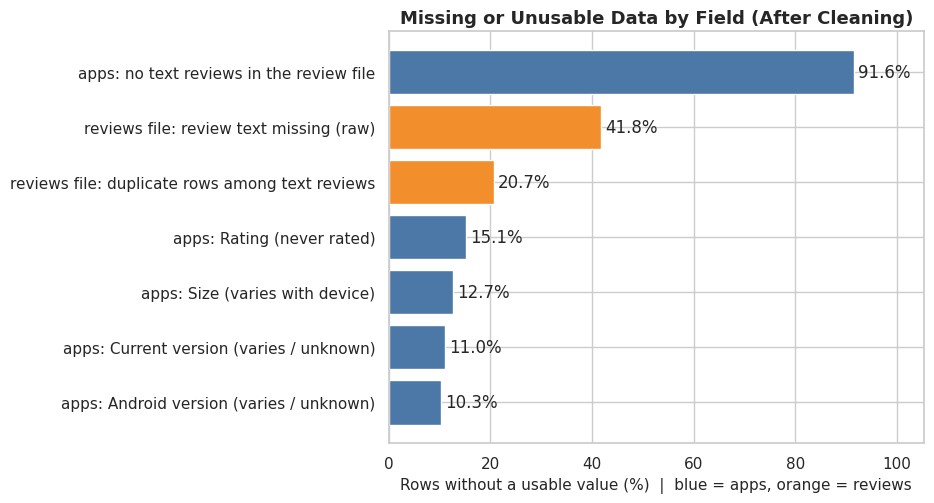

apps: no text reviews in the review file          91.60
reviews file: review text missing (raw)           41.80
reviews file: duplicate rows among text reviews   20.70
apps: Rating (never rated)                        15.10
apps: Size (varies with device)                   12.70
apps: Current version (varies / unknown)          11.00
apps: Android version (varies / unknown)          10.30

Rating status : {'Rated': 8196, 'No rating shown': 870, 'Never rated (0 reviews)': 593}
Rating reliability (all apps): {'Reliable (>= 100 reviews)': 6301, 'Thin (< 100 reviews)': 1895, 'Not rated': 1463}
Never-rated apps with 0 reviews: 593 | apps with reviews but no rating: 870
Reliable ratings (>= 100 reviews): 6,301 = 65.2% of apps and 76.9% of rated apps
Apps with text reviews: 816 (8.4% of apps)


In [13]:
# Share of each field with no usable value after cleaning (coded 'Varies with device' / 'Unknown' count as unusable).
gap = pd.Series({
    "apps: Rating (never rated)": apps["Rating"].isna().mean() * 100,
    "apps: Size (varies with device)": apps["Size_MB"].isna().mean() * 100,
    "apps: Current version (varies / unknown)": apps["Current_Ver"].isin(["Varies with device", "Unknown"]).mean() * 100,
    "apps: Android version (varies / unknown)": apps["Android_Ver"].isin(["Varies with device", "Unknown"]).mean() * 100,
    "apps: no text reviews in the review file": (apps["has_text_reviews"] == 0).mean() * 100,
    "reviews file: review text missing (raw)": reviews_raw["Translated_Review"].isna().mean() * 100,
    "reviews file: duplicate rows among text reviews": (1 - len(reviews) / reviews_raw["Translated_Review"].notna().sum()) * 100,
}).sort_values()
fig, ax = plt.subplots(figsize=(9.5, 5.2))
colors = [PALETTE_TYPE["Paid"] if l.startswith("reviews") else BASE_COLOR for l in gap.index]
ax.barh(gap.index, gap.values, color=colors)
ax.bar_label(ax.containers[0], labels=[f"{v:.1f}%" for v in gap.values], padding=3)
ax.set(title="Missing or Unusable Data by Field (After Cleaning)", xlabel="Rows without a usable value (%)  |  blue = apps, orange = reviews", ylabel="")
ax.set_xlim(0, gap.max() * 1.15)
fig.tight_layout()
save_fig(fig, "01_missing_values")

print(gap.sort_values(ascending=False).round(1).to_string())
print("\nRating status :", apps["rating_status"].value_counts().to_dict())
print("Rating reliability (all apps):", apps["rating_reliability"].value_counts().to_dict())
print("Never-rated apps with 0 reviews:", int((apps["Reviews"] == 0).sum()), "| apps with reviews but no rating:", int((apps["Rating"].isna() & (apps["Reviews"] > 0)).sum()))
print(f"Reliable ratings (>= {MIN_REVIEWS} reviews): {len(rel):,} = {len(rel) / len(apps):.1%} of apps and {len(rel) / len(rated):.1%} of rated apps")
print("Apps with text reviews:", int(apps["has_text_reviews"].sum()), f"({apps['has_text_reviews'].mean():.1%} of apps)")

**Why this chart:** Before trusting any average, we need to know how much of each field is actually usable. A bar chart of the gap per field shows where conclusions rest on partial data.

**Insight:** Most gaps are structural, not random. 15.1% of apps show no rating (593 have zero reviews and 870 have reviews but no displayed rating), 12.7% have a size that varies with device, 11.0% have an unknown or variable current version and 10.3% a variable Android version. Only 65.2% of apps (76.9% of rated apps) have a rating backed by at least 100 reviews. In the review file, 41.8% of raw rows have no text and 20.7% of the remaining rows are exact repeats. After cleaning, only 816 apps (8.4%) can be joined to written reviews.

**Business impact:** Negative. Rating-based comparisons rest on 65.2% of apps at best, and sentiment findings describe a small, non-random subset. Action: quote data coverage next to every KPI, use the 100-review rule for rankings, and collect review text for more apps before making category-level sentiment claims.

## 10. Univariate analysis — one variable at a time

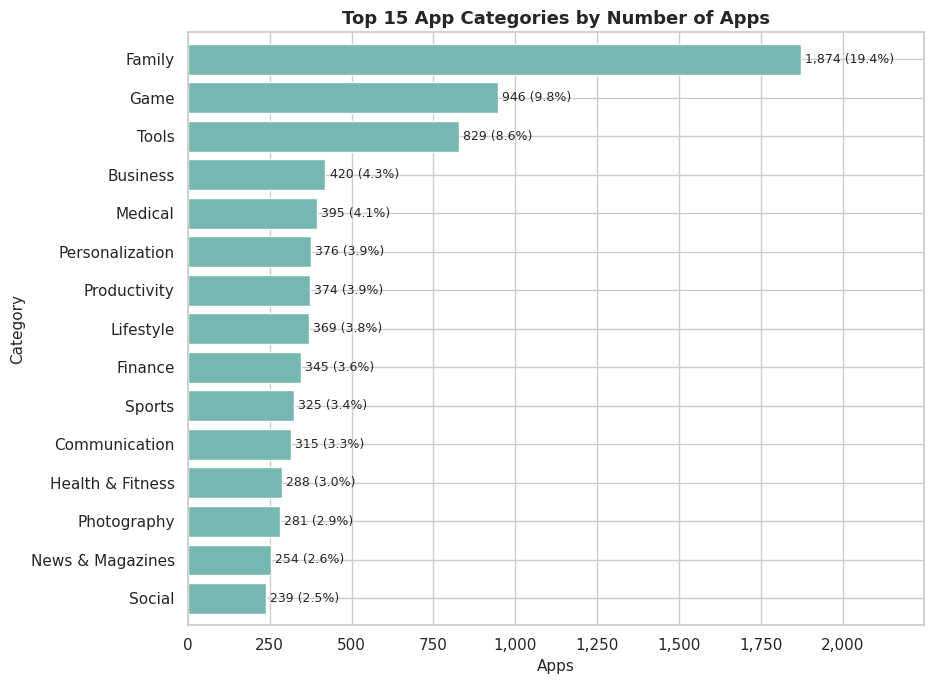

Categories: 33 | top 3: {'Family': 1874, 'Game': 946, 'Tools': 829}
Top 3 categories hold 37.8% of apps | top 5: 46.2% | top 10: 64.7%
Smallest categories: {'Events': 64, 'Art & Design': 61, 'Parenting': 60, 'Comics': 56, 'Beauty': 53}
Categories with fewer than 40 apps: 0 | with fewer than 40 reliable ratings: 3


In [14]:
cat_counts = apps["Category_Label"].value_counts()
plot_bar(cat_counts.head(15), "Top 15 App Categories by Number of Apps", "Apps", "Category", "02_top15_categories",
         color="#76B7B2", total=len(apps), figsize=(9.5, 7))

print(f"Categories: {len(cat_counts)} | top 3: {cat_counts.head(3).to_dict()}")
print(f"Top 3 categories hold {cat_counts.head(3).sum() / len(apps):.1%} of apps | top 5: {cat_counts.head(5).sum() / len(apps):.1%} | top 10: {cat_counts.head(10).sum() / len(apps):.1%}")
print("Smallest categories:", cat_counts.tail(5).to_dict())
print(f"Categories with fewer than {MIN_APPS} apps: {(cat_counts < MIN_APPS).sum()} | with fewer than {MIN_APPS} reliable ratings: {int((rel['Category_Label'].value_counts().reindex(cat_counts.index).fillna(0) < MIN_APPS).sum())}")

**Why this chart:** Category is the first way a store is organised and the first decision a publisher makes, so we need to know how the market is divided.

**Insight:** The store has 33 categories, but three of them hold 37.8% of apps: Family (1,874, or 19.4%), Game (946) and Tools (829). The top five hold 46.2% and the top ten 64.7%. The smallest categories are Beauty (53 apps), Comics (56) and Parenting (60). Every category has at least 40 apps, and only 3 of 33 have fewer than 40 reliably rated apps, so category comparisons are mostly on solid ground.

**Business impact:** Mixed. Family, Game and Tools are the most crowded places to launch, where a new app competes with the most alternatives. Smaller categories offer less competition but also a smaller audience. Action: judge a category on both size and quality of the existing apps (charts 16, 19 and 34) instead of picking the largest one.

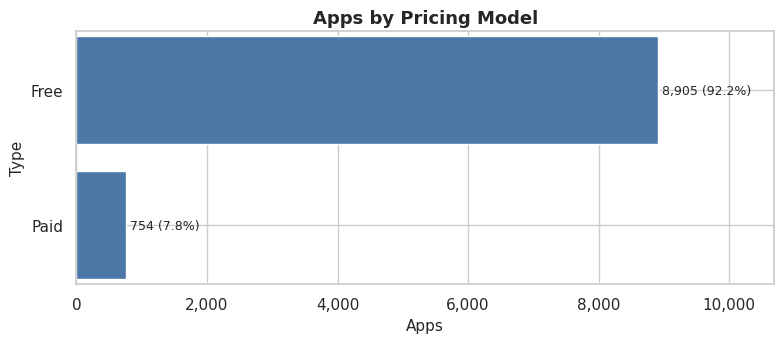

{'Free': 8905, 'Paid': 754} | paid share: 7.8% | free per paid app: 11.8
Median installs by type: {'Free': 100000.0, 'Paid': 1000.0}
Share with 1M+ installs by type (%): {'Free': 37.9, 'Paid': 2.9}
Median reviews by type: {'Free': 1379.0, 'Paid': 88.5}


In [15]:
type_counts = apps["Type"].value_counts().reindex(FREE_PAID)
plot_bar(type_counts, "Apps by Pricing Model", "Apps", "Type", "03_free_vs_paid", color=BASE_COLOR, figsize=(8, 3.6))

print(type_counts.to_dict(), "| paid share:", f"{apps['Is_Paid'].mean():.1%}", "| free per paid app:", round(type_counts["Free"] / type_counts["Paid"], 1))
print("Median installs by type:", apps.groupby("Type")["Installs_count"].median().to_dict())
print("Share with 1M+ installs by type (%):", (apps.groupby("Type")["Installs_count"].apply(lambda s: (s >= 1_000_000).mean() * 100)).round(1).to_dict())
print("Median reviews by type:", apps.groupby("Type")["Reviews"].median().to_dict())

**Why this chart:** Pricing model shapes revenue, audience and user behaviour, and later charts show that free and paid apps behave very differently.

**Insight:** 92.2% of apps are free (8,905) and 7.8% are paid (754), or 11.8 free apps for every paid one. Free apps have a median of 100,000 installs against 1,000 for paid apps, and 37.9% of free apps pass one million installs against 2.9% of paid apps. The median free app has 1,379 reviews against 88.5 for a paid app.

**Business impact:** Mixed. A paid app starts with a much smaller audience, so the paid route needs a clear niche or brand. Free apps carry the reach but need another way to earn (ads, subscriptions or in-app purchases, which this data does not show). Action: decide the monetisation route before launch and set install targets by pricing model.

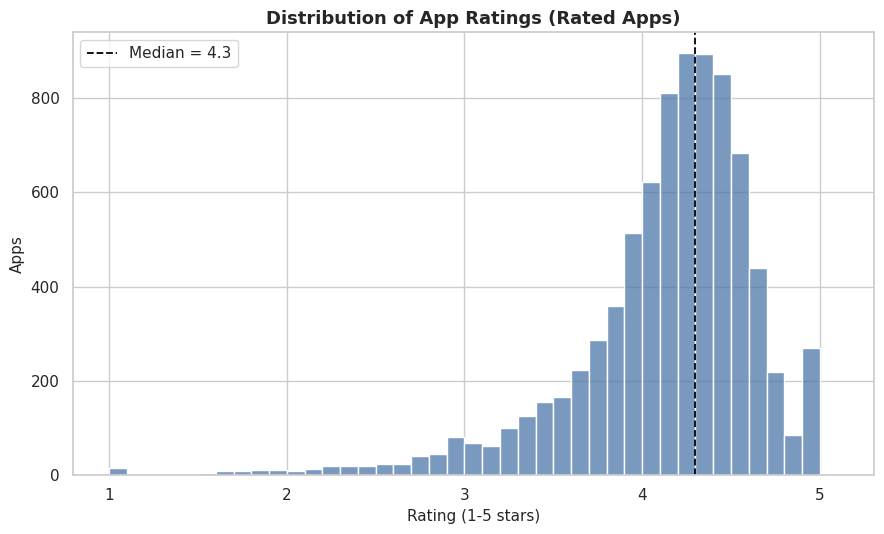

Rated apps: 8,196 (84.9%) | median 4.3 | mean 4.17 | std 0.54 | min 1.0 | max 5.0
Excellent (4.5+): 31.1% | good (4.0-4.4): 45.6% | low (<4.0): 23.3% (1,909 apps) | below 3: 278
Exactly 5.0: 271 (3.3%), of which with fewer than 30 reviews: 254
Reliable ratings (>= 100 reviews): median 4.3 | mean 4.20 | std 0.42 | 4.5+: 28.9% | below 4.0: 20.3% | 5.0: 4
Skewness (rated apps): -1.75 | share within 4.0-4.7: 69.7%


In [16]:
plot_hist(rated["Rating"], "Distribution of App Ratings (Rated Apps)", "Rating (1-5 stars)", "04_rating_distribution", bins=np.arange(1, 5.11, 0.1))

s = rated["Rating"]
print(f"Rated apps: {len(s):,} ({len(s) / len(apps):.1%}) | median {s.median():.1f} | mean {s.mean():.2f} | std {s.std():.2f} | min {s.min()} | max {s.max()}")
print(f"Excellent (4.5+): {(s >= 4.5).mean():.1%} | good (4.0-4.4): {s.between(4.0, 4.49).mean():.1%} | low (<4.0): {(s < 4.0).mean():.1%} ({(s < 4.0).sum():,} apps) | below 3: {(s < 3).sum():,}")
print(f"Exactly 5.0: {(s == 5).sum()} ({(s == 5).sum() / len(s):.1%}), of which with fewer than 30 reviews: {((rated['Rating'] == 5) & (rated['Reviews'] < 30)).sum()}")
print(f"Reliable ratings (>= {MIN_REVIEWS} reviews): median {rel['Rating'].median():.1f} | mean {rel['Rating'].mean():.2f} | std {rel['Rating'].std():.2f} | 4.5+: {(rel['Rating'] >= 4.5).mean():.1%} | below 4.0: {(rel['Rating'] < 4).mean():.1%} | 5.0: {(rel['Rating'] == 5).sum()}")
print("Skewness (rated apps):", round(s.skew(), 2), "| share within 4.0-4.7:", f"{s.between(4.0, 4.7).mean():.1%}")

**Why this chart:** The rating is the main quality signal on the store page, so its full distribution matters. A histogram shows whether ratings spread across the scale or bunch together.

**Insight:** Ratings are high and bunched. Among 8,196 rated apps the median is 4.3 and the mean 4.17 (standard deviation 0.54), the shape is strongly left-skewed (skewness −1.75), and 69.7% fall between 4.0 and 4.7. 31.1% score 4.5 or higher, 45.6% score 4.0–4.4 and 23.3% (1,909 apps) score below 4.0; 278 are below 3. There are 271 perfect 5.0 ratings, but 254 of them rest on fewer than 30 reviews and only 4 have 100 or more. Among reliable ratings (100+ reviews) the median is still 4.3 with a smaller spread (standard deviation 0.42).

**Business impact:** Mixed. A 4.3 is the norm, not a sign of excellence, so a 4.5 is only modestly better than the middle. Small-sample 5.0 ratings are noise. Action: benchmark against 4.3 rather than 5, and apply the 100-review rule to any ranking or shortlist.

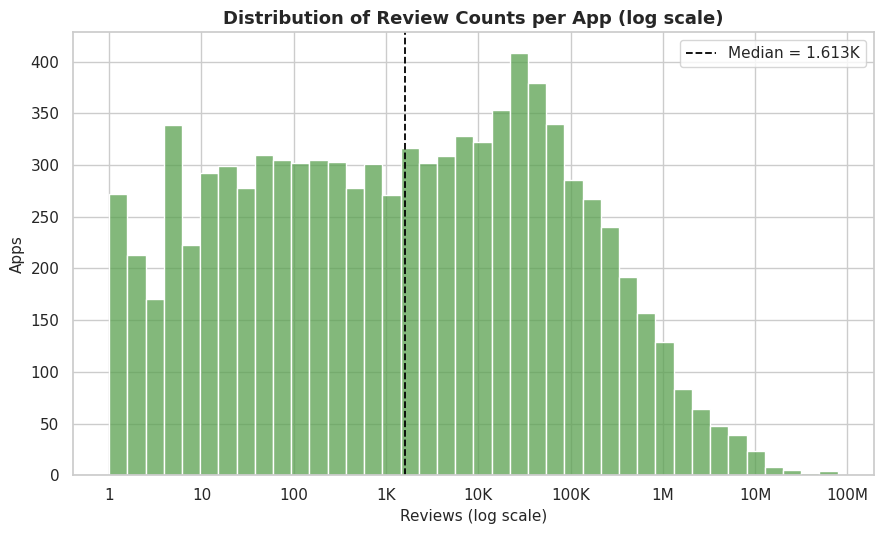

Apps: 9,659 | median 969 | mean 216,804 | 90th pct 223,099 | max 78,158,306 (Facebook)
Top 10% of apps hold 92.8% of all 2,094,110,902 reviews; top 1% hold 54.6%
Zero reviews: 593 (6.1%) | under 100: 3,325 (34.4%) | under 1,000: 50.2% | 100,000 or more: 1,451 | 1M or more: 350


In [17]:
plot_hist(apps["Reviews"], "Distribution of Review Counts per App (log scale)", "Reviews (log scale)", "05_reviews_log", bins=40, log_x=True, color="#59A14F")

v = apps["Reviews"]
top10 = v.nlargest(int(len(v) * 0.10)).sum() / v.sum()
top1 = v.nlargest(int(len(v) * 0.01)).sum() / v.sum()
print(f"Apps: {len(v):,} | median {v.median():,.0f} | mean {v.mean():,.0f} | 90th pct {v.quantile(.9):,.0f} | max {v.max():,} ({apps.loc[v.idxmax(), 'App']})")
print(f"Top 10% of apps hold {top10:.1%} of all {v.sum():,} reviews; top 1% hold {top1:.1%}")
print(f"Zero reviews: {(v == 0).sum():,} ({(v == 0).mean():.1%}) | under 100: {(v < 100).sum():,} ({(v < 100).mean():.1%}) | under 1,000: {(v < 1000).mean():.1%} | 100,000 or more: {(v >= 100_000).sum():,} | 1M or more: {(v >= 1_000_000).sum()}")

**Why this chart:** Review count measures how many people engaged with an app. A log axis is needed because a handful of apps have tens of millions of reviews while most have very few.

**Insight:** Attention is extremely concentrated. The median app has 969 reviews but the mean is 216,804, and the maximum is 78,158,306 (Facebook). The top 10% of apps hold 92.8% of all 2.09 billion reviews and the top 1% hold 54.6%. 593 apps (6.1%) have no reviews, 34.4% have fewer than 100 and 50.2% have fewer than 1,000, while 1,451 apps pass 100,000 and 350 pass one million.

**Business impact:** Negative for newcomers. Half of the market is nearly invisible in the review signal, and ratings for the 34.4% with under 100 reviews are too noisy to trust. Action: use the minimum-reviews rule for rankings, and plan early user-feedback drives, because reaching a few hundred reviews is what makes an app's rating credible.

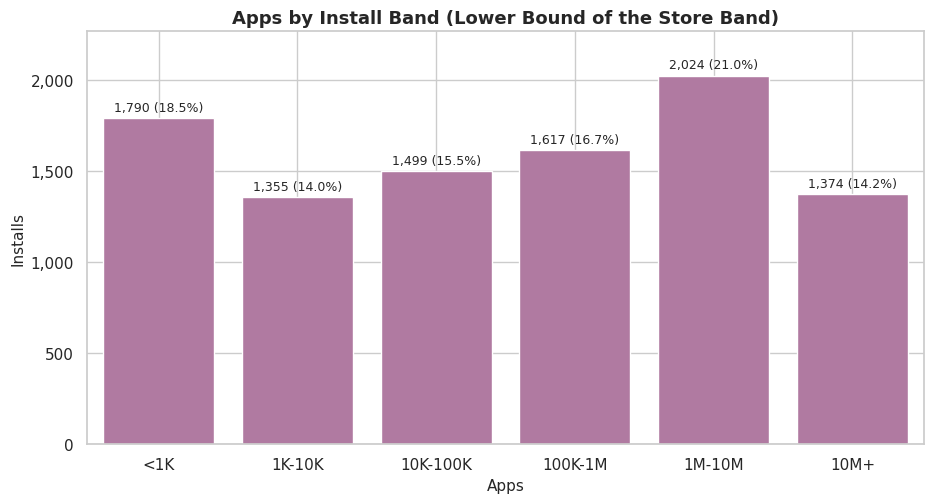

{'<1K': 1790, '1K-10K': 1355, '10K-100K': 1499, '100K-1M': 1617, '1M-10M': 2024, '10M+': 1374}
Median installs 100,000 | mean 7,798,170 | 1M+ installs: 3,398 (35.2%) | 10M+: 1,374 (14.2%) | 100M+: 233 | 1B+: 20
Under 1,000 installs: 1,790 (18.5%) | under 10,000: 32.6% | 0-10 installs: 549
Approximate share of all installs (band lower bounds) held by apps with 10M+ installs: 93.6% | by the top 1% of apps: 49.4%


In [18]:
band_counts = apps["Install_Band"].value_counts().reindex(INSTALL_BAND_ORDER)
plot_bar(band_counts, "Apps by Install Band (Lower Bound of the Store Band)", "Apps", "Installs", "06_install_bands", horizontal=False, color="#B07AA1", figsize=(9.5, 5.2))

i = apps["Installs_count"]
print(band_counts.to_dict())
print(f"Median installs {i.median():,.0f} | mean {i.mean():,.0f} | 1M+ installs: {(i >= 1_000_000).sum():,} ({(i >= 1_000_000).mean():.1%}) | 10M+: {(i >= 10_000_000).sum():,} ({(i >= 10_000_000).mean():.1%}) | 100M+: {(i >= 100_000_000).sum()} | 1B+: {(i >= 1_000_000_000).sum()}")
print(f"Under 1,000 installs: {(i < 1000).sum():,} ({(i < 1000).mean():.1%}) | under 10,000: {(i < 10_000).mean():.1%} | 0-10 installs: {(i <= 10).sum()}")
print("Approximate share of all installs (band lower bounds) held by apps with 10M+ installs:", f"{i[i >= 10_000_000].sum() / i.sum():.1%}", "| by the top 1% of apps:", f"{i.nlargest(int(len(i) * .01)).sum() / i.sum():.1%}")

**Why this chart:** Installs measure reach. The store only publishes bands, so the chart shows how apps spread across the bands (each app is placed at the band's lower bound).

**Insight:** Apps are spread fairly evenly across the bands, but the volume is not. 3,398 apps (35.2%) have at least one million installs, 1,374 (14.2%) have 10 million or more, 233 pass 100 million and 20 reach a billion. At the other end, 1,790 apps (18.5%) have under 1,000 installs and 32.6% have under 10,000. Apps with 10M+ installs account for about 93.6% of all install-band volume, and the top 1% of apps for 49.4%.

**Business impact:** Mixed. Reaching a million installs is achievable for a third of apps in this dataset, but the total audience sits with a few hundred giants. Shares here describe this dataset of listings only. Action: set realistic milestones (10K, 100K, 1M) and compare progress with the category (chart 31), not with the giants.

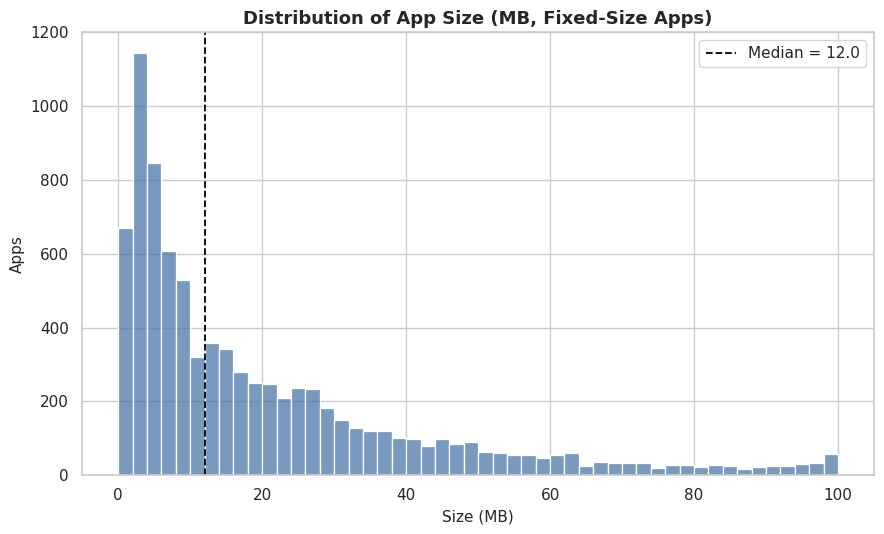

Apps with a fixed size: 8,431 (87.3%) | 'Varies with device': 1,228 (12.7%)
Median 12.0 MB | mean 20.4 | 25th-75th pct 4.6-28.0 | min 0.01 | max 100
Under 5 MB: 26.8% | 5-25 MB: 43.3% | 25 MB or more: 29.9% | exactly 100 MB (store cap): 14 (0.2%)
Size band counts: {'<5 MB': 2263, '5-10 MB': 1529, '10-25 MB': 2120, '25-50 MB': 1607, '50+ MB': 912}


In [19]:
plot_hist(apps["Size_MB"], "Distribution of App Size (MB, Fixed-Size Apps)", "Size (MB)", "07_size_distribution", bins=np.arange(0, 102, 2))

z = apps["Size_MB"].dropna()
print(f"Apps with a fixed size: {len(z):,} ({len(z) / len(apps):.1%}) | 'Varies with device': {apps['Size_MB'].isna().sum():,} ({apps['Size_MB'].isna().mean():.1%})")
print(f"Median {z.median():.1f} MB | mean {z.mean():.1f} | 25th-75th pct {z.quantile(.25):.1f}-{z.quantile(.75):.1f} | min {z.min():.2f} | max {z.max():.0f}")
print(f"Under 5 MB: {(z < 5).mean():.1%} | 5-25 MB: {z.between(5, 24.99).mean():.1%} | 25 MB or more: {(z >= 25).mean():.1%} | exactly 100 MB (store cap): {(z == 100).sum()} ({(z == 100).mean():.1%})")
print("Size band counts:", apps["Size_Band"].value_counts().reindex(SIZE_BAND_ORDER).to_dict())

**Why this chart:** App size affects download friction, storage and the devices an app can serve. A histogram shows the usual size and the extremes.

**Insight:** 12.7% of apps hide their size ('Varies with device'). Among the 8,431 apps with a fixed size the median is 12.0 MB and the mean 20.4 MB; the middle half run from 4.6 to 28.0 MB. 26.8% are under 5 MB and 29.9% are 25 MB or more. The distribution has a long right tail that is capped at 100 MB: 14 apps sit exactly at that ceiling, which is a store display limit and not a real maximum.

**Business impact:** Neutral. Most apps are light, so a large size is a deliberate choice, usually for games (chart 21). Action: treat 100 MB as a censored value (the true size may be larger) and do not use it as a measure of quality.

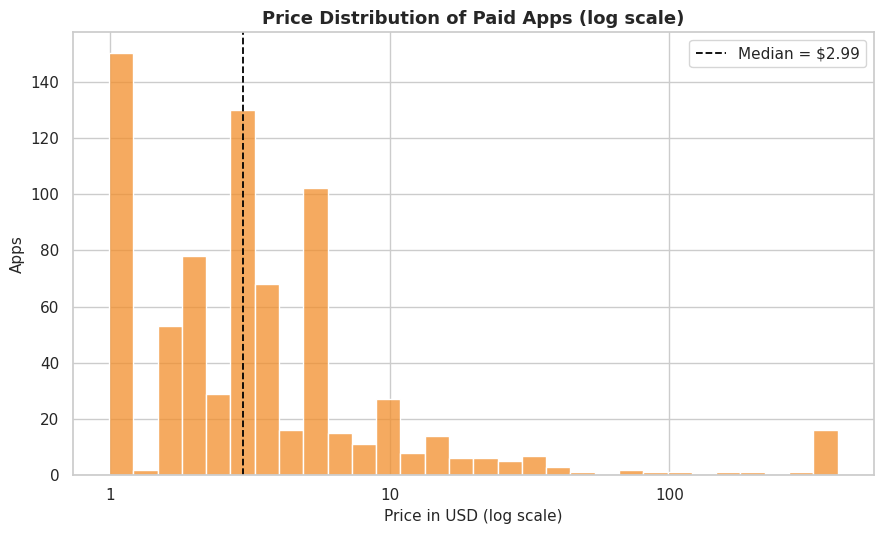

Paid apps: 754 (7.8%) | median $2.99 | mean $14.06 | 25th-75th pct $1.49-$4.99 | max $400.00
Under $1: 145 | up to $2.99: 58.1% | up to $4.99: 79.0% | above $10: 73 (9.7%) | $100 or more: 20
Most common price points: {0.99: 145, 2.99: 124, 1.99: 73, 4.99: 70, 3.99: 57, 1.49: 46}
Price band counts: {'<= $1': 148, '$1-2': 135, '$2-5': 314, '$5-10': 84, '$10+': 73}
Novelty-priced apps ($100+): ['most expensive app (H)', "💎 I'm rich", "I'm Rich - Trump Edition", 'I am rich', 'I am Rich Plus', 'I am rich VIP'] ...


In [20]:
plot_hist(paid["Price_USD"], "Price Distribution of Paid Apps (log scale)", "Price in USD (log scale)", "08_paid_price_log", bins=30, log_x=True, color="#F28E2B",
          ref_label=f"Median = ${paid['Price_USD'].median():.2f}")

p = paid["Price_USD"]
print(f"Paid apps: {len(p):,} ({len(p) / len(apps):.1%}) | median ${p.median():.2f} | mean ${p.mean():.2f} | 25th-75th pct ${p.quantile(.25):.2f}-${p.quantile(.75):.2f} | max ${p.max():.2f}")
print(f"Under $1: {(p < 1).sum()} | up to $2.99: {(p <= 2.99).mean():.1%} | up to $4.99: {(p <= 4.99).mean():.1%} | above $10: {(p > 10).sum()} ({(p > 10).mean():.1%}) | $100 or more: {(p >= 100).sum()}")
print("Most common price points:", p.value_counts().head(6).round(2).to_dict())
print("Price band counts:", paid["Price_Band"].value_counts().reindex(PRICE_BAND_ORDER).to_dict())
print("Novelty-priced apps ($100+):", paid.loc[paid["Price_USD"] >= 100, "App"].tolist()[:6], "...")

**Why this chart:** Price sets the entry barrier for paid apps. A log axis shows both the common low prices and the rare extreme ones.

**Insight:** There are 754 paid apps. The median price is $2.99 while the mean is $14.06, pulled up by outliers. The middle half cost $1.49 to $4.99, 58.1% cost $2.99 or less and 79.0% cost $4.99 or less. The most common price points are $0.99 (145 apps), $2.99 (124), $1.99 (73) and $4.99 (70). 73 apps (9.7%) cost more than $10 and 20 cost $100 or more; these are mostly 'I am rich' style novelty apps.

**Business impact:** Mixed. Users are used to paying a few dollars at most, so pricing above $5 needs strong justification. Action: use the median ($2.99) and the common price points as anchors, report medians instead of means for price, and exclude the novelty apps when studying willingness to pay.

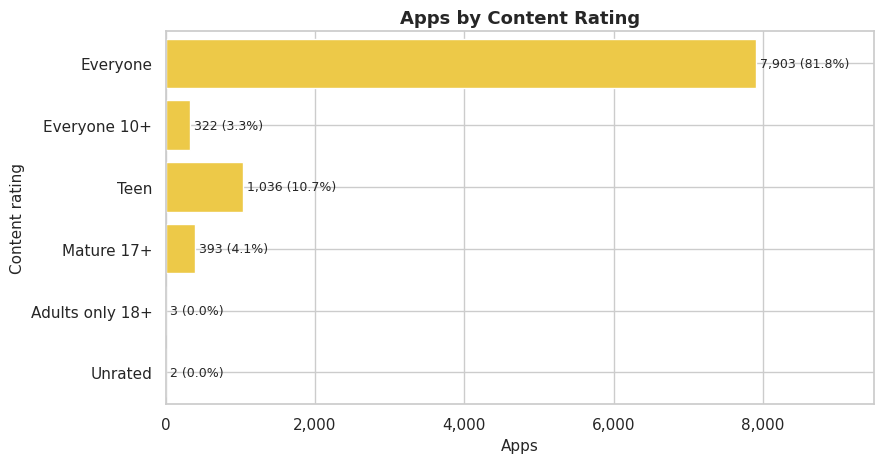

{'Everyone': 7903, 'Everyone 10+': 322, 'Teen': 1036, 'Mature 17+': 393, 'Adults only 18+': 3, 'Unrated': 2}
Everyone: 81.8% | Everyone + Everyone 10+: 85.2% | Teen: 10.7% | Mature 17+ and Adults only: 4.1%
Median installs by content rating: {'Everyone': 50000.0, 'Everyone 10+': 1000000.0, 'Teen': 500000.0, 'Mature 17+': 500000.0, 'Adults only 18+': 500000.0, 'Unrated': 25250.0}


In [21]:
cr_counts = apps["Content_Rating"].value_counts().reindex(CONTENT_ORDER)
plot_bar(cr_counts, "Apps by Content Rating", "Apps", "Content rating", "09_content_rating", color="#EDC948", figsize=(9, 4.8))

print(cr_counts.to_dict())
print(f"Everyone: {cr_counts['Everyone'] / len(apps):.1%} | Everyone + Everyone 10+: {(cr_counts['Everyone'] + cr_counts['Everyone 10+']) / len(apps):.1%} | Teen: {cr_counts['Teen'] / len(apps):.1%} | Mature 17+ and Adults only: {(cr_counts['Mature 17+'] + cr_counts['Adults only 18+']) / len(apps):.1%}")
print("Median installs by content rating:", apps.groupby("Content_Rating")["Installs_count"].median().reindex(CONTENT_ORDER).to_dict())

**Why this chart:** Content rating shows who the apps are for and how much of the store is open to families. A bar chart gives the split.

**Insight:** 81.8% of apps (7,903) are rated Everyone and 85.2% are Everyone or Everyone 10+. Teen holds 10.7% (1,036), Mature 17+ 4.1% (393 apps) and Adults only 18+ just 3 apps; 2 apps are unrated. Median installs are highest for Everyone 10+ (1,000,000), Teen and Mature 17+ (500,000 each), and lowest for Everyone (50,000) among the large groups, because the Everyone group is huge and contains many small niche apps.

**Business impact:** Neutral to positive. The store is overwhelmingly family-friendly, which keeps the addressable audience wide. Action: treat Everyone as the default and use Teen or Mature ratings only where the product needs them (for example games or dating), since their groups are small and behave differently.

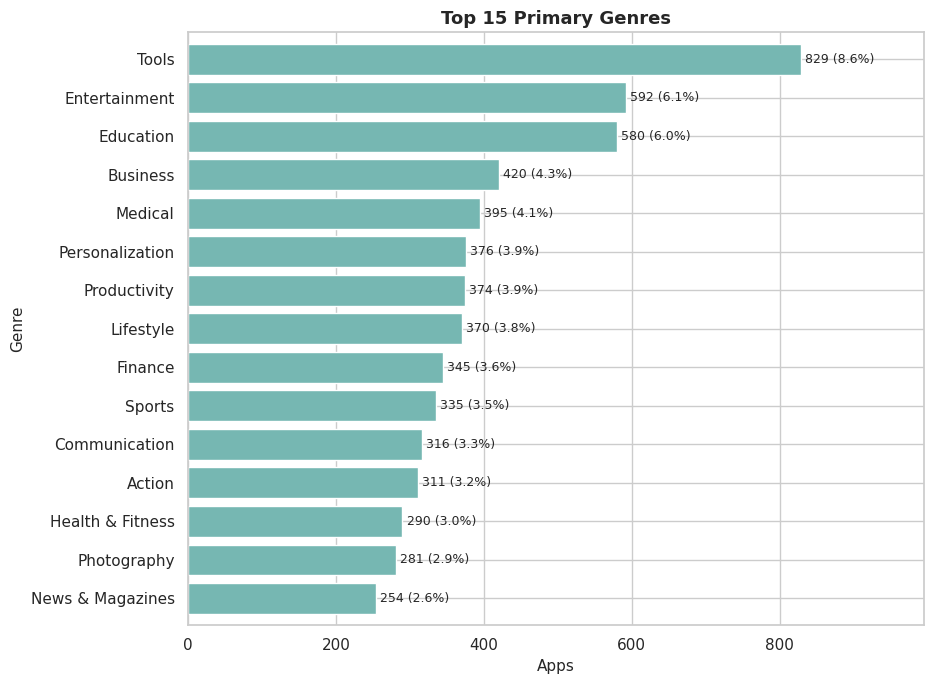

Distinct primary genres: 48 | apps with a second genre: 392 (4.1%)
Top 5: {'Tools': 829, 'Entertainment': 592, 'Education': 580, 'Business': 420, 'Medical': 395}
Top 10 genres hold 47.8% of apps | genres with fewer than 10 apps: 1 of 48
Genres per category (top 4): {'FAMILY': 24, 'GAME': 16, 'ART_AND_DESIGN': 1, 'AUTO_AND_VEHICLES': 1}
Games split into 16 genres; largest: {'Action': 300, 'Arcade': 184, 'Racing': 91, 'Adventure': 73}


In [22]:
genre_counts = apps["Primary_Genre"].value_counts()
plot_bar(genre_counts.head(15), "Top 15 Primary Genres", "Apps", "Genre", "10_top15_genres", color="#76B7B2", total=len(apps), figsize=(9.5, 7))

print(f"Distinct primary genres: {len(genre_counts)} | apps with a second genre: {(apps['n_genres'] > 1).sum()} ({(apps['n_genres'] > 1).mean():.1%})")
print("Top 5:", genre_counts.head(5).to_dict())
print(f"Top 10 genres hold {genre_counts.head(10).sum() / len(apps):.1%} of apps | genres with fewer than 10 apps: {(genre_counts < 10).sum()} of {len(genre_counts)}")
print("Genres per category (top 4):", apps.groupby("Category")["Primary_Genre"].nunique().sort_values(ascending=False).head(4).to_dict())
print("Games split into", apps.loc[apps["Is_Game"] == 1, "Primary_Genre"].nunique(), "genres; largest:", apps.loc[apps["Is_Game"] == 1, "Primary_Genre"].value_counts().head(4).to_dict())

**Why this chart:** Genre is a finer view than category and shows what kind of apps the store really contains.

**Insight:** There are 48 primary genres. Tools (829), Entertainment (592), Education (580), Business (420) and Medical (395) lead, and the top ten hold 47.8% of apps. Only 4.1% of apps list a second genre. Genres are more detailed inside Family (24 genres) and Game (16 genres, led by Action with 300 apps and Arcade with 184), while most other categories have a single genre, so category and genre carry the same information for them.

**Business impact:** Mixed. Family and Game are really collections of sub-markets, so their averages hide big differences. Action: analyse Game and Family by genre before drawing conclusions, and use category for everything else.

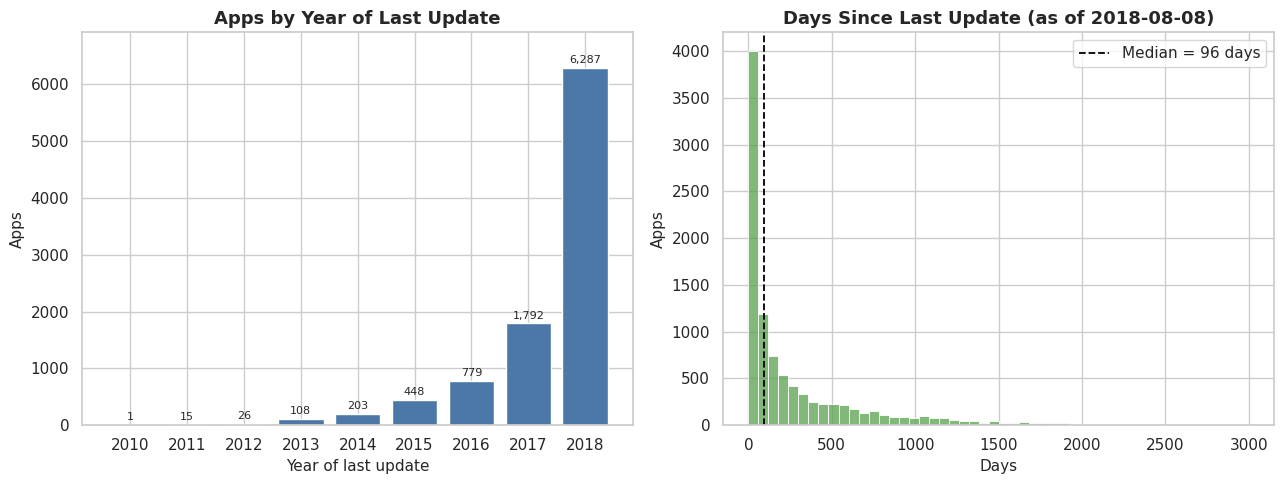

Updates span 2010-05-21 to 2018-08-08 | median 96 days since update | mean 281
Updated in the last 30 days: 30.4% | last 180 days: 61.3% | last year: 75.0% | more than 2 years ago: 1,211 (12.5%) | more than 3 years: 591
Update year counts: {2010: 1, 2011: 15, 2012: 26, 2013: 108, 2014: 203, 2015: 448, 2016: 779, 2017: 1792, 2018: 6287}
Update recency shares (%): {'Last 30 days': 30.4, '1-6 months': 30.9, '6-12 months': 13.7, 'Over 1 year': 25.0}


In [23]:
upd = apps["Last_Updated"].dt.year.value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(upd.index.astype(str), upd.values, color=BASE_COLOR)
axes[0].bar_label(axes[0].containers[0], labels=[f"{v:,}" for v in upd.values], padding=2, fontsize=8)
axes[0].set(title="Apps by Year of Last Update", xlabel="Year of last update", ylabel="Apps")
axes[0].margins(y=0.1)
sns.histplot(apps["Days_Since_Update"], bins=50, color="#59A14F", edgecolor="white", ax=axes[1])
axes[1].axvline(apps["Days_Since_Update"].median(), color="black", ls="--", lw=1.3, label=f"Median = {apps['Days_Since_Update'].median():.0f} days")
axes[1].set(title=f"Days Since Last Update (as of {SNAPSHOT_DATE.date()})", xlabel="Days", ylabel="Apps")
axes[1].legend(frameon=True)
fig.tight_layout()
save_fig(fig, "11_update_recency")

d_ = apps["Days_Since_Update"]
print(f"Updates span {apps['Last_Updated'].min().date()} to {apps['Last_Updated'].max().date()} | median {d_.median():.0f} days since update | mean {d_.mean():.0f}")
print(f"Updated in the last 30 days: {(d_ <= 30).mean():.1%} | last 180 days: {(d_ <= 180).mean():.1%} | last year: {(d_ <= 365).mean():.1%} | more than 2 years ago: {(d_ > 730).sum():,} ({(d_ > 730).mean():.1%}) | more than 3 years: {(d_ > 1095).sum():,}")
print("Update year counts:", upd.to_dict())
print("Update recency shares (%):", (apps["Update_Recency"].value_counts(normalize=True).reindex(["Last 30 days", "1-6 months", "6-12 months", "Over 1 year"]) * 100).round(1).to_dict())

**Why this chart:** Update recency shows how actively apps are maintained. Two panels show when apps were last updated and how many days before the 8 August 2018 snapshot that was.

**Insight:** The data is a 2018 snapshot: 6,287 apps (65.1%) were last updated in 2018 and 1,792 in 2017, with a long tail back to 2010. The median app was updated 96 days before the snapshot. 30.4% were updated in the last 30 days, 61.3% in the last 180 days and 75.0% in the last year, so 25.0% have not been updated for over a year. 1,211 apps (12.5%) have gone over two years without an update and 591 over three.

**Business impact:** Mixed. Most apps are actively maintained, but a quarter are effectively dormant. Action: track update recency as a health metric, and treat a dormant app as an at-risk asset (the next charts show it is linked to lower ratings and reach).

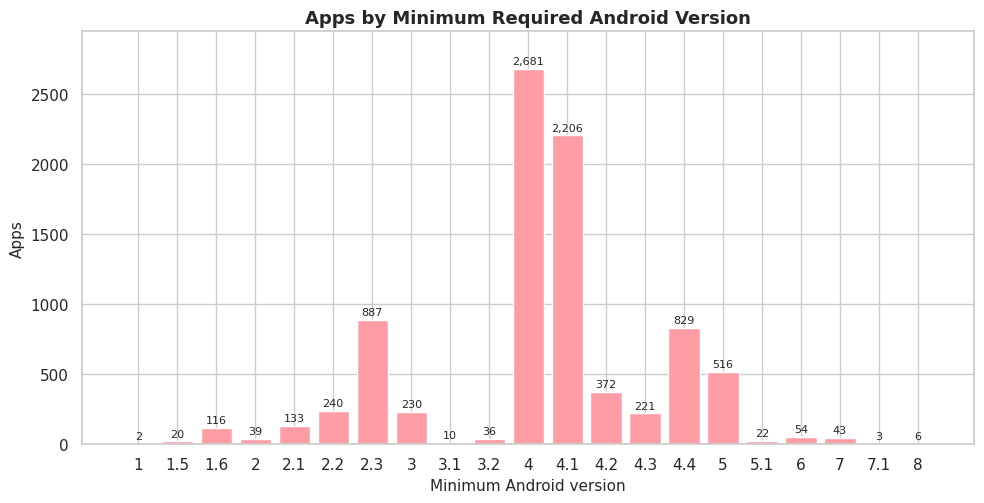

Apps with a known minimum version: 8,666 (89.7%) | 'Varies with device' / unknown: 993
Top versions (%): {4.0: 30.9, 4.1: 25.5, 2.3: 10.2, 4.4: 9.6, 5.0: 6.0}
Requiring 4.0 or newer: 80.2% | 4.1 or newer: 49.3% | 5.0 or newer: 7.4% | below 4.0: 1,713 (19.8%) | 2.x only: 16.6%
Median minimum version by update year: {2010: 1.5, 2011: 1.6, 2012: 2.1, 2013: 2.2, 2014: 2.3, 2015: 2.3, 2016: 4.0, 2017: 4.0, 2018: 4.1}


In [24]:
av = apps["Min_Android"].dropna()
av_counts = av.value_counts().sort_index()
av_counts = av_counts[av_counts.index >= 1.0]
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.bar([f"{k:g}" for k in av_counts.index], av_counts.values, color="#FF9DA7")
ax.bar_label(ax.containers[0], labels=[f"{v:,}" for v in av_counts.values], padding=2, fontsize=8)
ax.set(title="Apps by Minimum Required Android Version", xlabel="Minimum Android version", ylabel="Apps")
ax.margins(y=0.1)
fig.tight_layout()
save_fig(fig, "12_min_android_version")

print(f"Apps with a known minimum version: {len(av):,} ({len(av) / len(apps):.1%}) | 'Varies with device' / unknown: {apps['Min_Android'].isna().sum():,}")
print("Top versions (%):", (av.value_counts(normalize=True).head(5) * 100).round(1).to_dict())
print(f"Requiring 4.0 or newer: {(av >= 4.0).mean():.1%} | 4.1 or newer: {(av >= 4.1).mean():.1%} | 5.0 or newer: {(av >= 5.0).mean():.1%} | below 4.0: {(av < 4.0).sum():,} ({(av < 4.0).mean():.1%}) | 2.x only: {(av < 3).mean():.1%}")
print("Median minimum version by update year:", apps.groupby("Update_Year")["Min_Android"].median().to_dict())

**Why this chart:** The minimum Android version decides how many devices can run an app, and shows how quickly developers drop old versions.

**Insight:** For the 8,666 apps with a known version, Android 4.0 (30.9%) and 4.1 (25.5%) are the most common minimums, followed by 2.3 (10.2%), 4.4 (9.6%) and 5.0 (6.0%). 80.2% require 4.0 or newer, 49.3% require 4.1 or newer and only 7.4% require 5.0 or newer, while 16.6% still support Android 2.x. The median minimum version rises from 2.3 for apps last updated in 2015 to 4.0 for 2016–17 and 4.1 for 2018.

**Business impact:** Positive for reach. Most apps already require Android 4.0 or newer, so old-version support is the exception, not the norm. Action: choose the minimum version from current device share, not from habit; supporting very old versions adds maintenance and little audience.

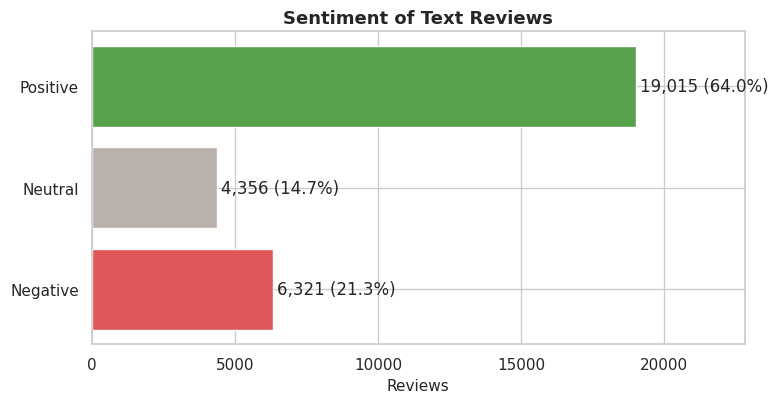

{'Positive': 19015, 'Neutral': 4356, 'Negative': 6321} | positive per negative review: 3.01
Reviews: 29,692 | apps: 865 | reviews per app: median 35, max 130
Mean polarity by label: {'Positive': 0.383, 'Neutral': 0.0, 'Negative': -0.264}
Apps where more than 90% of text reviews are positive: 53 | more than 40% negative: 87
Reviews per app - apps with the most reviews in the file: {'Facebook': 130, 'Episode - Choose Your Story': 124, 'Angry Birds Classic': 107}


In [25]:
sent_counts = reviews["Sentiment"].value_counts().reindex(SENTIMENT_ORDER)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(SENTIMENT_ORDER, sent_counts.values, color=[PALETTE_SENT[s] for s in SENTIMENT_ORDER])
ax.invert_yaxis()
ax.bar_label(ax.containers[0], labels=[f"{v:,} ({v / len(reviews):.1%})" for v in sent_counts.values], padding=3)
ax.set(title="Sentiment of Text Reviews", xlabel="Reviews", ylabel="")
ax.margins(x=0.2)
fig.tight_layout()
save_fig(fig, "13_sentiment_distribution")

print(sent_counts.to_dict(), "| positive per negative review:", round(sent_counts["Positive"] / sent_counts["Negative"], 2))
print(f"Reviews: {len(reviews):,} | apps: {reviews['App'].nunique()} | reviews per app: median {reviews.groupby('App').size().median():.0f}, max {reviews.groupby('App').size().max()}")
print("Mean polarity by label:", reviews.groupby("Sentiment", observed=True)["Sentiment_Polarity"].mean().round(3).to_dict())
print("Apps where more than 90% of text reviews are positive:", int((apps["pct_positive"] > 90).sum()), "| more than 40% negative:", int((apps["pct_negative"] > 40).sum()))
print("Reviews per app - apps with the most reviews in the file:", reviews["App"].value_counts().head(3).to_dict())

**Why this chart:** Sentiment is the second dataset's key measure. A bar chart shows how positive, neutral and negative the written reviews are.

**Insight:** Reviews are mostly positive: 19,015 (64.0%) are positive, 4,356 (14.7%) neutral and 6,321 (21.3%) negative, or 3.0 positive reviews per negative one. The file covers 865 apps with a median of 35 reviews each (maximum 130). Mean polarity is +0.383 for positive reviews and −0.264 for negative ones. 53 apps have more than 90% positive reviews and 87 apps have more than 40% negative reviews.

**Business impact:** Positive overall. Users write more praise than complaints in this sample. Caveat: the file has roughly 35 reviews per app, so app-level percentages are noisy. Action: monitor the negative share by app and category as a standing metric.

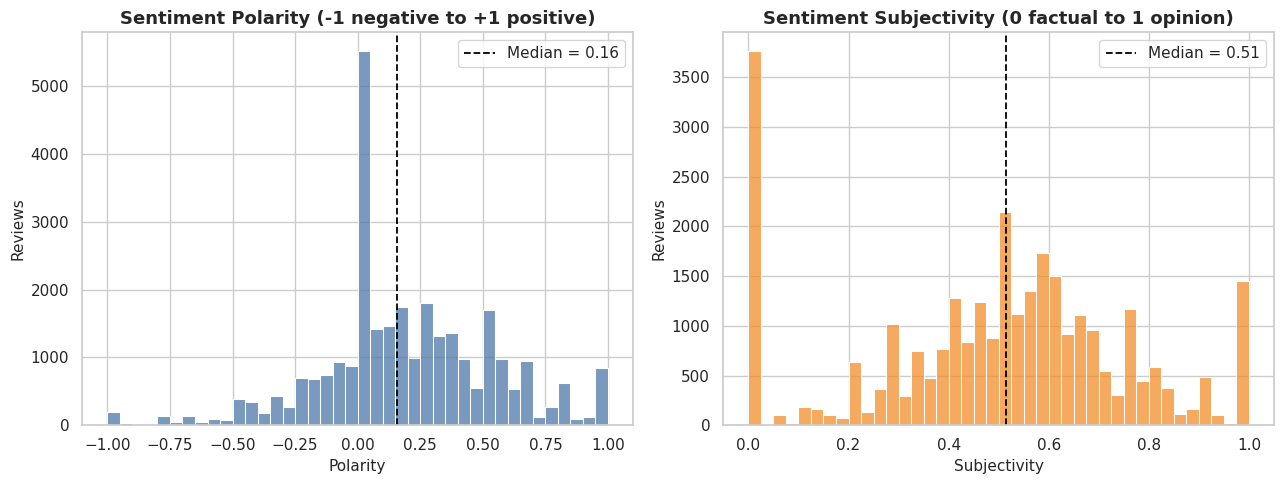

Polarity: mean 0.189 | median 0.16 | std 0.356 | exactly 0: 14.7% | above 0.5: 16.7% | below -0.5: 2.6% | at +1: 814 | at -1: 190
Subjectivity: mean 0.491 | median 0.51 | exactly 0: 12.7% | above 0.5: 51.4% | exactly 1: 1,448
Review length (words): median 13 | mean 17.3 | 90th pct 38 | max 345
Median words by sentiment: {'Positive': 14.0, 'Neutral': 5.5, 'Negative': 18.0}
Spearman(polarity, subjectivity): 0.364 | mean subjectivity by label: {'Positive': 0.57, 'Neutral': 0.077, 'Negative': 0.538}


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(reviews["Sentiment_Polarity"], bins=40, color=BASE_COLOR, edgecolor="white", ax=axes[0])
axes[0].axvline(reviews["Sentiment_Polarity"].median(), color="black", ls="--", lw=1.3, label=f"Median = {reviews['Sentiment_Polarity'].median():.2f}")
axes[0].set(title="Sentiment Polarity (-1 negative to +1 positive)", xlabel="Polarity", ylabel="Reviews")
axes[0].legend(frameon=True)
sns.histplot(reviews["Sentiment_Subjectivity"], bins=40, color="#F28E2B", edgecolor="white", ax=axes[1])
axes[1].axvline(reviews["Sentiment_Subjectivity"].median(), color="black", ls="--", lw=1.3, label=f"Median = {reviews['Sentiment_Subjectivity'].median():.2f}")
axes[1].set(title="Sentiment Subjectivity (0 factual to 1 opinion)", xlabel="Subjectivity", ylabel="Reviews")
axes[1].legend(frameon=True)
fig.tight_layout()
save_fig(fig, "14_polarity_subjectivity")

po, su = reviews["Sentiment_Polarity"], reviews["Sentiment_Subjectivity"]
print(f"Polarity: mean {po.mean():.3f} | median {po.median():.2f} | std {po.std():.3f} | exactly 0: {(po == 0).mean():.1%} | above 0.5: {(po > 0.5).mean():.1%} | below -0.5: {(po < -0.5).mean():.1%} | at +1: {(po == 1).sum():,} | at -1: {(po == -1).sum():,}")
print(f"Subjectivity: mean {su.mean():.3f} | median {su.median():.2f} | exactly 0: {(su == 0).mean():.1%} | above 0.5: {(su > 0.5).mean():.1%} | exactly 1: {(su == 1).sum():,}")
print(f"Review length (words): median {reviews['Word_Count'].median():.0f} | mean {reviews['Word_Count'].mean():.1f} | 90th pct {reviews['Word_Count'].quantile(.9):.0f} | max {reviews['Word_Count'].max()}")
print("Median words by sentiment:", reviews.groupby("Sentiment", observed=True)["Word_Count"].median().to_dict())
print("Spearman(polarity, subjectivity):", round(po.corr(su, method="spearman"), 3), "| mean subjectivity by label:", reviews.groupby("Sentiment", observed=True)["Sentiment_Subjectivity"].mean().round(3).to_dict())

**Why this chart:** Polarity says how positive or negative a review is, and subjectivity says how opinionated it is. Two histograms show both scales.

**Insight:** Polarity is centred slightly above zero (mean 0.189, median 0.16). 14.7% of reviews are exactly neutral, 16.7% score above +0.5 and only 2.6% below −0.5; 814 reviews sit at +1 and 190 at −1. Subjectivity has a mean of 0.491, with 51.4% above 0.5 and 12.7% at zero. Reviews are short (median 13 words), and negative reviews are longer (median 18 words) than positive ones (14) and neutral ones (5.5). Polarity and subjectivity are moderately linked (rank correlation 0.36).

**Business impact:** Neutral. Strongly negative reviews are rare, so most complaints are mild. Longer negative reviews hold more detail, which makes them the most useful for product fixes. Action: read negative reviews first, and weight them by length when looking for concrete issues.

## 11. Bivariate analysis — numerical vs categorical

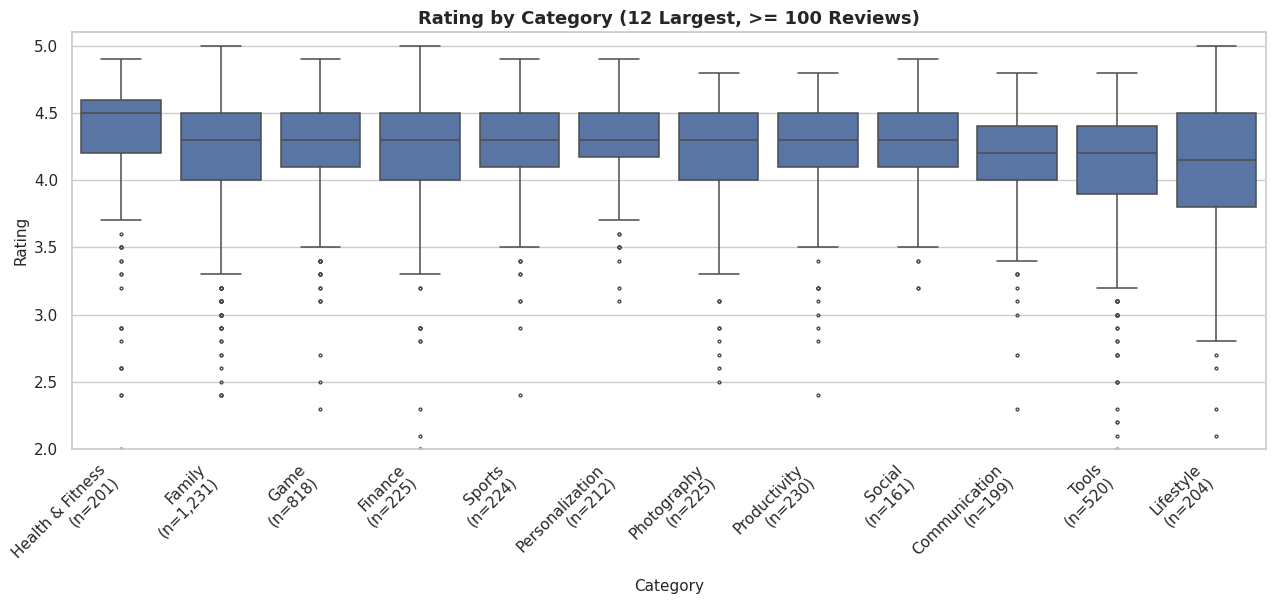

,n,median,mean,p10,share_4.5+_%,share_below_4_%
Category_Label,,,,,,
Health & Fitness,201,4.50,4.30,3.70,51.74,13.93
Family,1231,4.30,4.17,3.60,26.40,23.15
Game,818,4.30,4.25,3.80,29.46,15.16
Finance,225,4.30,4.16,3.54,32.44,23.11
Sports,224,4.30,4.25,3.90,32.14,16.96
Personalization,212,4.30,4.31,4.00,34.43,8.96
Photography,225,4.30,4.19,3.74,25.78,15.56
Productivity,230,4.30,4.24,3.89,29.57,13.48
Social,161,4.30,4.29,3.90,31.06,11.18


Reliable-rating median for all apps: 4.3 | best-to-worst median gap among the 12: 0.35


In [27]:
top12 = list(rel["Category_Label"].value_counts().head(12).index)
gdata = rel[rel["Category_Label"].isin(top12)]
order = list(gdata.groupby("Category_Label")["Rating"].median().sort_values(ascending=False).index)
plot_box(gdata, "Category_Label", "Rating", f"Rating by Category (12 Largest, >= {MIN_REVIEWS} Reviews)", "Category", "Rating", "15_rating_by_category_box",
         order=order, figsize=(13, 6.2), rotate=45, ylim=(2, 5.1))

g_stats = gdata.groupby("Category_Label")["Rating"].agg(n="count", median="median", mean="mean", p10=lambda s: s.quantile(.1))
g_stats["share_4.5+_%"] = gdata.groupby("Category_Label")["Rating"].apply(lambda s: (s >= 4.5).mean() * 100)
g_stats["share_below_4_%"] = gdata.groupby("Category_Label")["Rating"].apply(lambda s: (s < 4).mean() * 100)
display(g_stats.loc[order].round(2))
print(f"Reliable-rating median for all apps: {rel['Rating'].median():.1f} | best-to-worst median gap among the 12: {g_stats['median'].max() - g_stats['median'].min():.2f}")

**Why this chart:** Category is the main content decision. Box plots of rating for the twelve largest categories, limited to apps with at least 100 reviews, show which categories carry quality and which carry risk.

**Insight:** Health & Fitness is clearly best: median 4.5, with 51.7% of its apps rated 4.5 or higher and only 13.9% below 4.0. Personalization has the tightest spread (only 9.0% below 4.0, 10th percentile 4.00). At the bottom, Lifestyle has a median of 4.15 with 33.3% of apps below 4.0, followed by Tools (4.2 median, 27.7% below 4.0) and Family (23.1% below 4.0). The gap between best and worst median among these twelve is 0.35 stars, and the all-app median is 4.3.

**Business impact:** Mixed. Health & Fitness is a high-quality, low-risk category, while Lifestyle and Tools hold many weak apps. Action: aim for the category median plus a margin, meaning at least 4.5 in Health & Fitness but 4.2 is already average in Tools, and avoid entering Lifestyle and Tools without a clear quality edge.

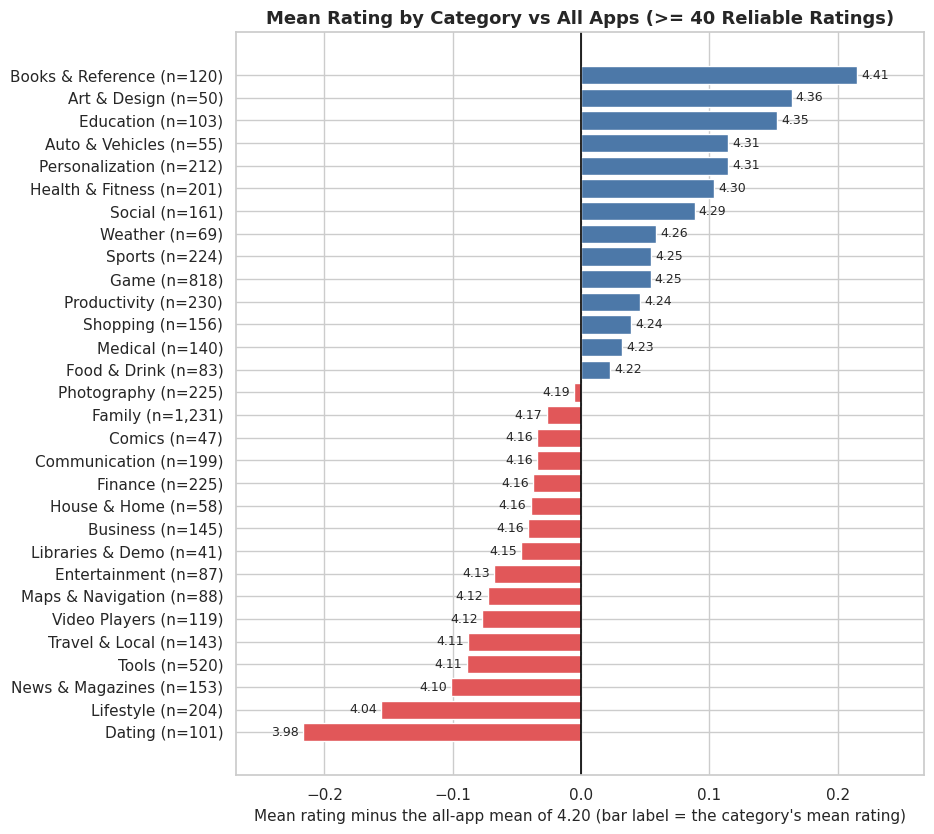

Categories with >= 40 reliable ratings: 30 of 33 | all-app mean 4.198
Highest: [{'Category_Label': 'Books & Reference', 'n': 120, 'mean': 4.41}, {'Category_Label': 'Art & Design', 'n': 50, 'mean': 4.36}, {'Category_Label': 'Education', 'n': 103, 'mean': 4.35}, {'Category_Label': 'Auto & Vehicles', 'n': 55, 'mean': 4.31}]
Lowest : [{'Category_Label': 'Dating', 'n': 101, 'mean': 3.98}, {'Category_Label': 'Lifestyle', 'n': 204, 'mean': 4.04}, {'Category_Label': 'News & Magazines', 'n': 153, 'mean': 4.1}, {'Category_Label': 'Tools', 'n': 520, 'mean': 4.11}]
Below the all-app mean: 16 of 30 | spread between best and worst category mean: 0.43 stars
Kruskal-Wallis across these categories: H = 237.9, p = 1.14e-34


In [28]:
c_stats = (rel.groupby(["Category", "Category_Label"])["Rating"].agg(n="count", median="median", mean="mean").reset_index()
              .query("n >= @MIN_APPS").sort_values("mean"))
overall_mean = rel["Rating"].mean()
dev = c_stats["mean"] - overall_mean
fig, ax = plt.subplots(figsize=(9.5, 8.5))
ax.barh([f"{c} (n={n:,})" for c, n in zip(c_stats["Category_Label"], c_stats["n"])], dev, color=["#E15759" if v < 0 else "#4C78A8" for v in dev])
ax.bar_label(ax.containers[0], labels=[f"{m:.2f}" for m in c_stats["mean"]], padding=3, fontsize=9)
ax.axvline(0, color="black", lw=1.2)
ax.set(title=f"Mean Rating by Category vs All Apps (>= {MIN_APPS} Reliable Ratings)",
       xlabel=f"Mean rating minus the all-app mean of {overall_mean:.2f} (bar label = the category's mean rating)", ylabel="")
ax.margins(x=0.12)
fig.tight_layout()
save_fig(fig, "16_mean_rating_by_category")

print(f"Categories with >= {MIN_APPS} reliable ratings: {len(c_stats)} of {apps['Category'].nunique()} | all-app mean {overall_mean:.3f}")
print("Highest:", c_stats.sort_values("mean", ascending=False).head(4)[["Category_Label", "n", "mean"]].round(2).to_dict("records"))
print("Lowest :", c_stats.head(4)[["Category_Label", "n", "mean"]].round(2).to_dict("records"))
print("Below the all-app mean:", (c_stats["mean"] < overall_mean).sum(), "of", len(c_stats), f"| spread between best and worst category mean: {c_stats['mean'].max() - c_stats['mean'].min():.2f} stars")
kw = stats.kruskal(*[g["Rating"].values for _, g in rel[rel["Category"].isin(c_stats["Category"])].groupby("Category")])
print(f"Kruskal-Wallis across these categories: H = {kw.statistic:.1f}, p = {kw.pvalue:.2e}")

**Why this chart:** Averages by category show whether some categories consistently deliver better-rated apps. Only categories with at least 40 reliably rated apps are shown, and bars show the distance from the all-app mean.

**Insight:** Of 33 categories, 30 meet the rule. Books & Reference leads with a mean of 4.41 (120 apps), then Art & Design (4.36), Education (4.35) and Auto & Vehicles (4.31). The lowest are Dating (3.98, 101 apps), Lifestyle (4.04), News & Magazines (4.10) and Tools (4.11). 16 of 30 categories sit below the all-app mean of 4.20, and the spread from best to worst is 0.43 stars. The difference between categories is statistically significant (Kruskal-Wallis p < 0.0001), but the effect is small: category explains only about 3.4% of the variation in rating (epsilon-squared 0.034).

**Business impact:** Mixed. Category matters, but most of what decides a rating lies inside the category. Action: use category as a baseline expectation (for example, Dating apps start about 0.2 stars below average), and do not pick a category for its rating alone.

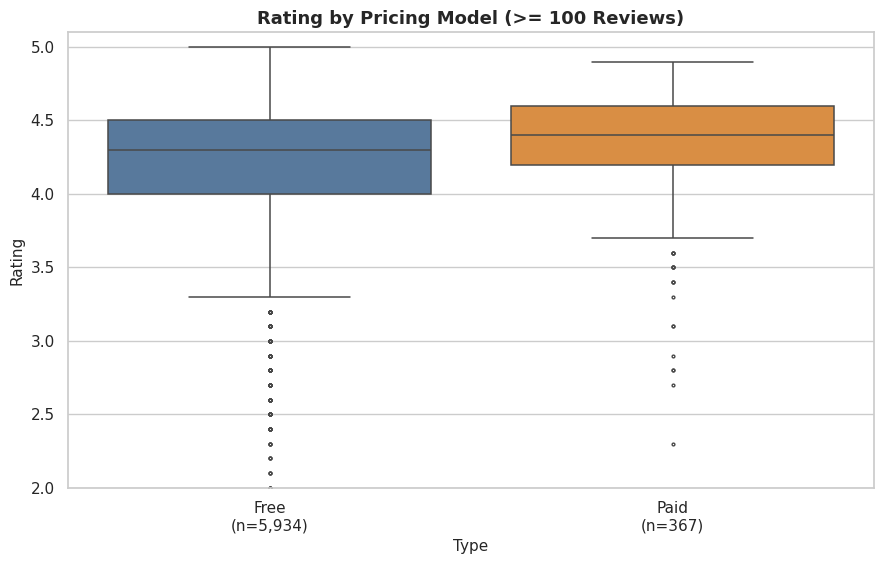

,n,median,mean,p10,p90,share_4.5+_%,share_below_4_%
Type,,,,,,,
Free,5934,4.30,4.19,3.70,4.60,27.77,20.76
Paid,367,4.40,4.35,3.90,4.70,47.14,12.53


Mean gap (paid - free): +0.157 | Mann-Whitney p = 0.0000 | Cliff's delta = +0.261
All rated apps (no review threshold): {'Free': {'count': 7594, 'median': 4.3, 'mean': 4.17}, 'Paid': {'count': 602, 'median': 4.4, 'mean': 4.26}}


In [29]:
plot_box(rel, "Type", "Rating", f"Rating by Pricing Model (>= {MIN_REVIEWS} Reviews)", "Type", "Rating", "17_rating_by_type", order=FREE_PAID, palette=PALETTE_TYPE, ylim=(2, 5.1))

by_type = rel.groupby("Type")["Rating"].agg(n="count", median="median", mean="mean", p10=lambda s: s.quantile(.1), p90=lambda s: s.quantile(.9))
by_type["share_4.5+_%"] = rel.groupby("Type")["Rating"].apply(lambda s: (s >= 4.5).mean() * 100)
by_type["share_below_4_%"] = rel.groupby("Type")["Rating"].apply(lambda s: (s < 4).mean() * 100)
display(by_type.loc[FREE_PAID].round(2))
a, b = rel.loc[rel["Type"] == "Paid", "Rating"], rel.loc[rel["Type"] == "Free", "Rating"]
mw = stats.mannwhitneyu(a, b, alternative="two-sided")
print(f"Mean gap (paid - free): {a.mean() - b.mean():+.3f} | Mann-Whitney p = {mw.pvalue:.4f} | Cliff's delta = {cliffs_delta(a, b):+.3f}")
allr = rated.groupby("Type")["Rating"].agg(["count", "median", "mean"]).round(2)
print("All rated apps (no review threshold):", allr.to_dict("index"))

**Why this chart:** If price signals quality, paid apps should rate higher. A box plot compares the full rating distribution of free and paid apps with 100+ reviews.

**Insight:** Paid apps rate higher: mean 4.35 (median 4.4, 367 apps) against 4.19 (median 4.3, 5,934 apps) for free apps. 47.1% of paid apps score 4.5 or higher against 27.8% of free apps, and only 12.5% score below 4.0 against 20.8%. The difference is significant and moderate in size (Mann-Whitney p < 0.0001, Cliff's delta +0.26), and the bootstrap 95% intervals for the two means (4.18–4.20 and 4.31–4.38) do not overlap.

**Business impact:** Positive for paid apps' quality, with a caveat: people who pay tend to be more committed and rate more kindly, and paid apps are a self-selected group. Action: do not read the gap as proof that charging improves quality; use it as evidence that paying users are satisfied users.

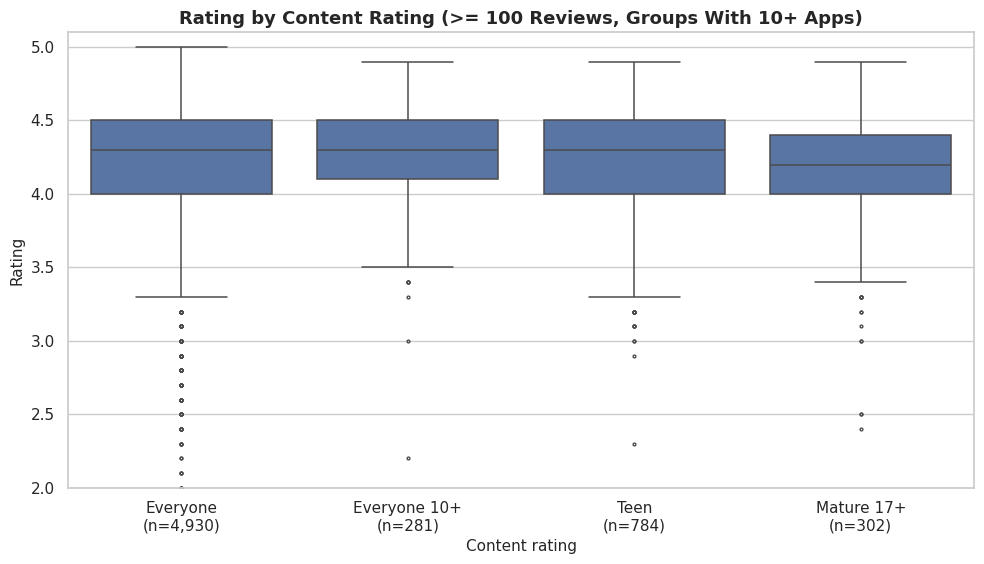

,n,median,mean,share_4.5+_%
Content_Rating,,,,
Everyone,4930,4.30,4.20,29.72
Everyone 10+,281,4.30,4.25,28.47
Teen,784,4.30,4.21,27.17
Mature 17+,302,4.20,4.13,20.20


Kruskal-Wallis across content ratings: H = 15.3, p = 0.0016
Excluded (fewer than 10 reliably rated apps): {'Adults only 18+': 3, 'Unrated': 1}


In [30]:
cr_order = [c for c in CONTENT_ORDER if c in rel["Content_Rating"].unique() and (rel["Content_Rating"] == c).sum() >= 10]
plot_box(rel[rel["Content_Rating"].isin(cr_order)], "Content_Rating", "Rating", f"Rating by Content Rating (>= {MIN_REVIEWS} Reviews, Groups With 10+ Apps)",
         "Content rating", "Rating", "18_rating_by_content_rating", order=cr_order, ylim=(2, 5.1), figsize=(10, 5.8))

cr = rel[rel["Content_Rating"].isin(cr_order)].groupby("Content_Rating")["Rating"].agg(n="count", median="median", mean="mean")
cr["share_4.5+_%"] = rel[rel["Content_Rating"].isin(cr_order)].groupby("Content_Rating")["Rating"].apply(lambda s: (s >= 4.5).mean() * 100)
display(cr.loc[cr_order].round(2))
kw = stats.kruskal(*[g["Rating"].values for _, g in rel[rel["Content_Rating"].isin(cr_order)].groupby("Content_Rating")])
print(f"Kruskal-Wallis across content ratings: H = {kw.statistic:.1f}, p = {kw.pvalue:.4f}")
print("Excluded (fewer than 10 reliably rated apps):", rel.loc[~rel["Content_Rating"].isin(cr_order), "Content_Rating"].value_counts().to_dict())

**Why this chart:** Content rating groups apps by intended audience. A box plot checks whether audience maturity is linked to rating.

**Insight:** Ratings are almost the same across Everyone (mean 4.20), Everyone 10+ (4.25) and Teen (4.21), but Mature 17+ is lower (mean 4.13, and only 20.2% of its apps score 4.5 or higher against 27–30% elsewhere). The differences are significant (Kruskal-Wallis p = 0.0016) but small. Two groups (Adults only 18+, Unrated) have too few reliably rated apps to compare.

**Business impact:** Neutral. Audience maturity is not a driver of quality, but Mature 17+ apps (largely dating and games) face slightly harsher ratings. Action: do not use content rating to forecast a rating; when targeting mature audiences, budget for a small rating penalty.

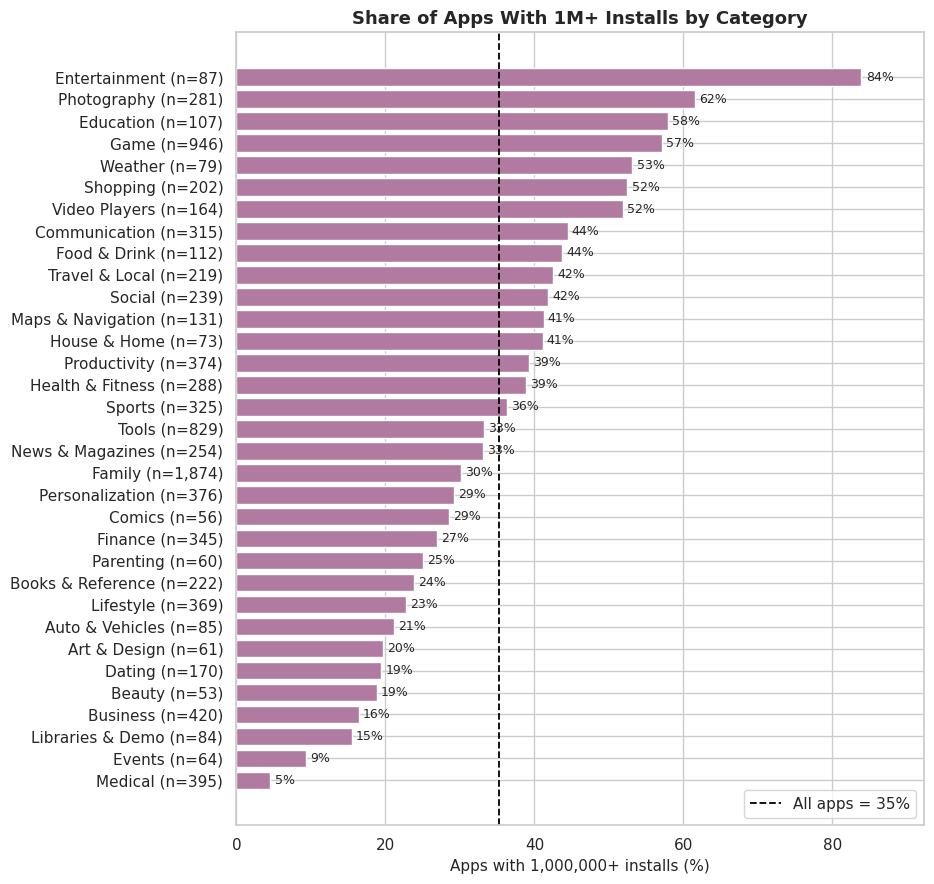

Categories shown: 33 | all-app share with 1M+ installs: 35.2%
Highest: [{'Category_Label': 'Entertainment', 'n': 87, 'share_1m': 83.9, 'median_installs': 1000000.0}, {'Category_Label': 'Photography', 'n': 281, 'share_1m': 61.6, 'median_installs': 1000000.0}, {'Category_Label': 'Education', 'n': 107, 'share_1m': 57.9, 'median_installs': 1000000.0}, {'Category_Label': 'Game', 'n': 946, 'share_1m': 57.1, 'median_installs': 1000000.0}, {'Category_Label': 'Weather', 'n': 79, 'share_1m': 53.2, 'median_installs': 1000000.0}]
Lowest : [{'Category_Label': 'Medical', 'n': 395, 'share_1m': 4.6, 'median_installs': 1000.0}, {'Category_Label': 'Events', 'n': 64, 'share_1m': 9.4, 'median_installs': 1000.0}, {'Category_Label': 'Libraries & Demo', 'n': 84, 'share_1m': 15.5, 'median_installs': 10000.0}, {'Category_Label': 'Business', 'n': 420, 'share_1m': 16.4, 'median_installs': 1000.0}, {'Category_Label': 'Beauty', 'n': 53, 'share_1m': 18.9, 'median_installs': 50000.0}]
Median installs - highest: [{'C

In [31]:
cat_inst = (apps.groupby(["Category", "Category_Label"]).agg(n=("App", "count"), median_installs=("Installs_count", "median"),
            share_1m=("Installs_count", lambda s: (s >= 1_000_000).mean() * 100)).reset_index().query("n >= @MIN_APPS").sort_values("share_1m"))
fig, ax = plt.subplots(figsize=(9.5, 9))
ax.barh([f"{c} (n={n:,})" for c, n in zip(cat_inst["Category_Label"], cat_inst["n"])], cat_inst["share_1m"], color="#B07AA1")
ax.bar_label(ax.containers[0], labels=[f"{v:.0f}%" for v in cat_inst["share_1m"]], padding=3, fontsize=9)
ax.axvline((apps["Installs_count"] >= 1_000_000).mean() * 100, color="black", ls="--", lw=1.3, label=f"All apps = {(apps['Installs_count'] >= 1_000_000).mean() * 100:.0f}%")
ax.set(title="Share of Apps With 1M+ Installs by Category", xlabel="Apps with 1,000,000+ installs (%)", ylabel="")
ax.legend(frameon=True, loc="lower right")
ax.margins(x=0.1)
fig.tight_layout()
save_fig(fig, "19_share_1m_installs_by_category")

print(f"Categories shown: {len(cat_inst)} | all-app share with 1M+ installs: {(apps['Installs_count'] >= 1_000_000).mean():.1%}")
print("Highest:", cat_inst.sort_values("share_1m", ascending=False).head(5)[["Category_Label", "n", "share_1m", "median_installs"]].round(1).to_dict("records"))
print("Lowest :", cat_inst.head(5)[["Category_Label", "n", "share_1m", "median_installs"]].round(1).to_dict("records"))
print("Median installs - highest:", cat_inst.sort_values("median_installs", ascending=False).head(4)[["Category_Label", "median_installs"]].to_dict("records"))

**Why this chart:** Reach differs by category. Bars show the share of apps in each category that pass one million installs, against the market average.

**Insight:** Across the whole market 35.2% of apps pass one million installs. Entertainment leads with 83.9%, then Photography (61.6%), Education (57.9%), Game (57.1%) and Weather (53.2%). Medical is the lowest at 4.6% (median installs just 1,000), followed by Events (9.4%), Libraries & Demo (15.5%), Business (16.4%, also 1,000 median) and Beauty (18.9%).

**Business impact:** Mixed. Consumer entertainment categories deliver mass reach, while professional and niche categories (Medical, Business) reach small audiences even when apps are good. Action: set install targets by category, and for Medical and Business plan for a niche business model (paid, B2B) instead of mass adoption.

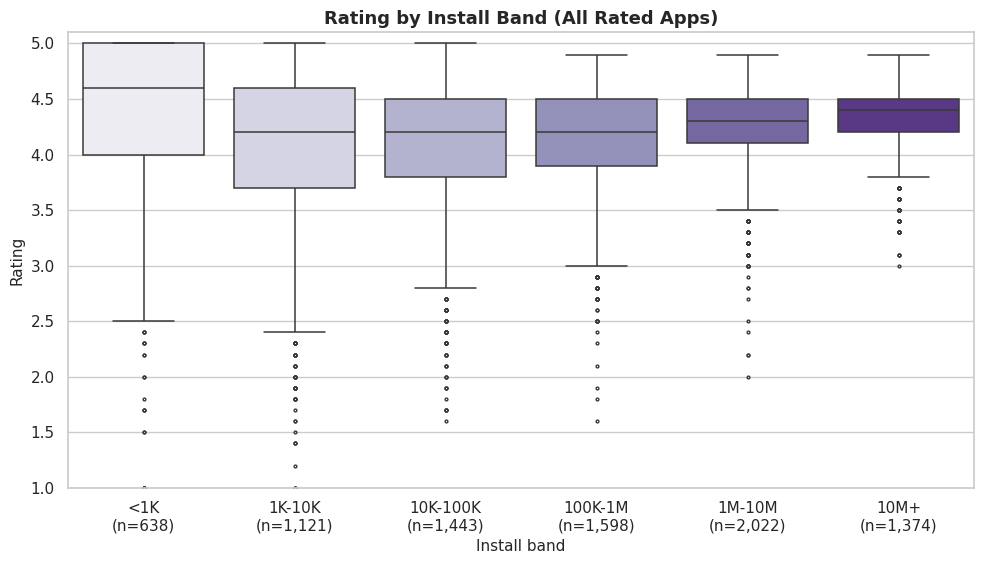

,n,median,mean,std,p10,share_4.5+_%,share_below_4_%
Install_Band,,,,,,,
<1K,638,4.60,4.35,0.86,3.00,59.72,20.69
1K-10K,1121,4.20,4.05,0.73,3.00,34.17,34.08
10K-100K,1443,4.20,4.04,0.58,3.20,25.43,34.23
100K-1M,1598,4.20,4.13,0.47,3.50,27.10,27.41
1M-10M,2022,4.30,4.22,0.35,3.80,26.16,17.06
10M+,1374,4.40,4.32,0.27,4.00,33.26,8.59


Spearman(installs, rating), all rated apps: 0.027 | reliable ratings only: 0.118
Rating spread (std) under 1K installs vs 1M+ installs: 0.86 vs 0.31


In [32]:
d = rated.dropna(subset=["Install_Band"])
plot_box(d, "Install_Band", "Rating", "Rating by Install Band (All Rated Apps)", "Install band", "Rating", "20_rating_by_install_band",
         order=INSTALL_BAND_ORDER, ylim=(1, 5.1), palette=dict(zip(INSTALL_BAND_ORDER, sns.color_palette("Purples", 6))), figsize=(10, 5.8))

ib = d.groupby("Install_Band", observed=True)["Rating"].agg(n="count", median="median", mean="mean", std="std", p10=lambda s: s.quantile(.1))
ib["share_4.5+_%"] = d.groupby("Install_Band", observed=True)["Rating"].apply(lambda s: (s >= 4.5).mean() * 100)
ib["share_below_4_%"] = d.groupby("Install_Band", observed=True)["Rating"].apply(lambda s: (s < 4).mean() * 100)
display(ib.round(2))
print(f"Spearman(installs, rating), all rated apps: {d['Installs_count'].corr(d['Rating'], method='spearman'):.3f} | reliable ratings only: {rel['Installs_count'].corr(rel['Rating'], method='spearman'):.3f}")
print("Rating spread (std) under 1K installs vs 1M+ installs:", round(ib.loc["<1K", "std"], 2), "vs", round(ib.loc[["1M-10M", "10M+"], "std"].mean(), 2))

**Why this chart:** If popular apps are better, rating should rise with installs. A box plot of rating by install band tests this for all rated apps.

**Insight:** The relationship is weak and U-shaped. Apps with under 1,000 installs have the highest median (4.6) but also the widest spread (standard deviation 0.86) because many have only a few reviews. The middle bands drop to a mean of about 4.05 (34% of apps below 4.0 in the 1K–100K bands), then ratings recover to a mean of 4.32 at 10M+ installs, where only 8.6% are below 4.0 and the spread is just 0.27. The rank correlation between installs and rating is 0.03 for all rated apps and 0.12 for apps with reliable ratings.

**Business impact:** Mixed. Very large apps almost never have poor ratings, but reaching scale does not depend on a high rating, and small-app ratings are unreliable. Action: do not use rating alone to predict success, and treat ratings in the lowest install bands as noise.

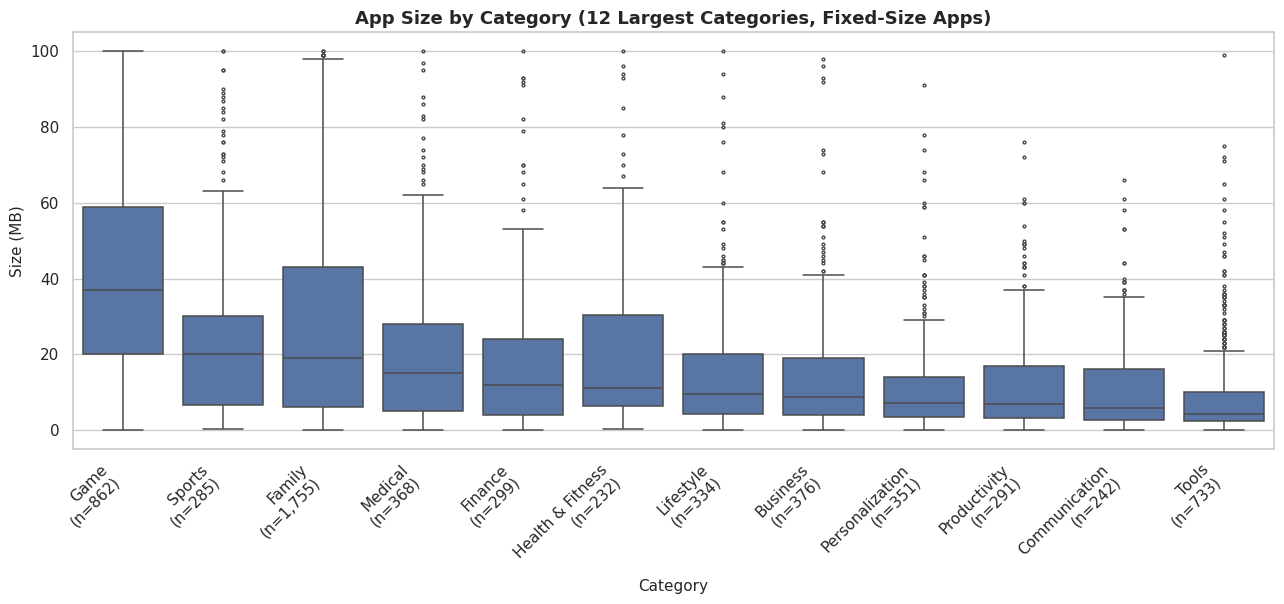

,n,median,mean,p90
Category_Label,,,,
Game,862,37.00,41.70,84.90
Sports,285,20.00,24.10,56.60
Family,1755,19.00,27.30,67.00
Medical,368,15.00,19.20,40.00
Finance,299,12.00,17.40,39.20
Health & Fitness,232,11.00,20.70,53.90
Lifestyle,334,9.60,14.80,33.00
Business,376,8.60,13.90,30.00
Personalization,351,7.10,11.20,26.00


Smallest median size (all categories): {'Libraries & Demo': 3.1, 'Tools': 4.2, 'Communication': 5.7} | largest: {'Family': 19.0, 'Sports': 20.0, 'Game': 37.0}
Share of apps with size 'Varies with device' - Tools: 11.6% | Games: 8.9% | Family: 6.4%


In [33]:
top12s = list(apps["Category_Label"].value_counts().head(12).index)
sd = apps[apps["Category_Label"].isin(top12s)].dropna(subset=["Size_MB"])
s_order = list(sd.groupby("Category_Label")["Size_MB"].median().sort_values(ascending=False).index)
plot_box(sd, "Category_Label", "Size_MB", "App Size by Category (12 Largest Categories, Fixed-Size Apps)", "Category", "Size (MB)", "21_size_by_category_box",
         order=s_order, figsize=(13, 6.2), rotate=45)

sz = sd.groupby("Category_Label")["Size_MB"].agg(n="count", median="median", mean="mean", p90=lambda s: s.quantile(.9))
display(sz.loc[s_order].round(1))
allsz = apps.dropna(subset=["Size_MB"]).groupby("Category_Label")["Size_MB"].median().sort_values()
print("Smallest median size (all categories):", allsz.head(3).round(1).to_dict(), "| largest:", allsz.tail(3).round(1).to_dict())
print(f"Share of apps with size 'Varies with device' - Tools: {apps.loc[apps['Category'] == 'TOOLS', 'Size_MB'].isna().mean():.1%} | Games: {apps.loc[apps['Category'] == 'GAME', 'Size_MB'].isna().mean():.1%} | Family: {apps.loc[apps['Category'] == 'FAMILY', 'Size_MB'].isna().mean():.1%}")

**Why this chart:** Size differs by type of app. Box plots for the twelve largest categories show which ones are heavy and which are light.

**Insight:** Games are by far the heaviest (median 37.0 MB, 90th percentile 84.9 MB), followed by Sports (20.0), Family (19.0) and Medical (15.0). Tools (4.2 MB), Communication (5.7) and Productivity (6.9) are the lightest, and across all categories Libraries & Demo has the smallest median at 3.1 MB. The share of apps whose size varies with device is 11.6% in Tools, 8.9% in Games and 6.4% in Family.

**Business impact:** Neutral. Size follows function: graphics-heavy apps are big and utilities are small. Action: benchmark size against the category median, and for heavy apps consider lighter versions or on-demand asset downloads for users with limited storage.

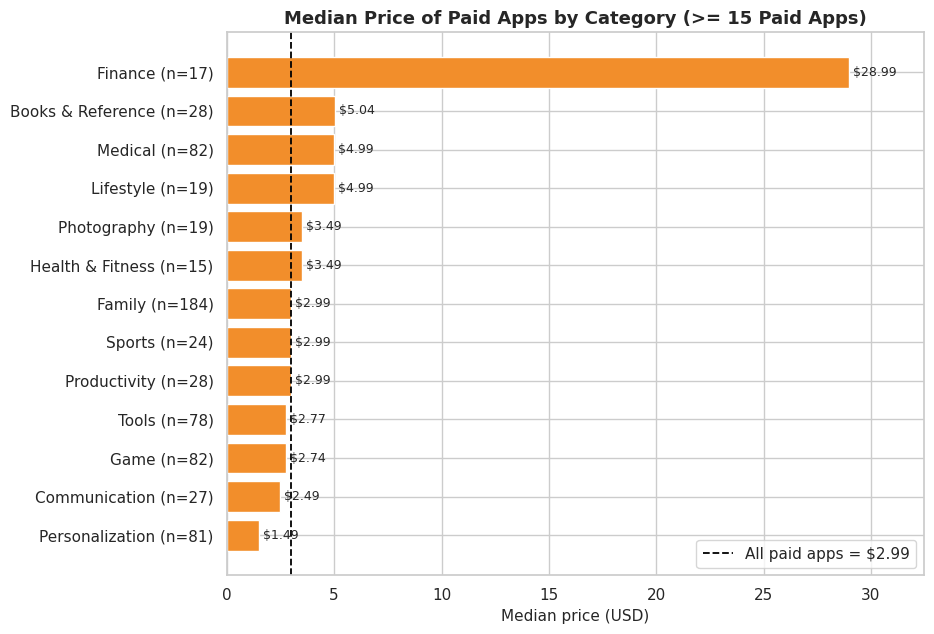

Categories with >= 15 paid apps: 13 | paid apps in those categories: 684 of 754
Highest median price: [{'Category_Label': 'Medical', 'n': 82, 'median_price': 4.99}, {'Category_Label': 'Books & Reference', 'n': 28, 'median_price': 5.04}, {'Category_Label': 'Finance', 'n': 17, 'median_price': 28.99}]
Lowest median price : [{'Category_Label': 'Personalization', 'n': 81, 'median_price': 1.49}, {'Category_Label': 'Communication', 'n': 27, 'median_price': 2.49}, {'Category_Label': 'Game', 'n': 82, 'median_price': 2.74}]
Paid apps by category (top 5): {'Family': 184, 'Game': 82, 'Medical': 82, 'Personalization': 81, 'Tools': 78}
Categories where novelty-priced apps pull the mean far above the median: {'Finance': {'mean': 170.64, 'median': 28.99, 'gap': 141.65}, 'Lifestyle': {'mean': 124.26, 'median': 4.99, 'gap': 119.27}, 'Family': {'mean': 13.06, 'median': 2.99, 'gap': 10.07}}


In [34]:
pc = (paid.groupby(["Category", "Category_Label"]).agg(n=("App", "count"), median_price=("Price_USD", "median"), mean_price=("Price_USD", "mean")).reset_index()
          .query("n >= 15").sort_values("median_price"))
fig, ax = plt.subplots(figsize=(9.5, 6.5))
ax.barh([f"{c} (n={n})" for c, n in zip(pc["Category_Label"], pc["n"])], pc["median_price"], color="#F28E2B")
ax.bar_label(ax.containers[0], labels=[f"${v:.2f}" for v in pc["median_price"]], padding=3, fontsize=9)
ax.axvline(paid["Price_USD"].median(), color="black", ls="--", lw=1.3, label=f"All paid apps = ${paid['Price_USD'].median():.2f}")
ax.set(title="Median Price of Paid Apps by Category (>= 15 Paid Apps)", xlabel="Median price (USD)", ylabel="")
ax.legend(frameon=True, loc="lower right")
ax.margins(x=0.12)
fig.tight_layout()
save_fig(fig, "22_median_price_by_category")

print(f"Categories with >= 15 paid apps: {len(pc)} | paid apps in those categories: {pc['n'].sum()} of {len(paid)}")
print("Highest median price:", pc.tail(3)[["Category_Label", "n", "median_price"]].round(2).to_dict("records"))
print("Lowest median price :", pc.head(3)[["Category_Label", "n", "median_price"]].round(2).to_dict("records"))
print("Paid apps by category (top 5):", paid["Category_Label"].value_counts().head(5).to_dict())
print("Categories where novelty-priced apps pull the mean far above the median:", paid.groupby("Category_Label")["Price_USD"].agg(["mean", "median"]).assign(gap=lambda t: t["mean"] - t["median"]).sort_values("gap", ascending=False).head(3).round(2).to_dict("index"))

**Why this chart:** Price levels differ by category. Bars show the median price of paid apps in categories with at least 15 paid apps, against the all-paid median.

**Insight:** 13 categories have at least 15 paid apps (684 of 754 paid apps). Personalization ($1.49), Communication ($2.49) and Game ($2.74) are cheapest, while Medical ($4.99) and Books & Reference ($5.04) are among the highest. Finance shows a median of $28.99 but this is distorted by novelty apps; its mean price of $170.64 is far above its median. Lifestyle shows the same distortion (mean $124.26, median $4.99). The all-paid median is $2.99.

**Business impact:** Mixed. Users accept higher prices for professional and reference apps than for personalization or games. Action: price inside the category norm, and ignore Finance and Lifestyle averages, which are driven by 'I am rich' novelty apps.

## 12. Bivariate analysis — numerical vs numerical

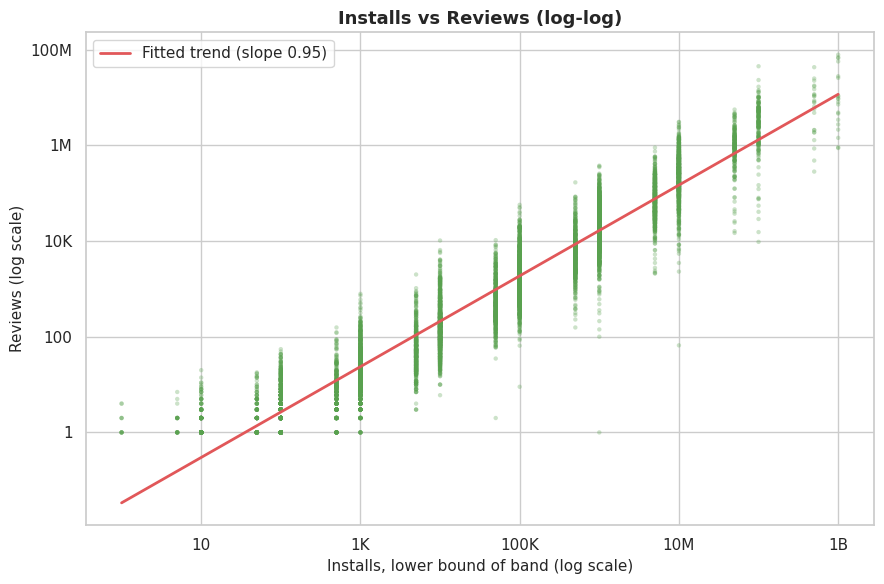

{'n': 9066, 'slope': 0.949, 'spearman': 0.965}
Median reviews per 1,000 installs by install band (bands with 1K+ installs):
{'1K-10K': 14.0, '10K-100K': 13.5, '100K-1M': 14.5, '1M-10M': 18.84, '10M+': 23.24}
Overall median reviews per 1,000 installs: 16.64 | mean 30.6 | 90th pct 67.4
Apps with more reviews than the install band lower bound: 11 (band is a floor, so this is possible)


In [35]:
stats_ri = loglog_scatter(apps[(apps["Reviews"] > 0) & (apps["Installs_count"] > 0)], "Installs_count", "Reviews",
                          "Installs vs Reviews (log-log)", "Installs, lower bound of band (log scale)", "Reviews (log scale)", "23_installs_vs_reviews", color="#59A14F")
print({k: round(v, 3) for k, v in stats_ri.items()})
ri = apps[(apps["Installs_count"] >= 1000)].copy()
print("Median reviews per 1,000 installs by install band (bands with 1K+ installs):")
print(ri.groupby("Install_Band", observed=True)["Reviews_per_1k_installs"].median().round(2).to_dict())
print(f"Overall median reviews per 1,000 installs: {ri['Reviews_per_1k_installs'].median():.2f} | mean {ri['Reviews_per_1k_installs'].mean():.1f} | 90th pct {ri['Reviews_per_1k_installs'].quantile(.9):.1f}")
print(f"Apps with more reviews than the install band lower bound: {int(apps['flag_reviews_gt_installs'].sum())} (band is a floor, so this is possible)")

**Why this chart:** Reviews and installs should move together if reviews measure engagement. A log-log scatter with a fitted line tests how tightly.

**Insight:** The two move almost in lockstep (rank correlation 0.965 over 9,066 apps, fitted slope 0.95 on log axes), so each tenfold rise in installs brings roughly a ninefold rise in reviews. Among apps with 1,000+ installs the median app collects 16.6 reviews per 1,000 installs, and the ratio climbs from 14.0 (1K–10K installs) to 23.2 (10M+). 11 apps have more reviews than their install-band floor, which is possible because the band is a lower bound.

**Business impact:** Positive for analysis. Reviews are a reliable stand-in for reach, so review count can be used to estimate an app's scale. Action: use reviews per install as an engagement metric (chart 41) and keep only one of reviews and installs in models.

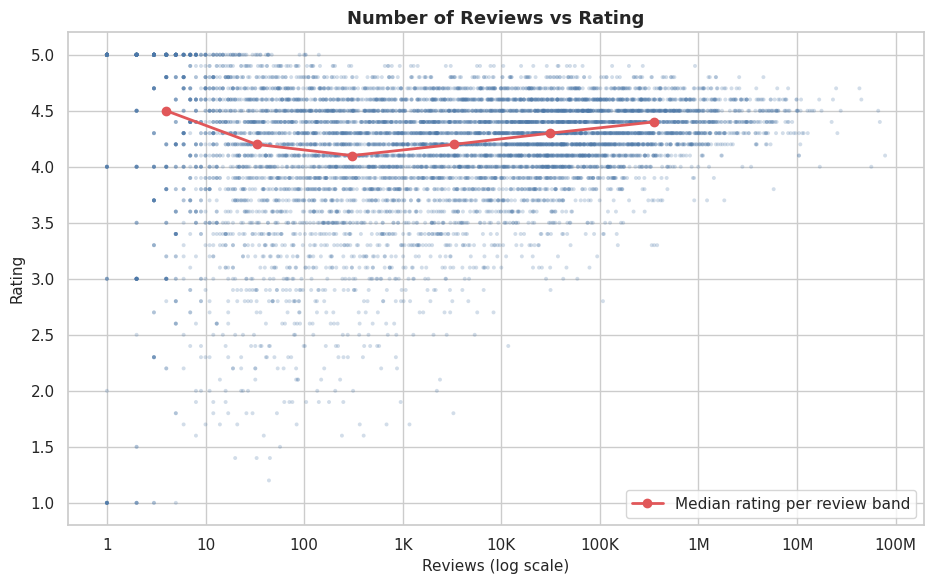

Rows: 8,196 | Spearman(reviews, rating): 0.120


,n,median,mean,std,share_5.0_%,share_below_4_%
Reviews,,,,,,
1-9,587,4.50,4.20,0.96,36.63,28.62
10-99,1308,4.20,4.04,0.71,3.98,35.40
100-999,1498,4.10,4.04,0.56,0.27,34.65
1K-9.9K,1530,4.20,4.14,0.44,0.00,26.67
10K-99K,1822,4.30,4.24,0.32,0.00,15.59
100K+,1451,4.40,4.37,0.24,0.00,4.62


Rating std dev: under 30 reviews 0.85 | 1,000+ reviews 0.36


In [36]:
d = rated[rated["Reviews"] > 0]
fig, ax = plt.subplots(figsize=(9.5, 6))
ax.scatter(d["Reviews"], d["Rating"], s=8, alpha=0.25, color=BASE_COLOR, edgecolors="none")
bands = pd.cut(d["Reviews"], [0, 9, 99, 999, 9_999, 99_999, np.inf], labels=["1-9", "10-99", "100-999", "1K-9.9K", "10K-99K", "100K+"])
vb = d.groupby(bands, observed=True).agg(x=("Reviews", "median"), y=("Rating", "median"), n=("Rating", "count"))
ax.plot(vb["x"], vb["y"], color="#E15759", marker="o", lw=2, label="Median rating per review band")
ax.set_xscale("log")
humanize_axis(ax, "x")
ax.set(title="Number of Reviews vs Rating", xlabel="Reviews (log scale)", ylabel="Rating")
ax.legend(frameon=True, loc="lower right")
fig.tight_layout()
save_fig(fig, "24_reviews_vs_rating")

print(f"Rows: {len(d):,} | Spearman(reviews, rating): {d['Reviews'].corr(d['Rating'], method='spearman'):.3f}")
vb2 = d.groupby(bands, observed=True)["Rating"].agg(n="count", median="median", mean="mean", std="std")
vb2["share_5.0_%"] = d.groupby(bands, observed=True)["Rating"].apply(lambda s: (s == 5).mean() * 100)
vb2["share_below_4_%"] = d.groupby(bands, observed=True)["Rating"].apply(lambda s: (s < 4).mean() * 100)
display(vb2.round(2))
print(f"Rating std dev: under 30 reviews {d.loc[d['Reviews'] < 30, 'Rating'].std():.2f} | 1,000+ reviews {d.loc[d['Reviews'] >= 1000, 'Rating'].std():.2f}")

**Why this chart:** Ratings based on few reviews are unstable. A scatter of reviews against rating, with the median per review band, shows how ratings settle as evidence grows.

**Insight:** The rank correlation between reviews and rating is a weak 0.12 over 8,196 rated apps, but the spread tells the story: standard deviation is 0.85 for apps with under 30 reviews and 0.36 for those with 1,000+. In the 1–9 review band 36.6% of apps have a perfect 5.0, against 0.3% in the 100–999 band and none above 1,000. The median rating dips to 4.1 for 100–999 reviews (34.7% below 4.0) and then rises to 4.4 for 100K+ reviews, where only 4.6% are below 4.0.

**Business impact:** Negative for tiny apps' credibility, positive for scale. Early ratings swing wildly. Action: do not judge or promote an app on its rating before it has about 100 reviews, and expect the rating to settle (and often fall slightly) as more users rate.

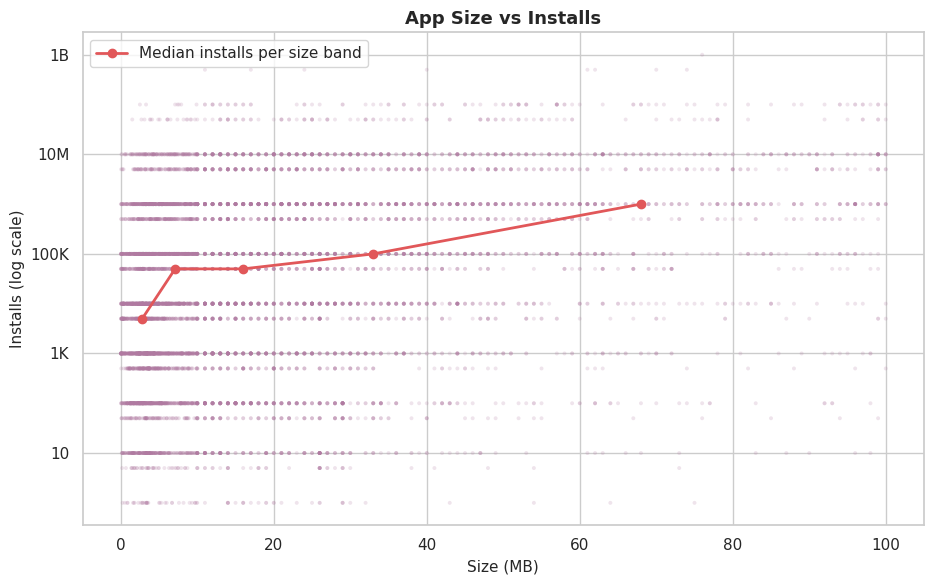

Rows: 8,417 | Spearman(size, installs): 0.310 | Spearman(size, rating): 0.050


,n,median_installs,share_1m,median_rating
Size_Band,,,,
<5 MB,2258,"5,000.00",13.55,4.20
5-10 MB,1524,"50,000.00",23.75,4.30
10-25 MB,2119,"50,000.00",31.57,4.30
25-50 MB,1605,"100,000.00",38.38,4.30
50+ MB,911,"1,000,000.00",59.06,4.30


Median size by install band: {'<1K': 8.3, '1K-10K': 7.6, '10K-100K': 9.0, '100K-1M': 13.0, '1M-10M': 19.0, '10M+': 27.0}
Median size: games vs non-games: {0: 10.0, 1: 37.0}


In [37]:
d = apps.dropna(subset=["Size_MB"])
d = d[d["Installs_count"] > 0]
fig, ax = plt.subplots(figsize=(9.5, 6))
ax.scatter(d["Size_MB"], d["Installs_count"], s=8, alpha=0.2, color="#B07AA1", edgecolors="none")
sb = d.groupby("Size_Band", observed=True).agg(x=("Size_MB", "median"), y=("Installs_count", "median"), n=("App", "count"))
ax.plot(sb["x"], sb["y"], color="#E15759", marker="o", lw=2, label="Median installs per size band")
ax.set_yscale("log")
humanize_axis(ax, "y")
ax.set(title="App Size vs Installs", xlabel="Size (MB)", ylabel="Installs (log scale)")
ax.legend(frameon=True, loc="upper left")
fig.tight_layout()
save_fig(fig, "25_size_vs_installs")

print(f"Rows: {len(d):,} | Spearman(size, installs): {d['Size_MB'].corr(d['Installs_count'], method='spearman'):.3f} | Spearman(size, rating): {d['Size_MB'].corr(d['Rating'], method='spearman'):.3f}")
sb2 = d.groupby("Size_Band", observed=True).agg(n=("App", "count"), median_installs=("Installs_count", "median"), share_1m=("Installs_count", lambda s: (s >= 1_000_000).mean() * 100), median_rating=("Rating", "median"))
display(sb2.round(2))
print("Median size by install band:", d.groupby("Install_Band", observed=True)["Size_MB"].median().round(1).to_dict())
print("Median size: games vs non-games:", d.groupby("Is_Game")["Size_MB"].median().round(1).to_dict())

**Why this chart:** Bigger apps may offer more and attract more users, or may deter downloads. A scatter of size against installs, with the median per size band, tests this.

**Insight:** Larger apps tend to have more installs (rank correlation 0.31 over 8,417 apps) but not better ratings (0.05). Median installs rise from 5,000 for apps under 5 MB to 1,000,000 for apps of 50 MB or more, and the share with 1M+ installs rises from 13.6% to 59.1%. Games are heavy (median 37 MB against 10 MB for other apps) and are among the highest-reach apps, so much of the link comes from category.

**Business impact:** Mixed. Size is a signal of app richness and category, not something to increase for its own sake. Action: keep size in line with the category and functionality; do not expect a larger size to add installs by itself.

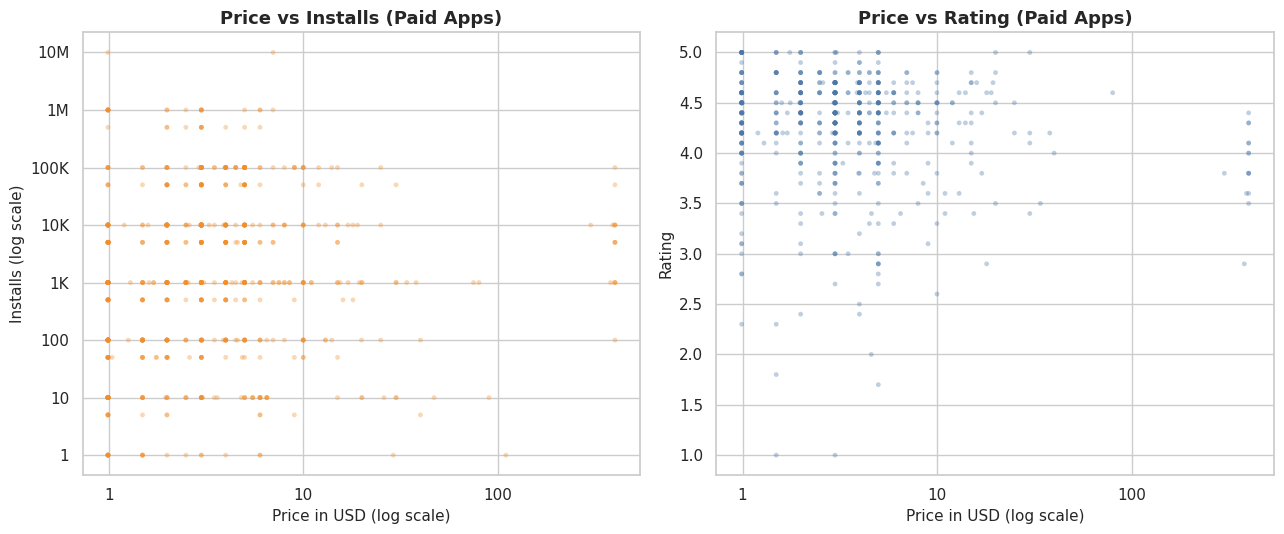

Paid apps: 754 | Spearman(price, installs): 0.131 | Spearman(price, rating): -0.096 (602 rated)


,apps,median_installs,median_rating,share_10k_plus
Price_Band,,,,
<= $1,148,500.00,4.40,22.30
$1-2,135,"1,000.00",4.40,28.15
$2-5,314,"5,000.00",4.40,47.77
$5-10,84,"1,000.00",4.40,34.52
$10+,73,"1,000.00",4.20,30.14


Paid apps with 100K+ installs: 115 | paid apps with 1M+ installs: 22 | free apps with 1M+: 3376
Highest-installed paid apps: [{'App': 'Minecraft', 'Price_USD': 6.99, 'Installs_count': 10000000}, {'App': 'Hitman Sniper', 'Price_USD': 0.99, 'Installs_count': 10000000}, {'App': 'Card Wars - Adventure Time', 'Price_USD': 2.99, 'Installs_count': 1000000}, {'App': 'Facetune - For Free', 'Price_USD': 5.99, 'Installs_count': 1000000}, {'App': 'Beautiful Widgets Pro', 'Price_USD': 2.49, 'Installs_count': 1000000}]


In [38]:
pp = paid.copy()
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
pp2 = pp[pp["Installs_count"] > 0]
axes[0].scatter(pp2["Price_USD"], pp2["Installs_count"], s=12, alpha=0.35, color="#F28E2B", edgecolors="none")
axes[0].set(xscale="log", yscale="log", title="Price vs Installs (Paid Apps)", xlabel="Price in USD (log scale)", ylabel="Installs (log scale)")
humanize_axis(axes[0])
pr = pp[pp["Rating"].notna()]
axes[1].scatter(pr["Price_USD"], pr["Rating"], s=12, alpha=0.35, color="#4C78A8", edgecolors="none")
axes[1].set(xscale="log", title="Price vs Rating (Paid Apps)", xlabel="Price in USD (log scale)", ylabel="Rating")
humanize_axis(axes[1], "x")
fig.tight_layout()
save_fig(fig, "26_price_vs_installs_and_rating")

print(f"Paid apps: {len(pp):,} | Spearman(price, installs): {pp['Price_USD'].corr(pp['Installs_count'], method='spearman'):.3f} | Spearman(price, rating): {pr['Price_USD'].corr(pr['Rating'], method='spearman'):.3f} ({len(pr)} rated)")
pb = pp.groupby("Price_Band", observed=True).agg(apps=("App", "count"), median_installs=("Installs_count", "median"), median_rating=("Rating", "median"), share_10k_plus=("Installs_count", lambda s: (s >= 10_000).mean() * 100))
display(pb.reindex(PRICE_BAND_ORDER).round(2))
print("Paid apps with 100K+ installs:", int((pp["Installs_count"] >= 100_000).sum()), "| paid apps with 1M+ installs:", int((pp["Installs_count"] >= 1_000_000).sum()), "| free apps with 1M+:", int(((apps["Type"] == "Free") & (apps["Installs_count"] >= 1_000_000)).sum()))
print("Highest-installed paid apps:", pp.nlargest(5, "Installs_count")[["App", "Price_USD", "Installs_count"]].to_dict("records"))

**Why this chart:** Among paid apps, price might trade off against reach and rating. Two scatters test both for the 754 paid apps.

**Insight:** Within paid apps, price has only a weak link with installs (rank correlation 0.13) and a weak negative link with rating (−0.10). Median installs by price band are 500 for up to $1, 1,000 for $1–2, 5,000 for $2–5, and 1,000 for both $5–10 and $10+. Apps priced $2–5 have the highest share with 10K+ installs (47.8%), and the $10+ band has the lowest median rating (4.2 against 4.4 elsewhere). Only 22 paid apps pass one million installs (against 3,376 free apps), led by Minecraft ($6.99) and Hitman Sniper ($0.99), both at 10M+.

**Business impact:** Mixed. There is no clear reward for pricing higher, and a $2–5 range looks like the sweet spot in this data. Action: test price points in the $1.99–4.99 range first; expect premium pricing above $10 to serve only a small niche.

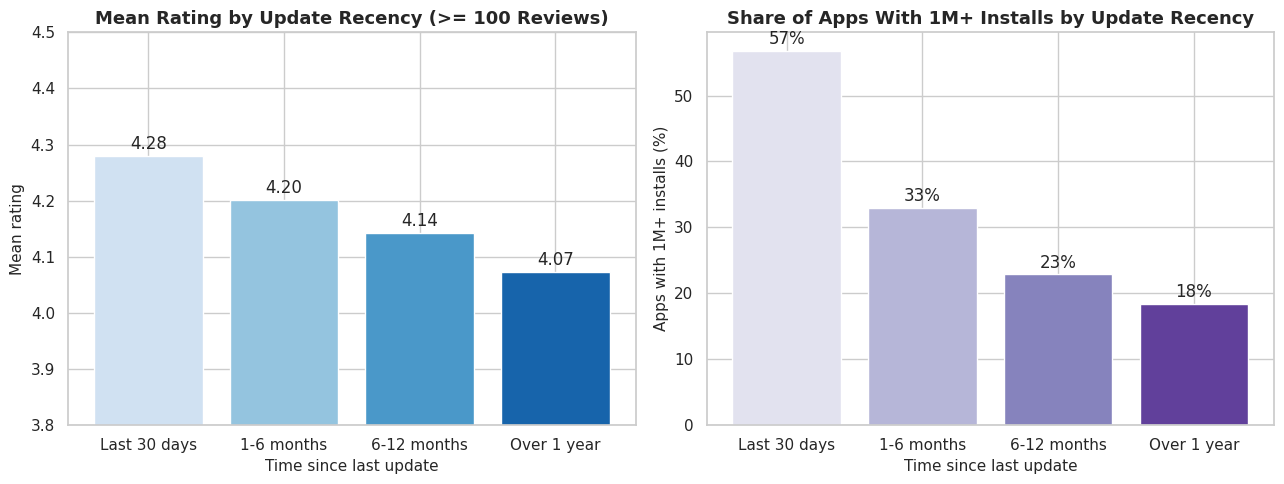

,n,median_rating,mean_rating,median_installs,share_1m
Update_Recency,,,,,
Last 30 days,2936,4.40,4.27,"1,000,000.00",56.74
1-6 months,2987,4.30,4.19,"100,000.00",32.94
6-12 months,1320,4.20,4.12,"10,000.00",22.88
Over 1 year,2416,4.20,4.06,"10,000.00",18.46


Reliable ratings by recency: {'Last 30 days': {'count': 2373, 'median': 4.4, 'mean': 4.28}, '1-6 months': {'count': 1907, 'median': 4.3, 'mean': 4.2}, '6-12 months': {'count': 709, 'median': 4.2, 'mean': 4.14}, 'Over 1 year': {'count': 1312, 'median': 4.2, 'mean': 4.07}}
Spearman(days since update, rating), reliable: -0.214 | Spearman(days since update, installs): -0.332
Median days since update by install band: {'<1K': 170.0, '1K-10K': 219.0, '10K-100K': 188.0, '100K-1M': 105.0, '1M-10M': 42.0, '10M+': 21.0}


In [39]:
d = apps.dropna(subset=["Update_Recency"])
rec_order = ["Last 30 days", "1-6 months", "6-12 months", "Over 1 year"]
rr = d.groupby("Update_Recency", observed=True).agg(n=("App", "count"), median_rating=("Rating", "median"), mean_rating=("Rating", "mean"), median_installs=("Installs_count", "median"),
                                                     share_1m=("Installs_count", lambda s: (s >= 1_000_000).mean() * 100)).reindex(rec_order)
rr_rel = rel.groupby("Update_Recency", observed=True)["Rating"].agg(["count", "median", "mean"]).reindex(rec_order)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(rec_order, rr_rel["mean"], color=sns.color_palette("Blues", 4))
axes[0].bar_label(axes[0].containers[0], labels=[f"{v:.2f}" for v in rr_rel["mean"]], padding=2)
axes[0].set(title=f"Mean Rating by Update Recency (>= {MIN_REVIEWS} Reviews)", xlabel="Time since last update", ylabel="Mean rating", ylim=(3.8, 4.5))
axes[1].bar(rec_order, rr["share_1m"], color=sns.color_palette("Purples", 4))
axes[1].bar_label(axes[1].containers[0], labels=[f"{v:.0f}%" for v in rr["share_1m"]], padding=2)
axes[1].set(title="Share of Apps With 1M+ Installs by Update Recency", xlabel="Time since last update", ylabel="Apps with 1M+ installs (%)")
fig.tight_layout()
save_fig(fig, "27_update_recency_effects")

display(rr.round(2))
print("Reliable ratings by recency:", rr_rel.round(2).to_dict("index"))
print(f"Spearman(days since update, rating), reliable: {rel['Days_Since_Update'].corr(rel['Rating'], method='spearman'):.3f} | Spearman(days since update, installs): {apps['Days_Since_Update'].corr(apps['Installs_count'], method='spearman'):.3f}")
print("Median days since update by install band:", apps.groupby("Install_Band", observed=True)["Days_Since_Update"].median().to_dict())

**Why this chart:** Maintenance may show up in ratings and reach. Bars compare mean rating (apps with 100+ reviews) and the share of 1M+ install apps by time since last update.

**Insight:** Fresher apps do better on both. Apps updated in the last 30 days have a mean rating of 4.27 (4.28 with 100+ reviews) and 56.7% pass one million installs; for apps not updated in over a year the mean is 4.06 and only 18.5% pass one million. Median installs are 1,000,000 for the freshest group and 10,000 for the two oldest groups. The rank correlation of days since update is −0.21 with rating (100+ reviews) and −0.33 with installs, and giant apps are updated most often (median 21 days for 10M+ installs against 219 days for 1K–10K).

**Business impact:** Positive for a maintenance strategy, with a caveat: successful apps have more resources to update, so the link is partly reverse. Action: adopt a regular release cadence and track days since update as a health metric; test the effect by following apps that resume updating.

## 13. Bivariate analysis — categorical vs categorical

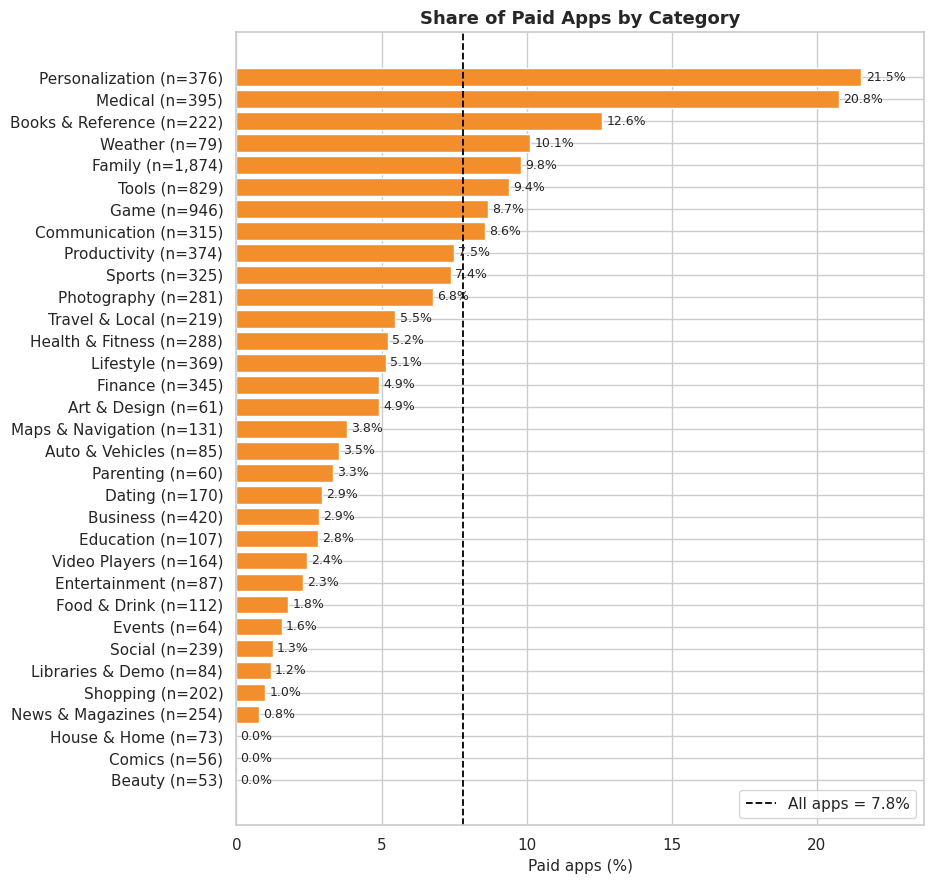

All apps: 7.8% paid | categories shown: 33
Highest paid share: [{'Category_Label': 'Family', 'n': 1874, 'paid': 184, 'paid_share': 9.8}, {'Category_Label': 'Weather', 'n': 79, 'paid': 8, 'paid_share': 10.1}, {'Category_Label': 'Books & Reference', 'n': 222, 'paid': 28, 'paid_share': 12.6}, {'Category_Label': 'Medical', 'n': 395, 'paid': 82, 'paid_share': 20.8}, {'Category_Label': 'Personalization', 'n': 376, 'paid': 81, 'paid_share': 21.5}]
Lowest paid share : [{'Category_Label': 'Beauty', 'n': 53, 'paid': 0, 'paid_share': 0.0}, {'Category_Label': 'Comics', 'n': 56, 'paid': 0, 'paid_share': 0.0}, {'Category_Label': 'House & Home', 'n': 73, 'paid': 0, 'paid_share': 0.0}, {'Category_Label': 'News & Magazines', 'n': 254, 'paid': 2, 'paid_share': 0.8}, {'Category_Label': 'Shopping', 'n': 202, 'paid': 2, 'paid_share': 1.0}]
Categories with under 2% paid apps: 9 | Personalization + Family + Medical + Game hold 429 of 754 paid apps
Chi-square test, category vs pricing model: chi2 = 341.2, p =

In [40]:
ps = (apps.groupby(["Category", "Category_Label"]).agg(n=("App", "count"), paid_share=("Is_Paid", lambda s: s.mean() * 100), paid=("Is_Paid", "sum")).reset_index()
          .query("n >= @MIN_APPS").sort_values("paid_share"))
fig, ax = plt.subplots(figsize=(9.5, 9))
ax.barh([f"{c} (n={n:,})" for c, n in zip(ps["Category_Label"], ps["n"])], ps["paid_share"], color="#F28E2B")
ax.bar_label(ax.containers[0], labels=[f"{v:.1f}%" for v in ps["paid_share"]], padding=3, fontsize=9)
ax.axvline(apps["Is_Paid"].mean() * 100, color="black", ls="--", lw=1.3, label=f"All apps = {apps['Is_Paid'].mean() * 100:.1f}%")
ax.set(title="Share of Paid Apps by Category", xlabel="Paid apps (%)", ylabel="")
ax.legend(frameon=True, loc="lower right")
ax.margins(x=0.1)
fig.tight_layout()
save_fig(fig, "28_paid_share_by_category")

print(f"All apps: {apps['Is_Paid'].mean():.1%} paid | categories shown: {len(ps)}")
print("Highest paid share:", ps.tail(5)[["Category_Label", "n", "paid", "paid_share"]].round(1).to_dict("records"))
print("Lowest paid share :", ps.head(5)[["Category_Label", "n", "paid", "paid_share"]].round(1).to_dict("records"))
print("Categories with under 2% paid apps:", int((ps["paid_share"] < 2).sum()), "| Personalization + Family + Medical + Game hold", int(paid["Category"].isin(["PERSONALIZATION", "FAMILY", "MEDICAL", "GAME"]).sum()), "of", len(paid), "paid apps")
chi = stats.chi2_contingency(pd.crosstab(apps["Category"], apps["Type"]))
print(f"Chi-square test, category vs pricing model: chi2 = {chi[0]:.1f}, p = {chi[1]:.2e}, Cramer's V = {np.sqrt(chi[0] / (len(apps) * (min(pd.crosstab(apps['Category'], apps['Type']).shape) - 1))):.3f}")

**Why this chart:** Monetisation models differ by category. Bars show the share of paid apps in each category against the market average.

**Insight:** The paid share is 7.8% overall but varies widely. Personalization (21.5%, 81 of 376) and Medical (20.8%, 82 of 395) lead, followed by Books & Reference (12.6%), Weather (10.1%) and Family (9.8%). Nine categories are under 2% paid, and Beauty, Comics and House & Home have none. Four categories (Family, Game, Medical, Personalization) hold 429 of the 754 paid apps. The link between category and pricing model is significant and moderate (chi-square p < 0.0001, Cramér's V 0.19).

**Business impact:** Mixed. Paying for apps is normal for personalisation, medical tools and reference, but rare for news, shopping and social apps, where advertising or free access dominates. Action: pick the monetisation model that fits the category norm, and treat a paid-only launch in a mostly free category as a niche bet.

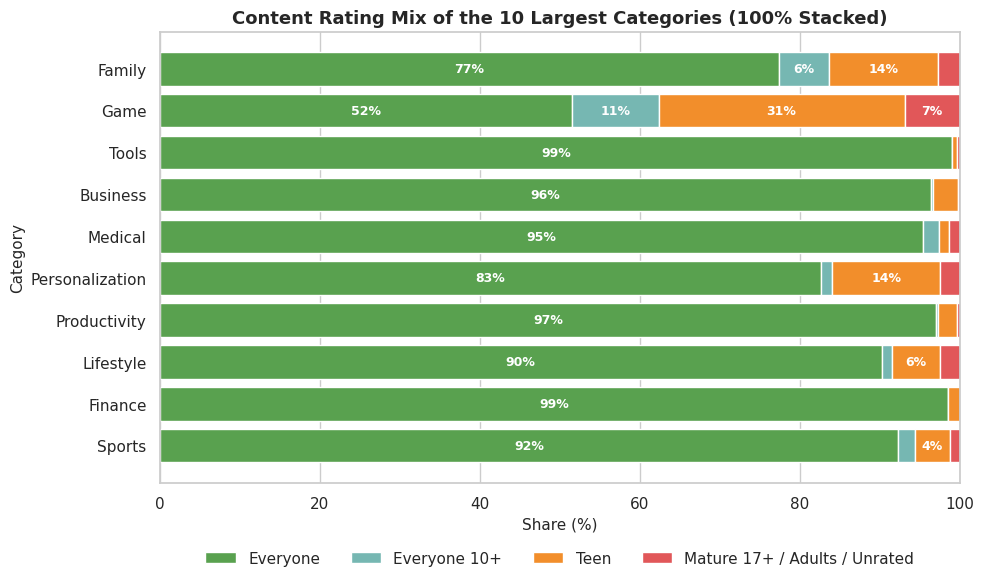

Content_Rating,Everyone,Everyone 10+,Teen,Mature 17+ / Adults / Unrated
Category_Label,,,,
Family,77.40,6.30,13.60,2.70
Game,51.60,10.80,30.80,6.90
Tools,99.00,0.00,0.60,0.40
Business,96.40,0.20,3.10,0.20
Medical,95.40,2.00,1.30,1.30
Personalization,82.70,1.30,13.60,2.40
Productivity,97.10,0.30,2.40,0.30
Lifestyle,90.20,1.40,6.00,2.40
Finance,98.60,0.00,1.40,0.00


Highest Teen+ share: {'Game': 37.6, 'Family': 16.3, 'Personalization': 16.0}
Highest Everyone share: {'Tools': 99.0, 'Finance': 98.6, 'Productivity': 97.1}
Apps rated Mature 17+ or higher across all categories: 396 | categories where Mature 17+ apps concentrate: {'Dating': 145, 'Game': 65, 'Family': 50}


In [41]:
top10c = list(apps["Category_Label"].value_counts().head(10).index)
ct = pd.crosstab(apps["Category_Label"], apps["Content_Rating"], normalize="index").reindex(columns=CONTENT_ORDER, fill_value=0).loc[top10c]
ct["Mature 17+ / Adults / Unrated"] = ct[["Mature 17+", "Adults only 18+", "Unrated"]].sum(axis=1)
show_cols = ["Everyone", "Everyone 10+", "Teen", "Mature 17+ / Adults / Unrated"]
pal = dict(zip(show_cols, ["#59A14F", "#76B7B2", "#F28E2B", "#E15759"]))
plot_stacked_pct(ct[show_cols], "Content Rating Mix of the 10 Largest Categories (100% Stacked)", "Category", "29_content_rating_by_category", show_cols, pal, figsize=(10, 6))
display((ct[show_cols] * 100).round(1))
print("Highest Teen+ share:", (ct[["Teen", "Mature 17+ / Adults / Unrated"]].sum(axis=1) * 100).sort_values(ascending=False).head(3).round(1).to_dict())
print("Highest Everyone share:", (ct["Everyone"] * 100).sort_values(ascending=False).head(3).round(1).to_dict())
print("Apps rated Mature 17+ or higher across all categories:", int(apps["Content_Rating"].isin(["Mature 17+", "Adults only 18+"]).sum()), "| categories where Mature 17+ apps concentrate:", apps.loc[apps["Content_Rating"] == "Mature 17+", "Category_Label"].value_counts().head(3).to_dict())

**Why this chart:** Content rating shows which categories serve families and which serve mature audiences. A 100% stacked bar compares the mix in the ten largest categories.

**Insight:** Business categories are almost entirely Everyone-rated: Tools (99.0%), Finance (98.6%) and Productivity (97.1%). Games are far more varied: only 51.6% are Everyone, 30.8% Teen, 10.8% Everyone 10+ and 6.9% Mature 17+ or higher. Family is 77.4% Everyone and 13.6% Teen. Across the whole store, 396 apps are rated Mature 17+ or higher, and Dating apps alone account for 145 of the 393 Mature 17+ apps, with Games adding 65.

**Business impact:** Neutral. Audience restrictions come mostly from games and dating, so age gating affects a small part of the market. Action: plan age-appropriate design and compliance early for Game and Dating apps, and expect a much broader audience for utilities.

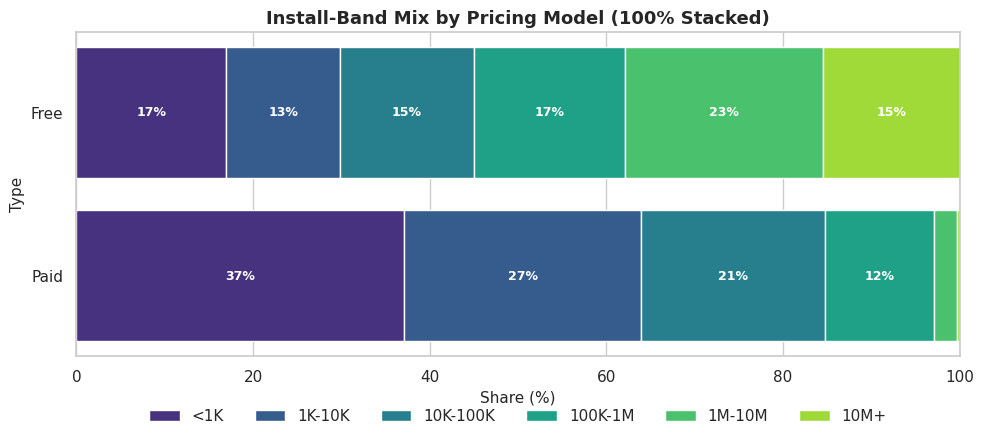

Install_Band,<1K,1K-10K,10K-100K,100K-1M,1M-10M,10M+
Type,,,,,,
Free,17.00,12.90,15.10,17.10,22.50,15.40
Paid,37.10,26.80,20.80,12.30,2.70,0.30


Share with 100K+ installs: {'Free': 55.0, 'Paid': 15.3}
Share with under 1K installs: {'Free': 17.0, 'Paid': 37.1}
Mann-Whitney p (installs, paid vs free): 7.96e-116 | Cliff's delta (paid vs free): -0.499
Median installs: {'Free': 100000.0, 'Paid': 1000.0}


In [42]:
ct = pd.crosstab(apps["Type"], apps["Install_Band"], normalize="index").loc[FREE_PAID, INSTALL_BAND_ORDER]
pal = dict(zip(INSTALL_BAND_ORDER, sns.color_palette("viridis", 6).as_hex()))
plot_stacked_pct(ct, "Install-Band Mix by Pricing Model (100% Stacked)", "Type", "30_install_band_by_type", INSTALL_BAND_ORDER, pal, figsize=(10, 4.6))
display((ct * 100).round(1))
print("Share with 100K+ installs:", ((apps.groupby("Type")["Installs_count"].apply(lambda s: (s >= 100_000).mean())) * 100).round(1).to_dict())
print("Share with under 1K installs:", ((apps.groupby("Type")["Installs_count"].apply(lambda s: (s < 1000).mean())) * 100).round(1).to_dict())
mw = stats.mannwhitneyu(apps.loc[apps["Type"] == "Paid", "Installs_count"], apps.loc[apps["Type"] == "Free", "Installs_count"])
print(f"Mann-Whitney p (installs, paid vs free): {mw.pvalue:.2e} | Cliff's delta (paid vs free): {cliffs_delta(apps.loc[apps['Type'] == 'Paid', 'Installs_count'], apps.loc[apps['Type'] == 'Free', 'Installs_count']):+.3f}")
print("Median installs:", apps.groupby("Type")["Installs_count"].median().to_dict())

**Why this chart:** Free and paid apps differ in reach. A 100% stacked bar shows how each pricing model spreads across the install bands.

**Insight:** The gap is large. 37.1% of paid apps have under 1,000 installs (17.0% of free apps), and only 3.0% of paid apps reach 1M+ installs against 37.9% of free apps; just 0.3% of paid apps have 10M+ installs against 15.4% of free apps. 55.0% of free apps have 100K+ installs against 15.3% of paid apps. The difference is significant and large (Mann-Whitney p < 0.0001, Cliff's delta −0.50), with medians of 1,000 against 100,000.

**Business impact:** Negative for the paid-first model. Price is a strong barrier to installs. Action: consider a free entry version (freemium) to reach scale, or accept a niche audience if you charge up front.

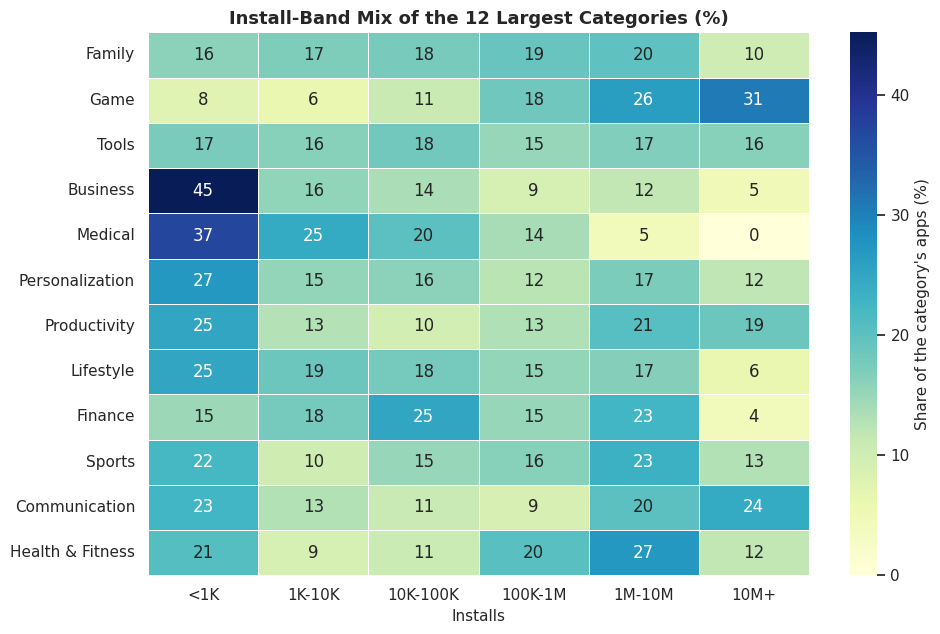

Install_Band,<1K,1K-10K,10K-100K,100K-1M,1M-10M,10M+
Category_Label,,,,,,
Family,16.10,17.10,17.50,19.20,19.90,10.30
Game,7.60,6.00,10.90,18.40,26.30,30.80
Tools,17.40,16.30,18.10,15.10,16.90,16.30
Business,45.20,15.70,13.60,9.00,11.70,4.80
Medical,37.00,24.60,20.00,13.90,4.60,0.00
Personalization,27.10,15.40,16.00,12.20,17.30,12.00
Productivity,25.10,12.80,9.60,13.10,20.60,18.70
Lifestyle,25.20,18.70,17.90,15.40,16.50,6.20
Finance,14.80,18.00,25.20,15.10,22.60,4.30


Highest 10M+ share: {'Game': 30.8, 'Communication': 24.4, 'Productivity': 18.7} | lowest: {'Medical': 0.0, 'Finance': 4.3, 'Business': 4.8}
Highest share under 10K installs (<1K + 1K-10K): {'Medical': 61.5, 'Business': 61.0, 'Lifestyle': 43.9}
Lowest share under 10K installs: {'Game': 13.6, 'Health & Fitness': 29.9, 'Sports': 32.3}
Chi-square, category vs install band (all categories): p = 3.67e-273


In [43]:
tc = list(apps["Category_Label"].value_counts().head(12).index)
hm = pd.crosstab(apps["Category_Label"], apps["Install_Band"], normalize="index").loc[tc, INSTALL_BAND_ORDER] * 100
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.grid(False)
sns.heatmap(hm, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=0.5, linecolor="white", cbar_kws={"label": "Share of the category's apps (%)"}, ax=ax)
ax.set(title="Install-Band Mix of the 12 Largest Categories (%)", xlabel="Installs", ylabel="")
fig.tight_layout()
save_fig(fig, "31_category_install_band_heatmap")

display(hm.round(1))
print("Highest 10M+ share:", hm["10M+"].sort_values(ascending=False).head(3).round(1).to_dict(), "| lowest:", hm["10M+"].sort_values().head(3).round(1).to_dict())
print("Highest share under 10K installs (<1K + 1K-10K):", (hm["<1K"] + hm["1K-10K"]).sort_values(ascending=False).head(3).round(1).to_dict())
print("Lowest share under 10K installs:", (hm["<1K"] + hm["1K-10K"]).sort_values().head(3).round(1).to_dict())
print("Chi-square, category vs install band (all categories):", f"p = {stats.chi2_contingency(pd.crosstab(apps['Category'], apps['Install_Band']))[1]:.2e}")

**Why this chart:** A heatmap of install bands by category shows where the mass-reach apps are and where apps stay small.

**Insight:** Game has the most large apps: 30.8% reach 10M+ installs, and only 13.6% stay under 10K. Communication (24.4%) and Productivity (18.7%) also have high 10M+ shares. At the other extreme, no Medical app reaches 10M installs, and 61.5% of Medical apps and 61.0% of Business apps stay under 10K installs (Lifestyle: 43.9%). The mix of install bands depends strongly on category (chi-square p < 0.0001).

**Business impact:** Mixed. Category sets the ceiling for reach. Action: benchmark against the category's own bands, and in Medical or Business define success as niche adoption and revenue per user instead of installs.

## 14. Multivariate analysis

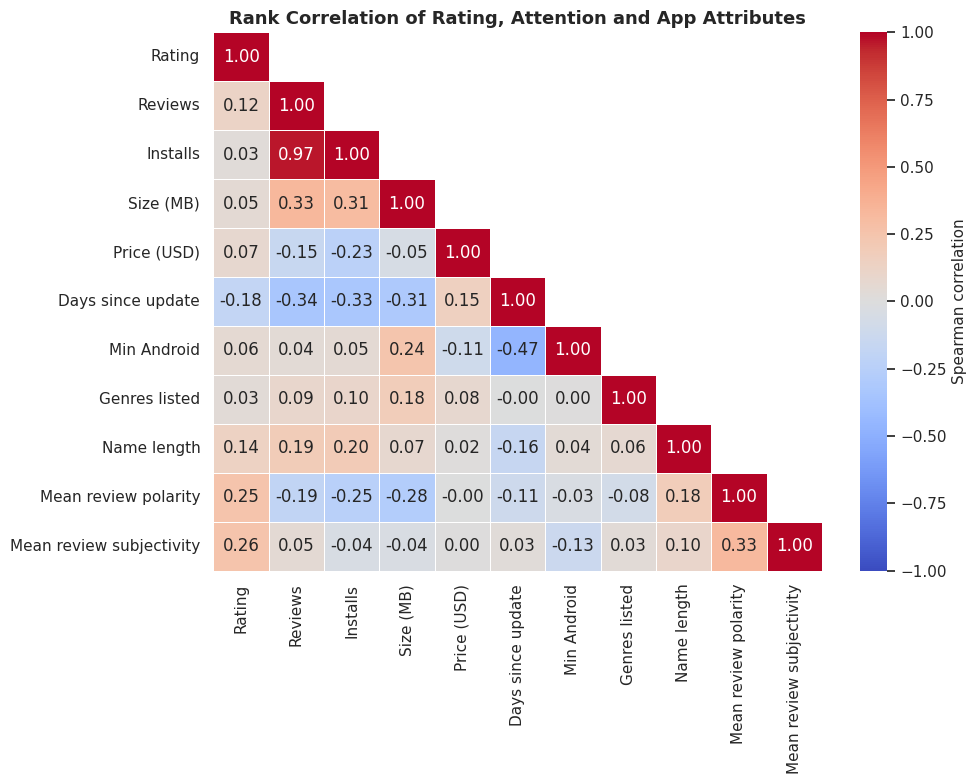

Correlation with Rating:
 Reviews                     0.12
Installs                    0.03
Size (MB)                   0.05
Price (USD)                 0.07
Days since update          -0.18
Min Android                 0.06
Genres listed               0.03
Name length                 0.14
Mean review polarity        0.25
Mean review subjectivity    0.26
Reviews vs Installs: +0.97
Installs vs Size (MB): +0.31
Installs vs Price (USD): -0.23
Installs vs Days since update: -0.33
Installs vs Min Android: +0.05
Size (MB) vs Min Android: +0.24
Rating vs Mean review polarity: +0.25
Reviews vs Mean review polarity: -0.19
Days since update vs Min Android: -0.47
Pairs used per correlation are pairwise complete; apps with review text: 816


In [44]:
corr_cols = {"Rating": "Rating", "Reviews": "Reviews", "Installs_count": "Installs", "Size_MB": "Size (MB)", "Price_USD": "Price (USD)",
             "Days_Since_Update": "Days since update", "Min_Android": "Min Android", "n_genres": "Genres listed", "Name_Length": "Name length",
             "mean_polarity": "Mean review polarity", "mean_subjectivity": "Mean review subjectivity"}
# Spearman (rank) correlation because reviews, installs and price are heavily right-skewed.
corr = apps[list(corr_cols)].rename(columns=corr_cols).corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(10, 8))
ax.grid(False)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.5, cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set(title="Rank Correlation of Rating, Attention and App Attributes")
fig.tight_layout()
save_fig(fig, "32_correlation_heatmap")

print("Correlation with Rating:\n", corr["Rating"].drop("Rating").round(2).to_string())
for a, b in [("Reviews", "Installs"), ("Installs", "Size (MB)"), ("Installs", "Price (USD)"), ("Installs", "Days since update"), ("Installs", "Min Android"),
             ("Size (MB)", "Min Android"), ("Rating", "Mean review polarity"), ("Reviews", "Mean review polarity"), ("Days since update", "Min Android")]:
    print(f"{a} vs {b}: {corr.loc[a, b]:+.2f}")
print("Pairs used per correlation are pairwise complete; apps with review text:", int(apps["has_text_reviews"].sum()))

**Why this chart:** A correlation heatmap summarises how all numeric fields move together. Rank (Spearman) correlation is used because reviews, installs and price are heavily skewed.

**Insight:** Reach variables move together: reviews and installs 0.97, installs with size 0.31 and with days since update −0.33. Rating is linked to little: the strongest links are with average review subjectivity (0.26) and polarity (0.25), then days since update (−0.18), name length (0.14) and reviews (0.12), and near zero for installs (0.03), size (0.05), price (0.07) and genres listed (0.03). Newer Android requirements go with fresher apps (days since update vs minimum Android −0.47), and installs fall as price rises (−0.23).

**Business impact:** Neutral to positive. Simple app attributes do not predict rating, which is why category and pricing model matter more (charts 15–17). Action: keep only one of reviews and installs in any model, and treat sentiment features as a separate signal rather than a predictor available at launch.

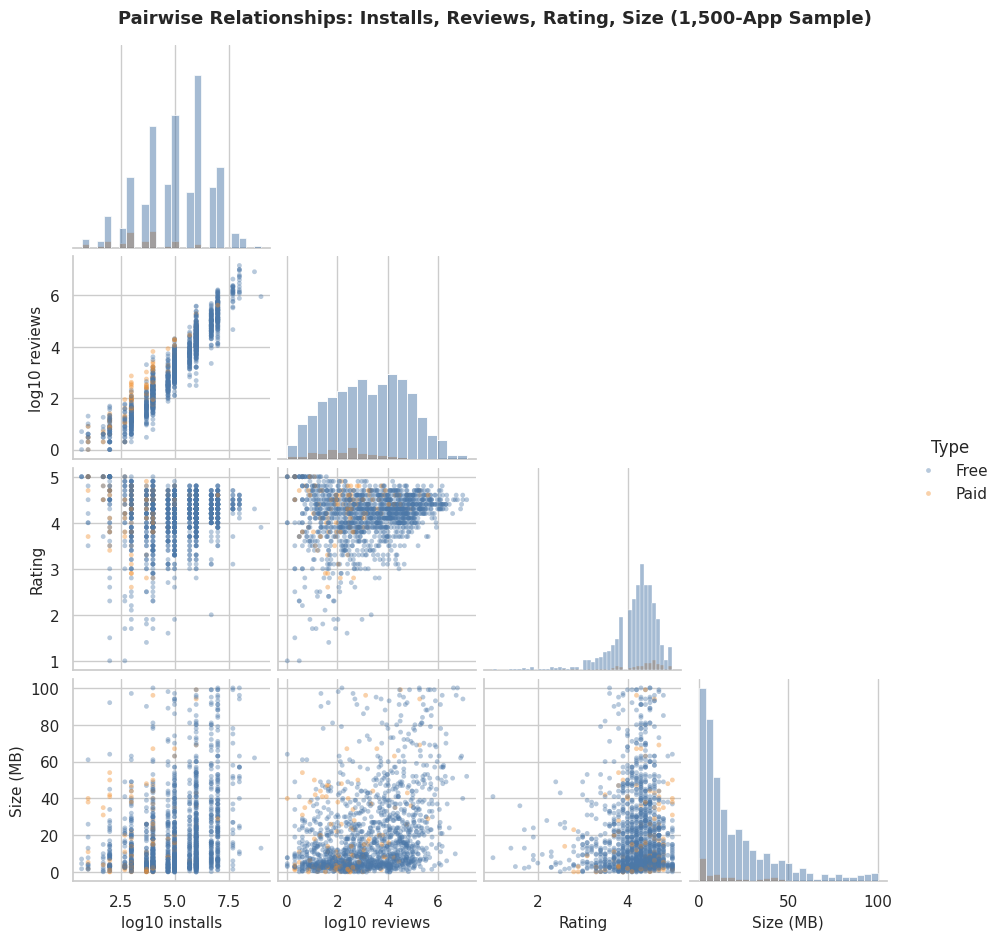

Rows with all four fields: 7,026 | sampled: 1,500 | paid apps in the full set: 539
                log10 installs  log10 reviews  Rating  Size (MB)
log10 installs            1.00           0.96   -0.00       0.33
log10 reviews             0.96           1.00    0.09       0.36
Rating                   -0.00           0.09    1.00       0.05
Size (MB)                 0.33           0.36    0.05       1.00
Median size by type in the full set: {'Free': 13.0, 'Paid': 11.0} | median rating: {'Free': 4.3, 'Paid': 4.4}


In [45]:
pair_cols = {"log10_installs": "log10 installs", "log10_reviews": "log10 reviews", "Rating": "Rating", "Size_MB": "Size (MB)"}
pair = apps[list(pair_cols) + ["Type"]].dropna().rename(columns=pair_cols)
pair_sample = pair.sample(1500, random_state=SEED)      # sampled so the grid stays fast and readable
g = sns.pairplot(pair_sample, hue="Type", hue_order=FREE_PAID, palette=PALETTE_TYPE, corner=True, diag_kind="hist", height=2.3,
                 plot_kws={"alpha": 0.4, "s": 12, "edgecolor": "none"})
g.figure.suptitle("Pairwise Relationships: Installs, Reviews, Rating, Size (1,500-App Sample)", y=1.02, fontsize=13, fontweight="bold")
save_fig(g.figure, "33_pairplot_key_metrics")

print(f"Rows with all four fields: {len(pair):,} | sampled: {len(pair_sample):,} | paid apps in the full set: {(pair['Type'] == 'Paid').sum()}")
print(pair.drop(columns="Type").corr(method="spearman").round(2).to_string())
print("Median size by type in the full set:", pair.groupby("Type")["Size (MB)"].median().round(1).to_dict(), "| median rating:", pair.groupby("Type")["Rating"].median().to_dict())

**Why this chart:** A pairplot shows several relationships at once and reveals shape, clusters and outliers. Log10 values and a 1,500-app sample keep it readable and fast, and colour separates free from paid apps.

**Insight:** Using 7,026 apps that have all four fields, log installs and log reviews are tightly linked (0.96) and size has a moderate link with both (0.33 and 0.36), while rating is almost unrelated to reach (−0.00 with installs, 0.09 with reviews). Paid apps (539 in the full set) sit at the low end of installs and reviews, but at the higher end of rating (median 4.4 against 4.3). Median size is 13 MB for free apps and 11 MB for paid apps.

**Business impact:** Positive. Rating and reach are separate dimensions, so a complete review of an app needs both. Action: report reach (installs or reviews), quality (rating) and engagement (reviews per install) together, never a single score.

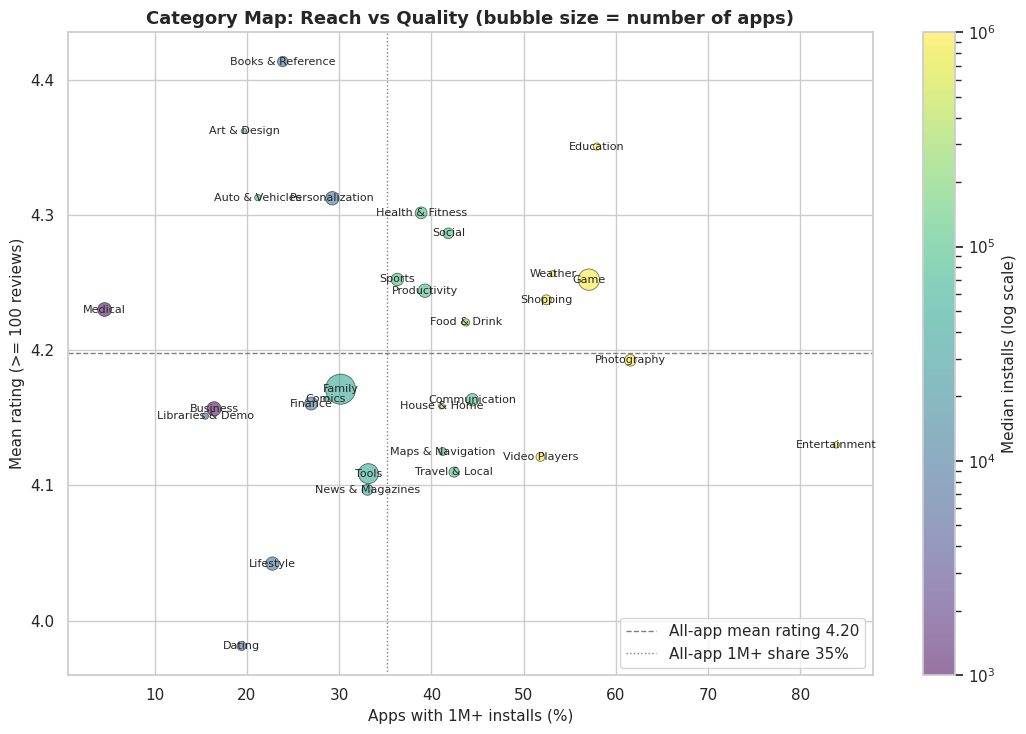

Categories plotted: 30
Above-average reach AND above-average rating: ['Education', 'Food & Drink', 'Game', 'Health & Fitness', 'Productivity', 'Shopping', 'Social', 'Sports', 'Weather']
Above-average reach but below-average rating: ['Communication', 'Entertainment', 'House & Home', 'Maps & Navigation', 'Photography', 'Travel & Local', 'Video Players']
High quality but low reach (under-exposed): ['Art & Design', 'Auto & Vehicles', 'Books & Reference', 'Medical', 'Personalization']
Spearman(category 1M+ share, category mean rating): 0.073


In [46]:
cm = (rel.groupby("Category_Label").agg(n_rel=("App", "count"), mean_rating=("Rating", "mean")).join(
      apps.groupby("Category_Label").agg(n=("App", "count"), share_1m=("Installs_count", lambda s: (s >= 1_000_000).mean() * 100), median_installs=("Installs_count", "median")))
      .query("n_rel >= @MIN_APPS"))
fig, ax = plt.subplots(figsize=(11, 7.5))
sc = ax.scatter(cm["share_1m"], cm["mean_rating"], s=cm["n"] / 4, alpha=0.55, c=cm["median_installs"], cmap="viridis", edgecolors="black", linewidths=0.6, norm=plt.matplotlib.colors.LogNorm())
for name, r_ in cm.iterrows():
    ax.annotate(name, (r_["share_1m"], r_["mean_rating"]), fontsize=8, ha="center", va="center")
ax.axhline(rel["Rating"].mean(), color="grey", ls="--", lw=1, label=f"All-app mean rating {rel['Rating'].mean():.2f}")
ax.axvline((apps["Installs_count"] >= 1_000_000).mean() * 100, color="grey", ls=":", lw=1, label=f"All-app 1M+ share {(apps['Installs_count'] >= 1_000_000).mean() * 100:.0f}%")
cb = fig.colorbar(sc, ax=ax)
cb.set_label("Median installs (log scale)")
ax.set(title="Category Map: Reach vs Quality (bubble size = number of apps)", xlabel="Apps with 1M+ installs (%)", ylabel="Mean rating (>= 100 reviews)")
ax.legend(frameon=True, loc="lower right")
fig.tight_layout()
save_fig(fig, "34_category_reach_vs_quality")

print(f"Categories plotted: {len(cm)}")
hi_reach = cm[cm["share_1m"] > (apps["Installs_count"] >= 1_000_000).mean() * 100]
print("Above-average reach AND above-average rating:", sorted(hi_reach[hi_reach["mean_rating"] > rel["Rating"].mean()].index.tolist()))
print("Above-average reach but below-average rating:", sorted(hi_reach[hi_reach["mean_rating"] <= rel["Rating"].mean()].index.tolist()))
lo = cm[cm["share_1m"] <= (apps["Installs_count"] >= 1_000_000).mean() * 100]
print("High quality but low reach (under-exposed):", sorted(lo[lo["mean_rating"] > rel["Rating"].mean()].index.tolist()))
print("Spearman(category 1M+ share, category mean rating):", round(cm["share_1m"].corr(cm["mean_rating"], method="spearman"), 3))

**Why this chart:** A category map puts reach and quality side by side, so categories that are good but under-exposed, or popular but weak, stand out.

**Insight:** Of 30 categories with enough reliable ratings, nine have above-average reach and above-average rating (Education, Food & Drink, Game, Health & Fitness, Productivity, Shopping, Social, Sports, Weather). Seven have above-average reach but below-average rating (Communication, Entertainment, House & Home, Maps & Navigation, Photography, Travel & Local, Video Players). Five combine above-average rating with below-average reach: Art & Design, Auto & Vehicles, Books & Reference, Medical and Personalization. Across categories, reach and rating are essentially unrelated (rank correlation 0.07).

**Business impact:** Positive for strategy. The 'good but under-exposed' group is where discovery and marketing can create the most value, and the 'popular but weak' group is where a better app can win. Action: enter a weak-rated, high-reach category with a clearly better product, or a high-rated, low-reach category with a strong discovery plan.

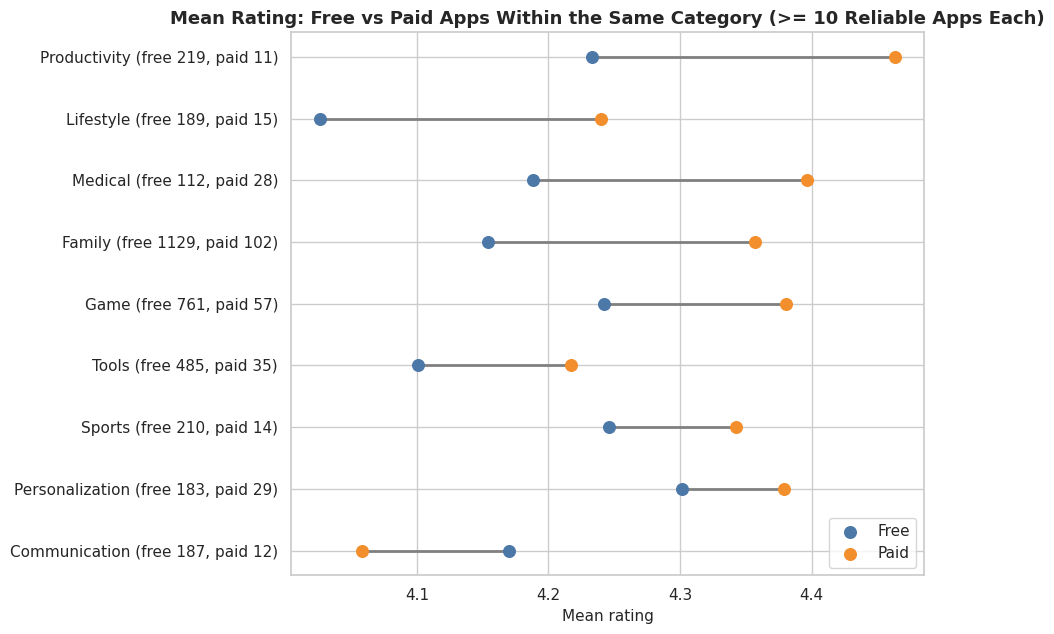

Categories with at least 10 reliably rated free and paid apps: 9
Paid rated higher in: 8 of 9 | largest paid advantage: {'Medical': 0.21, 'Lifestyle': 0.21, 'Productivity': 0.23} | paid lower: {'Communication': -0.11, 'Personalization': 0.08, 'Sports': 0.1}
Average within-category gap (paid - free): +0.130 stars | overall gap ignoring category: +0.157


In [47]:
pv = (rel.groupby(["Category_Label", "Type"])["Rating"].agg(["count", "mean"]).unstack("Type"))
pv = pv[(pv[("count", "Free")] >= 10) & (pv[("count", "Paid")] >= 10)]
pv["gap"] = pv[("mean", "Paid")] - pv[("mean", "Free")]
pv = pv.sort_values("gap")
fig, ax = plt.subplots(figsize=(9.5, 6.5))
y = np.arange(len(pv))
ax.hlines(y, pv[("mean", "Free")], pv[("mean", "Paid")], color="grey", lw=2, zorder=1)
ax.scatter(pv[("mean", "Free")], y, color=PALETTE_TYPE["Free"], s=70, label="Free", zorder=2)
ax.scatter(pv[("mean", "Paid")], y, color=PALETTE_TYPE["Paid"], s=70, label="Paid", zorder=2)
ax.set_yticks(y)
ax.set_yticklabels([f"{c} (free {int(pv.loc[c, ('count', 'Free')])}, paid {int(pv.loc[c, ('count', 'Paid')])})" for c in pv.index])
ax.set(title=f"Mean Rating: Free vs Paid Apps Within the Same Category (>= 10 Reliable Apps Each)", xlabel="Mean rating", ylabel="")
ax.legend(frameon=True, loc="lower right")
fig.tight_layout()
save_fig(fig, "35_free_vs_paid_rating_by_category")

print(f"Categories with at least 10 reliably rated free and paid apps: {len(pv)}")
print("Paid rated higher in:", int((pv["gap"] > 0).sum()), "of", len(pv), "| largest paid advantage:", pv["gap"].tail(3).round(2).to_dict(), "| paid lower:", pv["gap"].head(3).round(2).to_dict())
print(f"Average within-category gap (paid - free): {pv['gap'].mean():+.3f} stars | overall gap ignoring category: {rel.loc[rel['Type'] == 'Paid', 'Rating'].mean() - rel.loc[rel['Type'] == 'Free', 'Rating'].mean():+.3f}")

**Why this chart:** The paid-versus-free rating gap might be caused by category mix. Comparing them inside the same category removes that effect.

**Insight:** In the 9 categories with at least 10 reliably rated free and paid apps, paid apps rate higher in 8, with an average gap of +0.13 stars against +0.16 overall. The largest gaps are Productivity (+0.23), Lifestyle and Medical (+0.21). Only Communication goes the other way (−0.11).

**Business impact:** Positive. Most of the paid-app rating advantage survives after controlling for category, so it is not just a category effect. Action: it is reasonable to expect a small rating lift for a paid app in most categories, but it comes with the reach cost seen in chart 30.

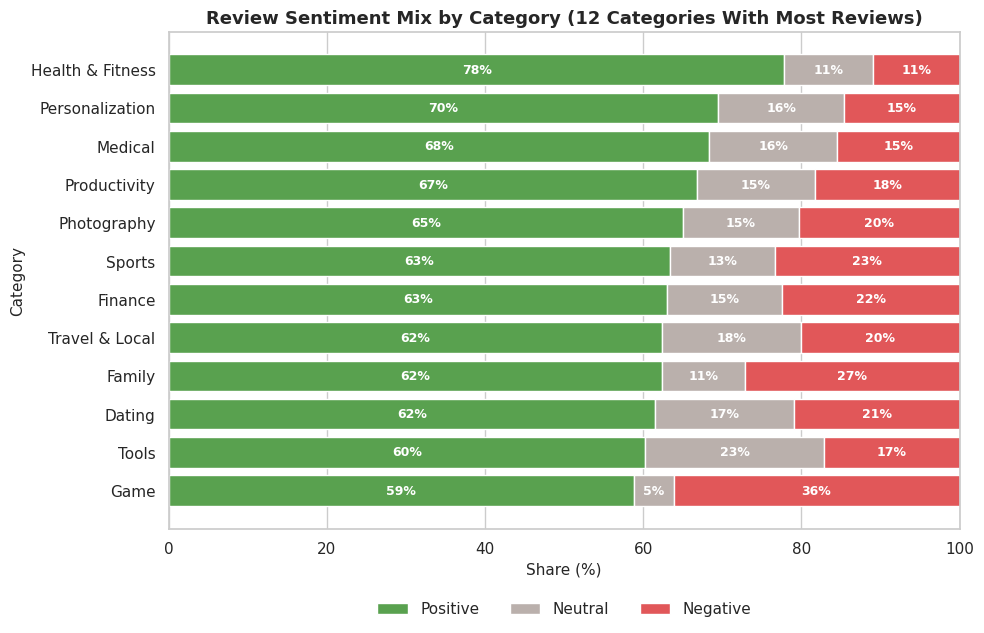

Sentiment,Positive,Neutral,Negative,reviews
Category_Label,,,,
Health & Fitness,77.90,11.20,11.00,1621
Personalization,69.50,15.90,14.60,961
Medical,68.30,16.20,15.50,1156
Productivity,66.80,14.90,18.30,1135
Photography,65.00,14.70,20.30,906
Sports,63.30,13.30,23.40,1216
Finance,62.90,14.60,22.50,1336
Travel & Local,62.40,17.50,20.10,1331
Family,62.30,10.60,27.10,2463


Joined reviews: 28,250 across 33 categories | overall positive 64.2%, negative 21.4%
Highest positive share (>= 300 reviews): {'Health & Fitness': 77.9, 'Education': 75.3, 'Food & Drink': 74.1}
Highest negative share (>= 300 reviews): {'Game': 36.2, 'Social': 28.7, 'Family': 27.1}
Chi-square, category vs sentiment: p = 6.70e-258


In [48]:
tcs = list(sent["Category_Label"].value_counts().head(12).index)
ct = pd.crosstab(sent["Category_Label"], sent["Sentiment"], normalize="index").reindex(columns=SENTIMENT_ORDER).loc[tcs]
ct = ct.sort_values("Positive", ascending=False)
plot_stacked_pct(ct, "Review Sentiment Mix by Category (12 Categories With Most Reviews)", "Category", "36_sentiment_by_category", SENTIMENT_ORDER, PALETTE_SENT, figsize=(10, 6.5))

n_ = sent["Category_Label"].value_counts()
tab = (ct * 100).round(1)
tab["reviews"] = n_.reindex(tab.index).values
display(tab)
print(f"Joined reviews: {len(sent):,} across {sent['Category'].nunique()} categories | overall positive {(sent['Sentiment'] == 'Positive').mean():.1%}, negative {(sent['Sentiment'] == 'Negative').mean():.1%}")
allc = pd.crosstab(sent["Category_Label"], sent["Sentiment"], normalize="index")
big = allc[n_.reindex(allc.index) >= 300]
print("Highest positive share (>= 300 reviews):", (big["Positive"] * 100).sort_values(ascending=False).head(3).round(1).to_dict())
print("Highest negative share (>= 300 reviews):", (big["Negative"] * 100).sort_values(ascending=False).head(3).round(1).to_dict())
print("Chi-square, category vs sentiment:", f"p = {stats.chi2_contingency(pd.crosstab(sent['Category'], sent['Sentiment']))[1]:.2e}")

**Why this chart:** Sentiment shows how users feel beyond the star average. A 100% stacked bar compares sentiment in the twelve categories with the most reviews.

**Insight:** Health & Fitness is the most positive (77.9% positive, 11.0% negative), followed by Personalization (69.5%) and Medical (68.3%); among categories with 300+ reviews, Education (75.3%) and Food & Drink (74.1%) are also high. Game is the most negative (36.2% negative, only 58.8% positive, and just 5.1% neutral across 3,954 reviews), followed by Social (28.7%) and Family (27.1%). Sentiment depends strongly on category (chi-square p < 0.0001, Cramér's V 0.16).

**Business impact:** Mixed. Users of health, education and personalization apps are the happiest; game players are the most critical. Action: expect harsher feedback in Game, Social and Family and plan support, moderation and update speed accordingly.

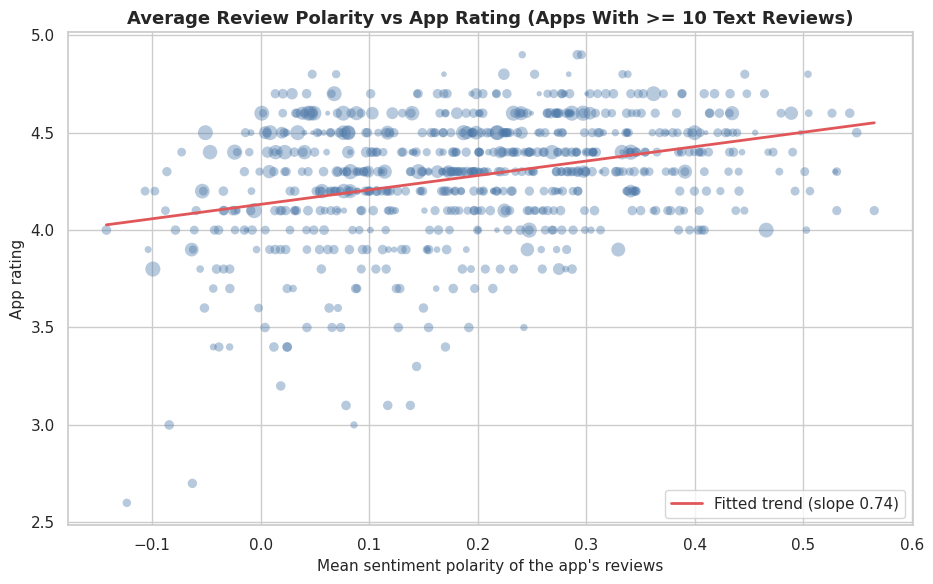

Apps: 725 | Spearman: 0.296 | Pearson: 0.329 | slope: 0.74 stars per polarity point
Mean polarity of apps: median 0.197 | range -0.14 to 0.57
Median rating by polarity quartile: {'Q1 lowest': 4.2, 'Q2': 4.3, 'Q3': 4.4, 'Q4 highest': 4.4}
Apps below 4.0 rating with mean polarity in the top quartile: 1 | apps at 4.5+ with lowest-quartile polarity: 45


In [49]:
d = apps.dropna(subset=["Rating", "mean_polarity"])
d = d[d["n_text_reviews"] >= 10]
fig, ax = plt.subplots(figsize=(9.5, 6))
ax.scatter(d["mean_polarity"], d["Rating"], s=np.clip(d["n_text_reviews"], 10, 100) * 1.2, alpha=0.4, color=BASE_COLOR, edgecolors="none")
slope, intercept = np.polyfit(d["mean_polarity"], d["Rating"], 1)
xs = np.linspace(d["mean_polarity"].min(), d["mean_polarity"].max(), 50)
ax.plot(xs, intercept + slope * xs, color="#E15759", lw=2, label=f"Fitted trend (slope {slope:.2f})")
ax.set(title="Average Review Polarity vs App Rating (Apps With >= 10 Text Reviews)", xlabel="Mean sentiment polarity of the app's reviews", ylabel="App rating")
ax.legend(frameon=True, loc="lower right")
fig.tight_layout()
save_fig(fig, "37_review_polarity_vs_rating")

print(f"Apps: {len(d)} | Spearman: {d['mean_polarity'].corr(d['Rating'], method='spearman'):.3f} | Pearson: {d['mean_polarity'].corr(d['Rating']):.3f} | slope: {slope:.2f} stars per polarity point")
print(f"Mean polarity of apps: median {d['mean_polarity'].median():.3f} | range {d['mean_polarity'].min():.2f} to {d['mean_polarity'].max():.2f}")
dd = d.assign(pol_q=pd.qcut(d["mean_polarity"], 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"]))
print("Median rating by polarity quartile:", dd.groupby("pol_q", observed=True)["Rating"].median().to_dict())
print("Apps below 4.0 rating with mean polarity in the top quartile:", int(((dd["Rating"] < 4) & (dd["pol_q"] == "Q4 highest")).sum()), "| apps at 4.5+ with lowest-quartile polarity:", int(((dd["Rating"] >= 4.5) & (dd["pol_q"] == "Q1 lowest")).sum()))

**Why this chart:** Star ratings and review text should agree. A scatter of each app's mean review polarity against its rating tests this for apps with at least 10 text reviews.

**Insight:** They agree only moderately (rank correlation 0.30 over 725 apps; a rise of 1 polarity point goes with 0.74 stars). Median rating by polarity quartile is 4.2, 4.3, 4.4 and 4.4 from lowest to highest. Only 1 app with a top-quartile polarity is rated below 4.0, but 45 apps rated 4.5+ sit in the lowest-polarity quartile. Mean app polarity ranges from −0.14 to +0.57 (median 0.20).

**Business impact:** Mixed. Text carries information the star rating hides, such as apps with high ratings but critical reviews. Action: use sentiment as a second signal beside the rating, and investigate high-rated apps with low polarity, since they may have a vocal group of unhappy users.

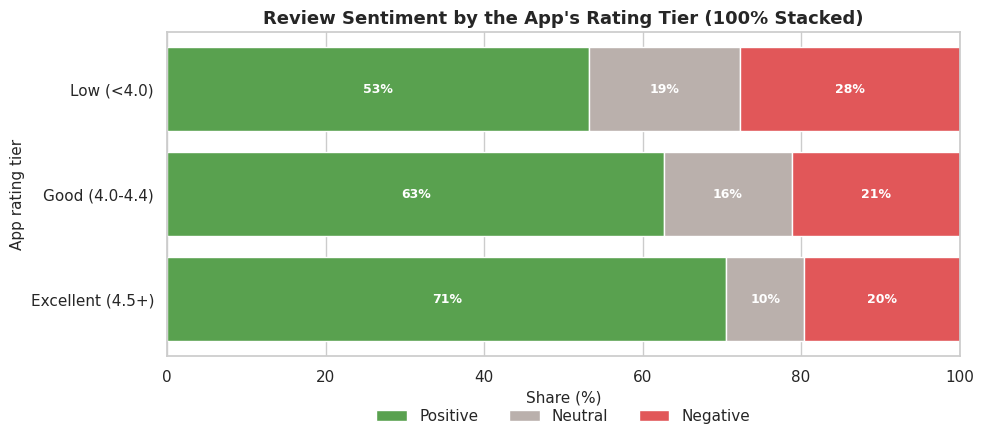

Sentiment,Positive,Neutral,Negative,reviews,apps
Rating_Tier,,,,,
Low (<4.0),53.20,19.00,27.80,3358,101
Good (4.0-4.4),62.70,16.10,21.20,15413,452
Excellent (4.5+),70.50,9.80,19.60,9479,263


Sentiment by pricing model (%):
Sentiment  Positive  Neutral  Negative
Type                                  
Free          64.10    14.40     21.50
Paid          75.60     7.90     16.50
Mean polarity by tier: {'Low (<4.0)': 0.093, 'Good (4.0-4.4)': 0.192, 'Excellent (4.5+)': 0.216}
Chi-square, rating tier vs sentiment: p = 2.04e-90


In [50]:
d = sent.dropna(subset=["Rating"]).copy()
d["Rating_Tier"] = pd.cut(d["Rating"], [0, 3.999, 4.499, 5], labels=RATING_TIER_ORDER)
ct = pd.crosstab(d["Rating_Tier"], d["Sentiment"], normalize="index").reindex(columns=SENTIMENT_ORDER).loc[RATING_TIER_ORDER]
plot_stacked_pct(ct, "Review Sentiment by the App's Rating Tier (100% Stacked)", "App rating tier", "38_sentiment_by_rating_tier", SENTIMENT_ORDER, PALETTE_SENT, figsize=(10, 4.6))
tab = (ct * 100).round(1)
tab["reviews"] = d["Rating_Tier"].value_counts().reindex(RATING_TIER_ORDER).values
tab["apps"] = d.groupby("Rating_Tier", observed=True)["App"].nunique().reindex(RATING_TIER_ORDER).values
display(tab)
tt = sent.groupby("Type")["Sentiment"].value_counts(normalize=True).unstack().reindex(columns=SENTIMENT_ORDER) * 100
print("Sentiment by pricing model (%):"); print(tt.round(1).to_string())
print("Mean polarity by tier:", d.groupby("Rating_Tier", observed=True)["Sentiment_Polarity"].mean().round(3).to_dict())
print("Chi-square, rating tier vs sentiment:", f"p = {stats.chi2_contingency(pd.crosstab(d['Rating_Tier'], d['Sentiment']))[1]:.2e}")

**Why this chart:** If the rating reflects user opinion, low-rated apps should attract more negative text. A stacked bar of sentiment by rating tier tests this.

**Insight:** Lower-rated apps do get more negative text: 27.8% of reviews for Low (<4.0) apps are negative and 53.2% positive, against 21.2% negative and 62.7% positive for Good apps and 19.6% negative and 70.5% positive for Excellent apps (chi-square p < 0.0001). Mean polarity rises from 0.093 to 0.192 to 0.216. Even Excellent apps still collect about one negative review in five. Paid apps look more positive (75.6% against 64.1% for free), but only 9 paid apps have text reviews, so that comparison is indicative only.

**Business impact:** Mixed. A good rating does not mean the absence of complaints. Action: every app, even a 4.5+ one, should have a standing process for reading negative reviews; do not rely on the paid-versus-free sentiment gap until more paid-app reviews are available.

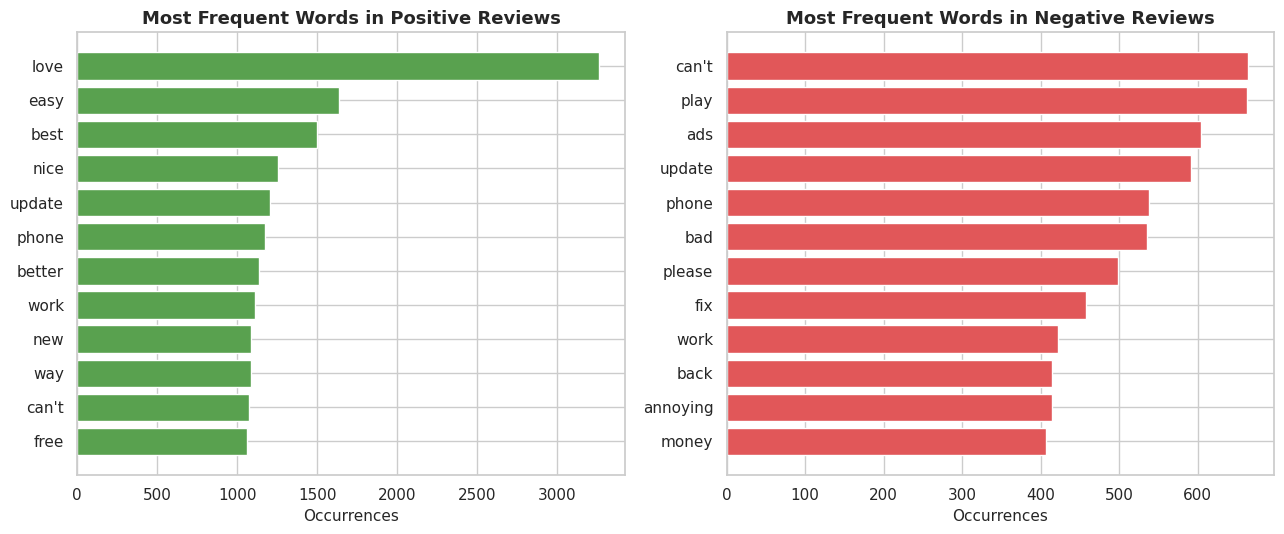

Top positive words: {'love': 3257, 'easy': 1635, 'best': 1498, 'nice': 1256, 'update': 1204, 'phone': 1170, 'better': 1135, 'work': 1112, 'new': 1088, 'way': 1084, "can't": 1074, 'free': 1059}
Top negative words: {"can't": 664, 'play': 663, 'ads': 604, 'update': 592, 'phone': 538, 'bad': 536, 'please': 498, 'fix': 458, 'work': 422, 'back': 415, 'annoying': 414, 'money': 407}
Most negative-leaning words (log-odds): ['worst', 'horrible', 'terrible', 'awful', 'stupid', 'hate', 'boring', 'unable', 'useless', 'fake', 'annoying', 'worse']
Most positive-leaning words (log-odds): ['awesome', 'best', 'easy', 'great', 'nice', 'perfect', 'amazing', 'helps', 'dating', 'love', 'easily', 'good']
Reviews mentioning 'ads': negative 8.1% vs positive 4.8%
Reviews mentioning 'crash / bug': negative 5.5% vs positive 2.9%
Reviews mentioning 'update': negative 9.7% vs positive 7.1%


Reviews mentioning 'money / pay': negative 12.3% vs positive 10.6%
Reviews mentioning 'login / account': negative 7.0% vs positive 3.4%


In [51]:
STOP = set("""a about after all also am an and any are as at be because been but by can could did do does don t for from get got had has have he her here him his how i if in into is it its just me
my no not now of on one or our out over she so some than that the their them then there these they this those to too up us very was we were what when which who will with would you your s m ll ve re d
""".split())
GENERIC = {"app", "apps", "game", "games", "really", "like", "use", "using", "used", "make", "makes", "good", "great", "time", "even", "much", "many", "every", "it's", "i'm", "don't", "also", "still", "well", "would"}   # filler words kept out of the frequency chart to reveal topical words
def tokens(text):
    return [w for w in re.findall(r"[a-z']+", text.lower()) if len(w) > 2 and w not in STOP]

pos_words, neg_words = Counter(), Counter()
for txt in reviews.loc[reviews["Sentiment"] == "Positive", "Translated_Review"]:
    pos_words.update(tokens(txt))
for txt in reviews.loc[reviews["Sentiment"] == "Negative", "Translated_Review"]:
    neg_words.update(tokens(txt))

def top_words(counter, k=12):
    return pd.Series({w: c for w, c in counter.most_common(80) if w not in GENERIC}).head(k)
tp, tn = top_words(pos_words), top_words(neg_words)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].barh(tp.index, tp.values, color=PALETTE_SENT["Positive"]); axes[0].invert_yaxis()
axes[0].set(title="Most Frequent Words in Positive Reviews", xlabel="Occurrences")
axes[1].barh(tn.index, tn.values, color=PALETTE_SENT["Negative"]); axes[1].invert_yaxis()
axes[1].set(title="Most Frequent Words in Negative Reviews", xlabel="Occurrences")
fig.tight_layout()
save_fig(fig, "39_top_words_by_sentiment")

print("Top positive words:", tp.to_dict())
print("Top negative words:", tn.to_dict())
tot_p, tot_n = sum(pos_words.values()), sum(neg_words.values())
lo = {w: np.log(((neg_words[w] + 1) / tot_n) / ((pos_words[w] + 1) / tot_p)) for w in neg_words if neg_words[w] >= 60 and pos_words[w] >= 10}
lo_pos = {w: np.log(((pos_words[w] + 1) / tot_p) / ((neg_words[w] + 1) / tot_n)) for w in pos_words if pos_words[w] >= 60 and neg_words[w] >= 10}
print("Most negative-leaning words (log-odds):", [w for w, _ in sorted(lo.items(), key=lambda kv: -kv[1])[:12]])
print("Most positive-leaning words (log-odds):", [w for w, _ in sorted(lo_pos.items(), key=lambda kv: -kv[1])[:12]])
issue_words = {"ads": ["ads", "ad", "advertisement", "advertisements"], "crash / bug": ["crash", "crashes", "bug", "bugs", "freezes", "glitch"], "update": ["update", "updates", "updated"], "money / pay": ["pay", "money", "paid", "price", "purchase", "expensive", "free"], "login / account": ["login", "log", "account", "password", "sign"]}
neg_docs = reviews.loc[reviews["Sentiment"] == "Negative", "Translated_Review"].str.lower()
pos_docs = reviews.loc[reviews["Sentiment"] == "Positive", "Translated_Review"].str.lower()
for theme, ws in issue_words.items():
    pat = r"\b(?:" + "|".join(ws) + r")\b"
    print(f"Reviews mentioning '{theme}': negative {neg_docs.str.contains(pat).mean():.1%} vs positive {pos_docs.str.contains(pat).mean():.1%}")

**Why this chart:** Frequencies of words show what users actually talk about. Two bar charts compare the most frequent words in positive and negative reviews, and a log-odds check finds the words that separate them best.

**Insight:** Positive reviews are dominated by 'love' (3,257 mentions), 'easy', 'best' and 'nice'. Negative reviews stress 'can't', 'play', 'ads', 'update' and 'bad'. The words most tied to negative reviews are worst, horrible, terrible, awful, stupid, hate, boring, unable, useless, fake and annoying, and those most tied to positive reviews are awesome, best, easy, great, nice, perfect, amazing and helps. Ads are mentioned in 8.1% of negative reviews against 4.8% of positive ones, crashes and bugs in 5.5% against 2.9%, login and account issues in 7.0% against 3.4%, and updates in 9.7% against 7.1%.

**Business impact:** Mixed. Praise is about simplicity, while complaints are about intrusive ads, crashes, sign-in and updates that break things: all controllable product decisions. Action: keep ad load moderate, test updates before release, keep login simple, and track these keywords in reviews as an early warning.

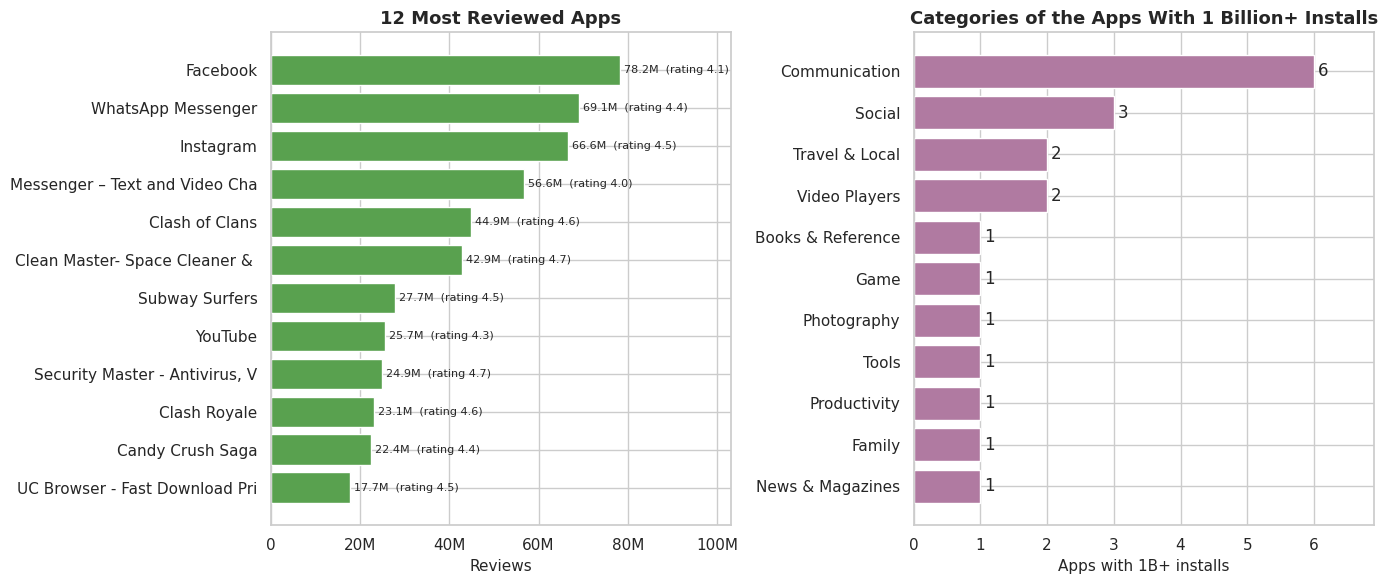

Most reviewed: [{'App': 'Facebook', 'Reviews': 78158306, 'Rating': 4.1, 'Category_Label': 'Social'}, {'App': 'WhatsApp Messenger', 'Reviews': 69119316, 'Rating': 4.4, 'Category_Label': 'Communication'}, {'App': 'Instagram', 'Reviews': 66577446, 'Rating': 4.5, 'Category_Label': 'Social'}, {'App': 'Messenger – Text and Video Chat for Free', 'Reviews': 56646578, 'Rating': 4.0, 'Category_Label': 'Communication'}, {'App': 'Clash of Clans', 'Reviews': 44893888, 'Rating': 4.6, 'Category_Label': 'Game'}, {'App': 'Clean Master- Space Cleaner & Antivirus', 'Reviews': 42916526, 'Rating': 4.7, 'Category_Label': 'Tools'}]
1B+ install apps: 20 | categories: {'Communication': 6, 'Social': 3, 'Travel & Local': 2, 'Video Players': 2, 'Books & Reference': 1, 'Game': 1, 'Photography': 1, 'Tools': 1, 'Productivity': 1, 'Family': 1, 'News & Magazines': 1}
Apps with 100M+ installs: 233 | median rating 4.40 | share rated 4.0+: 95.7% | all free: True | top categories: {'Game': 59, 'Tools': 29, 'Communication'

In [52]:
by_rev = apps.nlargest(12, "Reviews")[["App", "Category_Label", "Reviews", "Installs_count", "Rating", "Type"]]
by_inst = apps.nlargest(12, "Installs_count")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(by_rev["App"].str.slice(0, 30), by_rev["Reviews"], color="#59A14F"); axes[0].invert_yaxis()
axes[0].bar_label(axes[0].containers[0], labels=[f"{r/1e6:.1f}M  (rating {rt})" for r, rt in zip(by_rev["Reviews"], by_rev["Rating"])], padding=3, fontsize=8)
axes[0].set(title="12 Most Reviewed Apps", xlabel="Reviews", ylabel=""); axes[0].margins(x=0.32)
humanize_axis(axes[0], "x")
cat_mix = apps[apps["Installs_count"] >= 1_000_000_000]["Category_Label"].value_counts()
axes[1].barh(cat_mix.index, cat_mix.values, color="#B07AA1"); axes[1].invert_yaxis()
axes[1].bar_label(axes[1].containers[0], padding=3)
axes[1].set(title="Categories of the Apps With 1 Billion+ Installs", xlabel="Apps with 1B+ installs", ylabel=""); axes[1].margins(x=0.15)
fig.tight_layout()
save_fig(fig, "40_top_apps")

print("Most reviewed:", by_rev[["App", "Reviews", "Rating", "Category_Label"]].head(6).to_dict("records"))
print("1B+ install apps:", int((apps["Installs_count"] >= 1e9).sum()), "| categories:", cat_mix.to_dict())
big = apps[apps["Installs_count"] >= 100_000_000]
print(f"Apps with 100M+ installs: {len(big)} | median rating {big['Rating'].median():.2f} | share rated 4.0+: {(big['Rating'] >= 4).mean():.1%} | all free: {(big['Type'] == 'Free').all()} | top categories: {big['Category_Label'].value_counts().head(4).to_dict()}")
print(f"Top 12 most reviewed apps hold {apps.nlargest(12, 'Reviews')['Reviews'].sum() / apps['Reviews'].sum():.1%} of all reviews | top 100 apps hold {apps.nlargest(100, 'Reviews')['Reviews'].sum() / apps['Reviews'].sum():.1%}")

**Why this chart:** A few giants shape the market. Two panels show the most reviewed apps and the categories of the billion-install apps.

**Insight:** Facebook (78.2M reviews, rating 4.1), WhatsApp (69.1M, 4.4) and Instagram (66.6M, 4.5) lead in reviews. The 20 apps with 1B+ installs come mostly from Communication (6) and Social (3), with Travel & Local and Video Players (2 each). The 233 apps with 100M+ installs are all free, have a median rating of 4.40 and 95.7% are rated 4.0 or higher; Game (59), Tools (29) and Communication (27) lead. The top 12 apps hold 23.9% of all reviews and the top 100 hold 55.5%.

**Business impact:** Mixed. Scale is dominated by free communication, social and game platforms, and once an app reaches scale it almost never has a poor rating. Action: do not use giants as benchmarks for a new app; compare with apps at similar install bands in the same category.

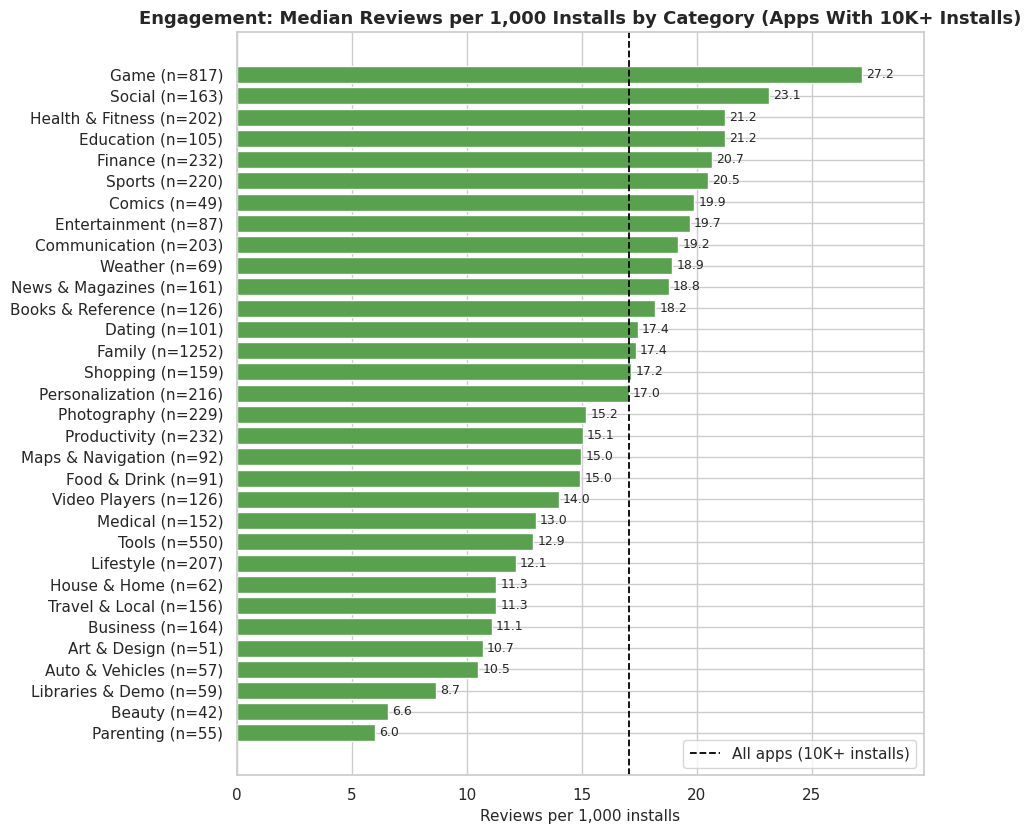

Categories shown: 32 | all-app median: 17.07
Most reviews per 1K installs: [{'Category_Label': 'Education', 'n': 105, 'median_rpk': 21.22}, {'Category_Label': 'Health & Fitness', 'n': 202, 'median_rpk': 21.24}, {'Category_Label': 'Social', 'n': 163, 'median_rpk': 23.14}, {'Category_Label': 'Game', 'n': 817, 'median_rpk': 27.17}]
Fewest: [{'Category_Label': 'Parenting', 'n': 55, 'median_rpk': 6.0}, {'Category_Label': 'Beauty', 'n': 42, 'median_rpk': 6.57}, {'Category_Label': 'Libraries & Demo', 'n': 59, 'median_rpk': 8.67}, {'Category_Label': 'Auto & Vehicles', 'n': 57, 'median_rpk': 10.51}]
Median reviews per 1K installs by type (10K+ installs): {'Free': 16.21, 'Paid': 82.47}


In [53]:
eng = (apps[(apps["Installs_count"] >= 10_000)].groupby(["Category", "Category_Label"]).agg(n=("App", "count"), median_rpk=("Reviews_per_1k_installs", "median")).reset_index()
          .query("n >= 30").sort_values("median_rpk"))
fig, ax = plt.subplots(figsize=(9.5, 8.5))
ax.barh([f"{c} (n={n})" for c, n in zip(eng["Category_Label"], eng["n"])], eng["median_rpk"], color="#59A14F")
ax.bar_label(ax.containers[0], labels=[f"{v:.1f}" for v in eng["median_rpk"]], padding=3, fontsize=9)
ax.axvline(apps.loc[apps["Installs_count"] >= 10_000, "Reviews_per_1k_installs"].median(), color="black", ls="--", lw=1.3, label="All apps (10K+ installs)")
ax.set(title="Engagement: Median Reviews per 1,000 Installs by Category (Apps With 10K+ Installs)", xlabel="Reviews per 1,000 installs", ylabel="")
ax.legend(frameon=True, loc="lower right")
ax.margins(x=0.1)
fig.tight_layout()
save_fig(fig, "41_reviews_per_1k_installs_by_category")

print(f"Categories shown: {len(eng)} | all-app median: {apps.loc[apps['Installs_count'] >= 10_000, 'Reviews_per_1k_installs'].median():.2f}")
print("Most reviews per 1K installs:", eng.tail(4)[["Category_Label", "n", "median_rpk"]].round(2).to_dict("records"))
print("Fewest:", eng.head(4)[["Category_Label", "n", "median_rpk"]].round(2).to_dict("records"))
print("Median reviews per 1K installs by type (10K+ installs):", apps[apps["Installs_count"] >= 10_000].groupby("Type")["Reviews_per_1k_installs"].median().round(2).to_dict())

**Why this chart:** Reviews per install measure how many users bother to respond, which is a proxy for engagement. Bars show the median by category for apps with 10K+ installs.

**Insight:** The median app collects 17.1 reviews per 1,000 installs. Game (27.2), Social (23.1), Health & Fitness (21.2) and Education (21.2) engage most, while Parenting (6.0), Beauty (6.6), Libraries & Demo (8.7) and Auto & Vehicles (10.5) engage least. Paid apps with 10K+ installs collect 82.5 reviews per 1,000 installs against 16.2 for free apps, five times as many.

**Business impact:** Positive for paid and game apps: users who pay or play heavily speak up. Action: use reviews per install as an engagement KPI in each category, and expect paid apps to need fewer installs to build a credible rating.

# Part B — Supporting tables and investigations
These tables back up the charts but are not charts themselves. Score columns marked *reliable* use only apps with at least 100 reviews.

### Category summary — apps, quality, reach and monetisation

In [54]:
category_summary = (apps.groupby("Category_Label").agg(apps=("App", "count"), median_installs=("Installs_count", "median"), paid_share_pct=("Is_Paid", lambda s: s.mean() * 100),
                    share_1m_pct=("Installs_count", lambda s: (s >= 1_000_000).mean() * 100), median_size_mb=("Size_MB", "median"))
    .join(rel.groupby("Category_Label")["Rating"].agg(reliable_apps="count", mean_rating_reliable="mean", median_rating_reliable="median"))
    .sort_values("apps", ascending=False))
category_summary["share_of_apps_pct"] = category_summary["apps"] / len(apps) * 100
display(category_summary.head(15))

,apps,median_installs,paid_share_pct,share_1m_pct,median_size_mb,reliable_apps,mean_rating_reliable,median_rating_reliable,share_of_apps_pct
Category_Label,,,,,,,,,
Family,1874,"50,000.00",9.82,30.15,19.00,1231,4.17,4.30,19.40
Game,946,"1,000,000.00",8.67,57.08,37.00,818,4.25,4.30,9.79
Tools,829,"50,000.00",9.41,33.17,4.20,520,4.11,4.20,8.58
Business,420,"1,000.00",2.86,16.43,8.60,145,4.16,4.30,4.35
Medical,395,"1,000.00",20.76,4.56,15.00,140,4.23,4.40,4.09
Personalization,376,"10,000.00",21.54,29.26,7.10,212,4.31,4.30,3.89
Productivity,374,"100,000.00",7.49,39.30,6.90,230,4.24,4.30,3.87
Lifestyle,369,"10,000.00",5.15,22.76,9.60,204,4.04,4.15,3.82
Finance,345,"10,000.00",4.93,26.96,12.00,225,4.16,4.30,3.57


### Genre summary

In [55]:
genre_summary = (apps.groupby("Primary_Genre").agg(apps=("App", "count"), median_installs=("Installs_count", "median"), paid_share_pct=("Is_Paid", lambda s: s.mean() * 100))
    .join(rel.groupby("Primary_Genre")["Rating"].agg(reliable_apps="count", median_rating_reliable="median"))
    .sort_values("apps", ascending=False))
display(genre_summary.head(15))
print("Genres with >= 40 reliable ratings, highest and lowest median rating:")
gg = genre_summary[genre_summary["reliable_apps"] >= 40].sort_values("median_rating_reliable")
display(pd.concat([gg.head(3), gg.tail(3)]))

,apps,median_installs,paid_share_pct,reliable_apps,median_rating_reliable
Primary_Genre,,,,,
Tools,829,"50,000.00",9.41,520,4.20
Entertainment,592,"50,000.00",3.21,371,4.20
Education,580,"10,000.00",8.79,307,4.40
Business,420,"1,000.00",2.86,145,4.30
Medical,395,"1,000.00",20.76,140,4.40
Personalization,376,"10,000.00",21.54,212,4.30
Productivity,374,"100,000.00",7.49,230,4.30
Lifestyle,370,"10,000.00",5.14,205,4.20
Finance,345,"10,000.00",4.93,225,4.30


Genres with >= 40 reliable ratings, highest and lowest median rating:


,apps,median_installs,paid_share_pct,reliable_apps,median_rating_reliable
Primary_Genre,,,,,
Dating,170,"10,000.00",2.94,101,4.10
Tools,829,"50,000.00",9.41,520,4.20
Lifestyle,370,"10,000.00",5.14,205,4.20
Comics,56,"100,000.00",0.00,47,4.40
Health & Fitness,290,"100,000.00",5.17,203,4.50
Books & Reference,225,"10,000.00",13.33,121,4.50


### Type summary — free vs paid

In [56]:
type_summary = (apps.groupby("Type").agg(apps=("App", "count"), median_installs=("Installs_count", "median"), median_reviews=("Reviews", "median"), median_size_mb=("Size_MB", "median"),
                 pct_updated_last_year=("Days_Since_Update", lambda s: (s <= 365).mean() * 100))
    .join(rel.groupby("Type")["Rating"].agg(median_rating_reliable="median", mean_rating_reliable="mean")))
display(type_summary.loc[FREE_PAID])

,apps,median_installs,median_reviews,median_size_mb,pct_updated_last_year,median_rating_reliable,mean_rating_reliable
Type,,,,,,,
Free,8905,"100,000.00","1,379.00",12.00,76.78,4.30,4.19
Paid,754,"1,000.00",88.50,9.40,53.85,4.40,4.35


### Content-rating summary

In [57]:
content_summary = (apps.groupby("Content_Rating").agg(apps=("App", "count"), median_installs=("Installs_count", "median"), paid_share_pct=("Is_Paid", lambda s: s.mean() * 100))
    .join(rated.groupby("Content_Rating")["Rating"].median().rename("median_rating")).reindex(CONTENT_ORDER))
display(content_summary)

,apps,median_installs,paid_share_pct,median_rating
Content_Rating,,,,
Everyone,7903,"50,000.00",8.26,4.30
Everyone 10+,322,"1,000,000.00",9.63,4.30
Teen,1036,"500,000.00",5.02,4.30
Mature 17+,393,"500,000.00",4.58,4.20
Adults only 18+,3,"500,000.00",0.00,4.50
Unrated,2,"25,250.00",0.00,4.10


### Install-band summary

In [58]:
install_summary = (apps.groupby("Install_Band", observed=True).agg(apps=("App", "count"), median_reviews=("Reviews", "median"), paid_share_pct=("Is_Paid", lambda s: s.mean() * 100),
                    median_size_mb=("Size_MB", "median"), median_days_since_update=("Days_Since_Update", "median"))
    .join(rated.groupby("Install_Band", observed=True)["Rating"].median().rename("median_rating")))
display(install_summary)

,apps,median_reviews,paid_share_pct,median_size_mb,median_days_since_update,median_rating
Install_Band,,,,,,
<1K,1790,2.00,15.64,8.30,170.00,4.60
1K-10K,1355,27.00,14.91,7.60,219.00,4.20
10K-100K,1499,218.00,10.47,9.00,188.00,4.20
100K-1M,1617,"2,469.00",5.75,13.00,105.00,4.20
1M-10M,2024,"30,649.00",0.99,19.00,42.00,4.30
10M+,1374,"365,871.00",0.15,27.00,21.00,4.40


### Update-year summary

In [59]:
year_summary = (apps.groupby("Update_Year").agg(apps=("App", "count"), median_installs=("Installs_count", "median"), paid_share_pct=("Is_Paid", lambda s: s.mean() * 100), median_min_android=("Min_Android", "median"))
    .join(rated.groupby("Update_Year")["Rating"].median().rename("median_rating")))
display(year_summary)

,apps,median_installs,paid_share_pct,median_min_android,median_rating
Update_Year,,,,,
2010,1,"100,000.00",0.00,1.50,4.20
2011,15,"50,000.00",20.00,1.60,4.00
2012,26,"75,000.00",19.23,2.10,4.00
2013,108,"10,000.00",25.93,2.20,4.10
2014,203,"10,000.00",26.60,2.30,4.10
2015,448,"10,000.00",17.86,2.30,4.10
2016,779,"10,000.00",11.55,4.00,4.20
2017,1792,"10,000.00",9.49,4.00,4.20
2018,6287,"100,000.00",5.15,4.10,4.30


### Sentiment summary by category

In [60]:
sent_cat = (sent.groupby("Category_Label").agg(reviews=("Sentiment", "size"), apps=("App", "nunique"), mean_polarity=("Sentiment_Polarity", "mean"),
                mean_subjectivity=("Sentiment_Subjectivity", "mean"), positive_pct=("Sentiment", lambda s: (s == "Positive").mean() * 100),
                negative_pct=("Sentiment", lambda s: (s == "Negative").mean() * 100)).sort_values("reviews", ascending=False))
display(sent_cat.head(12))

,reviews,apps,mean_polarity,mean_subjectivity,positive_pct,negative_pct
Category_Label,,,,,,
Game,3954,85,0.07,0.51,58.78,36.17
Family,2463,69,0.12,0.50,62.32,27.08
Health & Fitness,1621,40,0.29,0.51,77.85,10.98
Tools,1398,47,0.21,0.46,60.23,17.10
Finance,1336,39,0.17,0.48,62.95,22.46
Travel & Local,1331,42,0.21,0.49,62.43,20.06
Sports,1216,31,0.20,0.49,63.32,23.36
Medical,1156,33,0.23,0.48,68.34,15.48
Productivity,1135,37,0.19,0.48,66.78,18.33


### Standout apps — attention leaders, hidden gems and popular-but-poor apps

In [61]:
cols = ["App", "Category_Label", "Type", "Rating", "Reviews", "Installs_count"]
print("Most-installed apps (attention leaders)")
display(apps.nlargest(10, "Installs_count")[cols])
print(f"Highest-rated apps with at least 10,000 reviews (top 10)")
display(rated[rated["Reviews"] >= 10_000].nlargest(10, "Rating")[cols])
print("Lowest-rated apps with at least 10,000 reviews")
display(rated[rated["Reviews"] >= 10_000].nsmallest(10, "Rating")[cols])
gems = rated[(rated["Rating"] >= 4.7) & rated["Reviews"].between(MIN_REVIEWS, 4_999) & (rated["Installs_count"] <= 100_000)]
print(f"Hidden gems: rating 4.7+, {MIN_REVIEWS}-4,999 reviews, at most 100K installs (ten with the most reviews)")
display(gems.nlargest(10, "Reviews")[cols])
print(f"Hidden gems in total: {len(gems):,} | paid: {int(gems['Is_Paid'].sum())} | top categories: {gems['Category_Label'].value_counts().head(3).to_dict()}")
popular_poor = rated[(rated["Installs_count"] >= 1_000_000) & (rated["Rating"] < 3.8)]
print(f"Popular but poorly rated (1M+ installs, rating below 3.8): {len(popular_poor)}")
display(popular_poor.nsmallest(8, "Rating")[cols])

Most-installed apps (attention leaders)


,App,Category_Label,Type,Rating,Reviews,Installs_count
144,Google Play Books,Books & Reference,Free,3.90,1433233,1000000000
279,WhatsApp Messenger,Communication,Free,4.40,69119316,1000000000
304,Messenger – Text and Video Chat for Free,Communication,Free,4.00,56646578,1000000000
308,Skype - free IM & video calls,Communication,Free,4.10,10484169,1000000000
320,Google Chrome: Fast & Secure,Communication,Free,4.30,9643041,1000000000
347,Gmail,Communication,Free,4.30,4604483,1000000000
359,Hangouts,Communication,Free,4.00,3419513,1000000000
1352,Subway Surfers,Game,Free,4.50,27725352,1000000000
1875,Facebook,Social,Free,4.10,78158306,1000000000
1881,Google+,Social,Free,4.20,4831125,1000000000


Highest-rated apps with at least 10,000 reviews (top 10)


,App,Category_Label,Type,Rating,Reviews,Installs_count
51,Tickets SDA 2018 and Exam from the State Traff...,Auto & Vehicles,Free,4.90,10479,100000
75,Tickets + PDA 2018 Exam,Auto & Vehicles,Free,4.90,197136,1000000
95,"ipsy: Makeup, Beauty, and Tips",Beauty,Free,4.90,49790,1000000
531,"Learn Japanese, Korean, Chinese Offline & Free",Education,Free,4.90,133136,1000000
937,Lose Belly Fat in 30 Days - Flat Stomach,Health & Fitness,Free,4.90,38098,5000000
939,Six Pack in 30 Days - Abs Workout,Health & Fitness,Free,4.90,272337,10000000
978,StrongLifts 5x5 Workout Gym Log & Personal Tra...,Health & Fitness,Free,4.90,66791,1000000
1003,Down Dog: Great Yoga Anywhere,Health & Fitness,Free,4.90,28945,500000
1325,The Room: Old Sins,Game,Paid,4.90,21119,100000
2971,Hungry Hearts Diner: A Tale of Star-Crossed Souls,Family,Free,4.90,46253,500000


Lowest-rated apps with at least 10,000 reviews


,App,Category_Label,Type,Rating,Reviews,Installs_count
4496,PS4 Second Screen,Family,Free,2.40,11773,1000000
4142,Club Penguin Island,Family,Free,2.80,107441,1000000
4344,3D Holograms Joke,Family,Free,2.90,31596,5000000
5278,Lezhin Comics - Daily Releases,Comics,Free,3.00,28447,1000000
8228,TAMAGO,Family,Free,3.00,42515,5000000
8252,Egg for Pou,Family,Free,3.00,59096,5000000
370,eharmony - Online Dating App,Dating,Free,3.10,31320,5000000
1286,Will it Crush?,Game,Free,3.10,25825,5000000
2201,NBC Sports,Sports,Free,3.10,78442,5000000
2366,My Telcel,Tools,Free,3.10,45838,50000000


Hidden gems: rating 4.7+, 100-4,999 reviews, at most 100K installs (ten with the most reviews)


,App,Category_Label,Type,Rating,Reviews,Installs_count
6205,FlashLight HD LED Pro,Tools,Paid,4.70,4928,50000
7451,Day Night Live Wallpaper (All),Personalization,Paid,4.70,4856,50000
7736,DU Collage Maker - Photo Collage & Grid & Layout,Photography,Free,4.70,4595,100000
8766,PlugShare,Maps & Navigation,Free,4.70,4501,100000
7701,Riptide GP: Renegade,Game,Paid,4.70,4328,100000
1723,Baritastic - Bariatric Tracker,Medical,Free,4.70,4318,100000
209,ATI Cargoes and Transportation,Business,Free,4.70,4162,100000
4533,Five Nights at Flappy's,Game,Free,4.70,4041,10000
3785,"Abs, Core & Back Workout Challenge",Health & Fitness,Free,4.80,3908,100000
4136,Jamaa Amino for Animal Jam,Social,Free,4.70,3873,10000


Hidden gems in total: 203 | paid: 38 | top categories: {'Family': 37, 'Books & Reference': 14, 'Finance': 14}
Popular but poorly rated (1M+ installs, rating below 3.8): 243


,App,Category_Label,Type,Rating,Reviews,Installs_count
3962,AppFinder by AppTap,Tools,Free,2.00,2221,5000000
3749,Moto Z Market,Tools,Free,2.20,605,1000000
6969,CZ File Manager,Tools,Free,2.20,876,1000000
4496,PS4 Second Screen,Family,Free,2.40,11773,1000000
5620,BT Notifier,Tools,Free,2.50,2794,1000000
4655,AirWatch Inbox,Business,Free,2.70,8346,1000000
3196,How Old am I?,Family,Free,2.80,4635,1000000
4142,Club Penguin Island,Family,Free,2.80,107441,1000000


### Process-status fields (meaning of empty values preserved)

In [62]:
for name, col in [("Rating status", "rating_status"), ("Rating reliability", "rating_reliability"), ("Size status", "size_status")]:
    print(f"\n{name}")
    display(apps[col].value_counts(dropna=False).to_frame("count"))
print("\nApps by whether they have text reviews and type")
display(pd.crosstab(apps["Type"], apps["has_text_reviews"].map({1: "Has text reviews", 0: "No text reviews"})))
print("\nReviews by whether the app is in the app file")
display(reviews["In_PlayStore_Data"].value_counts().to_frame("reviews"))


Rating status


,count
rating_status,
Rated,8196
No rating shown,870
Never rated (0 reviews),593



Rating reliability


,count
rating_reliability,
Reliable (>= 100 reviews),6301
Thin (< 100 reviews),1895
Not rated,1463



Size status


,count
size_status,
Fixed size,8431
Varies with device,1228



Apps by whether they have text reviews and type


has_text_reviews,Has text reviews,No text reviews
Type,,
Free,807,8098
Paid,9,745



Reviews by whether the app is in the app file


,reviews
In_PlayStore_Data,
True,28250
False,1442


### Outlier investigation — extreme prices, sizes and suspicious ratings

In [63]:
print("Ten highest-priced apps")
display(apps.nlargest(10, "Price_USD")[["App", "Category_Label", "Price_USD", "Installs_count", "Rating", "Reviews"]])
print("Ten largest apps")
display(apps.nlargest(10, "Size_MB")[["App", "Category_Label", "Size_MB", "Installs_count", "Rating"]])
print("Apps with more reviews than the install-band floor")
display(apps[apps["flag_reviews_gt_installs"] == 1].sort_values("Reviews", ascending=False)[["App", "Reviews", "Installs_count", "Rating"]].head(10))
print(f"Perfect 5.0 ratings: {(rated['Rating'] == 5).sum()} | of them with fewer than 30 reviews: {int(apps['flag_perfect_thin'].sum())} | with 100+ reviews: {((rated['Rating'] == 5) & (rated['Reviews'] >= MIN_REVIEWS)).sum()}")
print(f"Novelty-priced apps ($100+): {int(apps['flag_novelty_price'].sum())} | their median installs: {apps.loc[apps['flag_novelty_price'] == 1, 'Installs_count'].median():,.0f} | share that are 'I am rich' style names: {apps.loc[apps['flag_novelty_price'] == 1, 'App'].str.contains('rich|Rich|expensive', regex=True).mean():.0%}")
print(f"Apps not updated for over 2 years: {int(apps['flag_stale_app'].sum()):,} | of those with 1M+ installs: {int(((apps['flag_stale_app'] == 1) & (apps['Installs_count'] >= 1_000_000)).sum())}")

Ten highest-priced apps


,App,Category_Label,Price_USD,Installs_count,Rating,Reviews
3316,I'm Rich - Trump Edition,Lifestyle,400.00,10000,3.60,275
3171,most expensive app (H),Family,399.99,100,4.30,6
3312,💎 I'm rich,Lifestyle,399.99,10000,3.80,718
4259,I am rich,Lifestyle,399.99,100000,3.80,3547
4261,I am Rich Plus,Family,399.99,10000,4.00,856
4263,I Am Rich Premium,Finance,399.99,50000,4.10,1867
4265,I am Rich!,Finance,399.99,1000,3.80,93
4266,I am rich(premium),Finance,399.99,5000,3.50,472
4269,I Am Rich Pro,Family,399.99,5000,4.40,201
4271,I am rich (Most expensive app),Finance,399.99,1000,4.10,129


Ten largest apps


,App,Category_Label,Size_MB,Installs_count,Rating
788,Post Bank,Finance,100.00,1000000,4.50
1179,Talking Babsy Baby: Baby Games,Lifestyle,100.00,10000000,4.00
1292,Mini Golf King - Multiplayer Game,Game,100.00,5000000,4.50
1430,Hungry Shark Evolution,Game,100.00,100000000,4.50
1675,Navi Radiography Pro,Medical,100.00,500,4.70
3624,Vi Trainer,Health & Fitness,100.00,5000,3.60
4329,Ultimate Tennis,Sports,100.00,10000000,4.30
4427,The Walking Dead: Our World,Game,100.00,1000000,4.00
4746,Miami crime simulator,Game,100.00,10000000,4.00
4748,Gangster Town: Vice District,Family,100.00,10000000,4.30


Apps with more reviews than the install-band floor


,App,Reviews,Installs_count,Rating
3599,Alarmy (Sleep If U Can) - Pro,10249,10000,4.80
7424,DN Blog,20,10,5.00
7918,DZ Puzzle,14,10,NaN
5378,Sam.BN Pro,11,10,NaN
6247,Trovami se ci riesci,11,10,5.00
5555,Brick Breaker BR,7,5,5.00
1803,KBA-EZ Health Guide,4,1,5.00
3493,RMEduS - 음성인식을 활용한 R 프로그래밍 실습 시스템,4,1,NaN
4799,Ra Ga Ba,2,1,5.00
4696,AX Watch for WatchMaker,2,1,NaN


Perfect 5.0 ratings: 271 | of them with fewer than 30 reviews: 254 | with 100+ reviews: 4
Novelty-priced apps ($100+): 20 | their median installs: 3,000 | share that are 'I am rich' style names: 75%
Apps not updated for over 2 years: 1,211 | of those with 1M+ installs: 227


### Outlier interpretation
The flag table in section 6 counts every unusual record without deleting any. Nine rules are used: a mega-app rule (100 million or more installs), Tukey fences for size and (paid) price, business rules for novelty prices ($100 or more), reviews above the install-band floor, ratings resting on fewer than 100 reviews, perfect 5.0 ratings on fewer than 30 reviews, and apps not updated for two years. (Log-scale Tukey fences on reviews and installs were tested and flag no app, because the heavy tail is symmetric on the log scale.)

Reading the tables above: the highest prices belong to a cluster of "I am rich" style novelty apps priced around $400 that were never meant as real utilities, so they distort mean price and any price-versus-quality reading (medians are used instead). Reviews above the install floor are mostly tiny apps at the lowest bands, where the floor is 1 or 5 installs, which is expected because the band is a lower bound. Perfect ratings are mostly an artefact of tiny samples: almost all 5.0 apps have fewer than 30 reviews. All of these records stay in the data and are flagged for review.

## 15. Statistical validation of the main findings

In [64]:
# Every headline comparison is backed by a non-parametric test (ratings, reviews and installs are skewed, so no normality is assumed)
# and by an effect size, so a 'significant' result is not mistaken for an important one.
rows = []
def add(name, test, stat, p, effect, note):
    rows.append({"question": name, "test": test, "statistic": stat, "p_value": p, "effect_size": effect, "reading": note})

a, b = rel.loc[rel["Type"] == "Paid", "Rating"], rel.loc[rel["Type"] == "Free", "Rating"]
mw = stats.mannwhitneyu(a, b); add("Do paid apps rate differently from free apps? (>=100 reviews)", "Mann-Whitney U", mw.statistic, mw.pvalue, f"Cliff's delta {cliffs_delta(a, b):+.2f}", "difference in ratings")
a, b = apps.loc[apps["Type"] == "Paid", "Installs_count"], apps.loc[apps["Type"] == "Free", "Installs_count"]
mw = stats.mannwhitneyu(a, b); add("Do paid apps get fewer installs?", "Mann-Whitney U", mw.statistic, mw.pvalue, f"Cliff's delta {cliffs_delta(a, b):+.2f}", "difference in installs")
cats = rel.groupby("Category").filter(lambda g: len(g) >= MIN_APPS)
kw = stats.kruskal(*[g["Rating"].values for _, g in cats.groupby("Category")])
eps = (kw.statistic - cats["Category"].nunique() + 1) / (len(cats) - cats["Category"].nunique()); add("Does rating differ across categories?", "Kruskal-Wallis", kw.statistic, kw.pvalue, f"epsilon-squared {eps:.3f}", "share of rating variance tied to category")
sp = stats.spearmanr(rel["Reviews"], rel["Rating"]); add("Do more-reviewed apps rate higher? (>=100 reviews)", "Spearman", sp.statistic, sp.pvalue, f"rho {sp.statistic:+.2f}", "rank correlation")
sp = stats.spearmanr(rated["Installs_count"], rated["Rating"]); add("Do more-installed apps rate higher? (all rated)", "Spearman", sp.statistic, sp.pvalue, f"rho {sp.statistic:+.2f}", "rank correlation")
d = apps.dropna(subset=["Rating", "mean_polarity"]); d = d[d["n_text_reviews"] >= 10]
sp = stats.spearmanr(d["mean_polarity"], d["Rating"]); add("Does review sentiment track app rating? (>=10 text reviews)", "Spearman", sp.statistic, sp.pvalue, f"rho {sp.statistic:+.2f}", "rank correlation")
d2 = apps.dropna(subset=["Size_MB"]); sp = stats.spearmanr(d2["Size_MB"], d2["Installs_count"]); add("Are larger apps installed more?", "Spearman", sp.statistic, sp.pvalue, f"rho {sp.statistic:+.2f}", "rank correlation")
sp = stats.spearmanr(apps["Days_Since_Update"], apps["Installs_count"]); add("Are recently updated apps installed more?", "Spearman", sp.statistic, sp.pvalue, f"rho {sp.statistic:+.2f}", "rank correlation")
ct_ = pd.crosstab(apps["Category"], apps["Type"]); chi = stats.chi2_contingency(ct_)
add("Does the paid share differ by category?", "Chi-square", chi[0], chi[1], f"Cramer's V {np.sqrt(chi[0] / (ct_.values.sum() * (min(ct_.shape) - 1))):.2f}", "association strength")
ct_ = pd.crosstab(sent["Category"], sent["Sentiment"]); chi = stats.chi2_contingency(ct_)
add("Does review sentiment differ by category?", "Chi-square", chi[0], chi[1], f"Cramer's V {np.sqrt(chi[0] / (ct_.values.sum() * (min(ct_.shape) - 1))):.2f}", "association strength")
tests = pd.DataFrame(rows)
tests["p_value"] = tests["p_value"].map(lambda p: "< 0.0001" if p < 1e-4 else f"{p:.4f}")
tests["statistic"] = tests["statistic"].map(lambda v: f"{v:,.2f}")
pd.set_option("display.max_colwidth", 80)
display(tests)

# Uncertainty: bootstrap 95% confidence intervals for the headline medians / means (fixed seed).
rng = np.random.default_rng(SEED)
def boot_ci(values, func=np.mean, n=2000):
    v = np.asarray(values); return np.percentile([func(rng.choice(v, len(v))) for _ in range(n)], [2.5, 97.5])
print("\nBootstrap 95% confidence intervals")
for label, vals in [("Mean rating, free (>=100 reviews)", rel.loc[rel["Type"] == "Free", "Rating"]), ("Mean rating, paid (>=100 reviews)", rel.loc[rel["Type"] == "Paid", "Rating"]),
                    ("Mean rating, all rated apps", rated["Rating"])]:
    lo_, hi_ = boot_ci(vals); print(f"  {label}: {np.mean(vals):.3f}  [{lo_:.3f}, {hi_:.3f}]")
lo_, hi_ = boot_ci(apps["Days_Since_Update"], np.median); print(f"  Median days since update: {apps['Days_Since_Update'].median():.0f}  [{lo_:.0f}, {hi_:.0f}]")

,question,test,statistic,p_value,effect_size,reading
0,Do paid apps rate differently from free apps? (>=100 reviews),Mann-Whitney U,"1,373,121.00",< 0.0001,Cliff's delta +0.26,difference in ratings
1,Do paid apps get fewer installs?,Mann-Whitney U,"1,682,679.50",< 0.0001,Cliff's delta -0.50,difference in installs
2,Does rating differ across categories?,Kruskal-Wallis,237.85,< 0.0001,epsilon-squared 0.034,share of rating variance tied to category
3,Do more-reviewed apps rate higher? (>=100 reviews),Spearman,0.26,< 0.0001,rho +0.26,rank correlation
4,Do more-installed apps rate higher? (all rated),Spearman,0.03,0.0138,rho +0.03,rank correlation
5,Does review sentiment track app rating? (>=10 text reviews),Spearman,0.30,< 0.0001,rho +0.30,rank correlation
6,Are larger apps installed more?,Spearman,0.31,< 0.0001,rho +0.31,rank correlation
7,Are recently updated apps installed more?,Spearman,-0.33,< 0.0001,rho -0.33,rank correlation
8,Does the paid share differ by category?,Chi-square,341.20,< 0.0001,Cramer's V 0.19,association strength
9,Does review sentiment differ by category?,Chi-square,"1,435.97",< 0.0001,Cramer's V 0.16,association strength



Bootstrap 95% confidence intervals


  Mean rating, free (>=100 reviews): 4.189  [4.178, 4.199]


  Mean rating, paid (>=100 reviews): 4.346  [4.305, 4.383]


  Mean rating, all rated apps: 4.173  [4.161, 4.185]


  Median days since update: 96  [88, 103]


**How to read this table.** A very small p-value only says the pattern is unlikely to be chance; the effect size says how large it is. With thousands of apps almost any difference is 'significant', so the conclusions in this notebook lean on the effect sizes and on the group sizes shown under each chart. Cliff's delta runs from −1 to +1 (0 means no difference), Spearman's rho measures rank correlation, and Cramér's V measures the strength of a link between two categorical fields (0 none, 1 perfect).

## 16. Evidence for the conclusion

In [65]:
# Numbers behind the conclusion and recommendations (all computed here, none typed by hand).
print("R1  A crowded, concentrated market")
cc = apps["Category_Label"].value_counts()
print(f"   Apps: {len(apps):,} | top 3 categories hold {cc.head(3).sum() / len(apps):.1%} | free apps {1 - apps['Is_Paid'].mean():.1%} | apps under 10K installs {(apps['Installs_count'] < 10_000).mean():.1%} | 1M+ installs {(apps['Installs_count'] >= 1_000_000).mean():.1%}")
i = apps["Installs_count"]
print(f"   Top 1% of apps hold {i.nlargest(int(len(i) * .01)).sum() / i.sum():.1%} of install-band volume; top 10% of apps hold {apps['Reviews'].nlargest(int(len(apps) * .1)).sum() / apps['Reviews'].sum():.1%} of reviews")

print("R2  Ratings are high and compressed, so they separate poorly")
print(f"   Median rating {rated['Rating'].median():.1f}; reliable median {rel['Rating'].median():.1f}; share below 4.0: {(rated['Rating'] < 4).mean():.1%}; 4.5+: {(rated['Rating'] >= 4.5).mean():.1%}")
print(f"   Best category mean vs worst (>= {MIN_APPS} reliable): {c_stats['mean'].max():.2f} vs {c_stats['mean'].min():.2f} (spread {c_stats['mean'].max() - c_stats['mean'].min():.2f} stars)")
print(f"   Spearman(installs, rating) {rated['Installs_count'].corr(rated['Rating'], method='spearman'):.2f}; Spearman(reviews, rating) {rated['Reviews'].corr(rated['Rating'], method='spearman'):.2f}")

print("R3  Monetisation")
print(f"   Paid share {apps['Is_Paid'].mean():.1%}; median paid price ${paid['Price_USD'].median():.2f}; paid apps with 1M+ installs {int((paid['Installs_count'] >= 1_000_000).sum())} vs free {int(((apps['Type'] == 'Free') & (apps['Installs_count'] >= 1_000_000)).sum()):,}")
print(f"   Median installs paid {paid['Installs_count'].median():,.0f} vs free {apps.loc[apps['Type'] == 'Free', 'Installs_count'].median():,.0f}; reliable mean rating paid {rel.loc[rel['Type'] == 'Paid', 'Rating'].mean():.2f} vs free {rel.loc[rel['Type'] == 'Free', 'Rating'].mean():.2f}")

print("R4  Maintenance and reach")
print(f"   Updated in the last 6 months: {(apps['Days_Since_Update'] <= 180).mean():.1%}; over 1 year: {(apps['Days_Since_Update'] > 365).mean():.1%}; over 2 years: {(apps['Days_Since_Update'] > 730).mean():.1%}")
print(f"   Share with 1M+ installs by recency: {apps.groupby('Update_Recency', observed=True)['Installs_count'].apply(lambda s: (s >= 1_000_000).mean() * 100).round(1).to_dict()}")
print(f"   Median rating (reliable) by recency: {rel.groupby('Update_Recency', observed=True)['Rating'].median().to_dict()}")

print("R5  Voice of the user")
print(f"   Reviews {len(reviews):,}: positive {(reviews['Sentiment'] == 'Positive').mean():.1%}, neutral {(reviews['Sentiment'] == 'Neutral').mean():.1%}, negative {(reviews['Sentiment'] == 'Negative').mean():.1%}")
print(f"   Spearman(app mean polarity, rating) {d['mean_polarity'].corr(d['Rating'], method='spearman'):.2f} | hidden gems (4.7+, 100-4,999 reviews, <=100K installs): {len(gems):,} | popular but poor (1M+ installs, <3.8): {len(popular_poor)}")

print("Data coverage")
print(f"   Rated apps {rated.shape[0] / len(apps):.1%} | reliable ratings {len(rel) / len(apps):.1%} | apps with text reviews {apps['has_text_reviews'].mean():.1%} | fixed size {apps['Size_MB'].notna().mean():.1%}")

R1  A crowded, concentrated market
   Apps: 9,659 | top 3 categories hold 37.8% | free apps 92.2% | apps under 10K installs 32.6% | 1M+ installs 35.2%
   Top 1% of apps hold 49.4% of install-band volume; top 10% of apps hold 92.8% of reviews
R2  Ratings are high and compressed, so they separate poorly
   Median rating 4.3; reliable median 4.3; share below 4.0: 23.3%; 4.5+: 31.1%
   Best category mean vs worst (>= 40 reliable): 4.41 vs 3.98 (spread 0.43 stars)
   Spearman(installs, rating) 0.03; Spearman(reviews, rating) 0.12
R3  Monetisation
   Paid share 7.8%; median paid price $2.99; paid apps with 1M+ installs 22 vs free 3,376
   Median installs paid 1,000 vs free 100,000; reliable mean rating paid 4.35 vs free 4.19
R4  Maintenance and reach
   Updated in the last 6 months: 61.3%; over 1 year: 25.0%; over 2 years: 12.5%
   Share with 1M+ installs by recency: {'Last 30 days': 56.7, '1-6 months': 32.9, '6-12 months': 22.9, 'Over 1 year': 18.5}
   Median rating (reliable) by recency: {

## Quality checks

In [66]:
# Verify the Project Summary length (required: 500-600 words) by reading this notebook's own markdown.
import json

def count_summary_words(nb_path):
    nb = json.loads(nb_path.read_text(encoding="utf-8"))
    for cell in nb["cells"]:
        text = "".join(cell["source"])
        if cell["cell_type"] == "markdown" and text.lstrip().startswith("## Project Summary"):
            return len(text.split("\n", 1)[1].split())
    return None

candidates = [Path.cwd() / NOTEBOOK_NAME, ROOT / "notebooks" / NOTEBOOK_NAME, ROOT / NOTEBOOK_NAME, Path("/content") / NOTEBOOK_NAME]
nb_file = next((p for p in candidates if p.exists()), None)
if nb_file is None:
    print("Notebook file not found on disk; word-count check skipped (e.g. when run in a hosted notebook).")
else:
    words = count_summary_words(nb_file)
    print(f"Project Summary word count: {words}")
    assert words is not None and 500 <= words <= 600, "Project Summary must be 500-600 words"
    print("PASS: summary length is within 500-600 words.")

Project Summary word count: 597
PASS: summary length is within 500-600 words.


In [67]:
# Final self-check: outputs exist, reconcile with the raw files and the run is complete.
expected_pngs = sorted(FIG_DIR.glob("[0-9][0-9]_*.png"))
print(f"Charts saved to visualizations/: {len(expected_pngs)}")
assert len(expected_pngs) >= 40, "Need at least 40 charts"
assert CLEAN_APPS_PATH.exists() and CLEAN_REVIEWS_PATH.exists(), "Cleaned CSV missing"
assert len(pd.read_csv(CLEAN_APPS_PATH)) == len(apps) and len(pd.read_csv(CLEAN_REVIEWS_PATH)) == len(reviews)
assert len(apps) == EXPECTED_RAW_APPS - 1 - n_exact - (n_before_app_dedup - len(apps)), "app row reconciliation failed"
assert apps["App"].is_unique and (apps["Rating"].dropna().between(1, 5)).all()
assert set(sent["App"]) <= set(apps["App"]), "joined reviews must belong to known apps"
print("PASS: charts saved; cleaned files exported; row counts reconcile with the raw files (raw - corrupted - exact duplicates - repeated names).")

Charts saved to visualizations/: 41


PASS: charts saved; cleaned files exported; row counts reconcile with the raw files (raw - corrupted - exact duplicates - repeated names).


# Conclusion

## Top findings
- **A concentrated market:** of 9,659 apps, 92.2% are free and the top 10% of apps hold 92.8% of all reviews. The median app has 969 reviews and 100,000 installs, and apps with 10M+ installs (14.2% of apps) hold about 94% of install volume.
- **Ratings are high, compressed and weakly informative:** median 4.3, 69.7% of rated apps sit between 4.0 and 4.7, and rating is almost unrelated to installs (rank correlation 0.03). Category explains only about 3% of rating variation, although Books & Reference (4.41) and Dating (3.98) sit at the two ends.
- **Paid apps are better rated but far less reached:** mean 4.35 against 4.19 for free apps (Cliff's delta +0.26), yet a median of 1,000 installs against 100,000; only 22 paid apps pass one million installs, against 3,376 free apps.
- **Fresh updates go with quality and reach:** apps updated in the last 30 days average 4.27 and 56.7% pass one million installs, against 4.06 and 18.5% for apps not updated for over a year (Spearman −0.33 with installs).
- **Users are mostly positive, but not everywhere:** 64.0% of reviews are positive and 21.3% negative. Health & Fitness is 77.9% positive, while Game is 58.8% positive and 36.2% negative. App-level review polarity tracks rating only moderately (0.30).

## Top 3 market problems
1. **A winner-takes-most market.** 32.6% of apps have under 10,000 installs, 61.5% of Medical apps and 61.0% of Business apps stay in that zone, and no Medical app reaches 10M installs. Reach is concentrated in Game, Communication and Productivity.
2. **A monetisation gap.** Only 7.8% of apps are paid, paid apps are concentrated in four categories (Family, Game, Medical, Personalization hold 429 of 754), and the paid price ladder is narrow (79.0% cost $4.99 or less). Novelty apps priced near $400 distort averages.
3. **A maintenance and trust gap.** 25.0% of apps have not been updated for a year (1,211 for over two years, 227 of them with 1M+ installs), 243 apps with 1M+ installs are rated below 3.8, and the most frequent complaints (ads, crashes, login) are fixable product issues.

## Four data-backed recommendations
1. **Keep apps freshly updated (charts 11, 27, 32).** Set a release cadence of at least one update per quarter; apps updated within 30 days show a mean rating of 4.27 against 4.06 for those untouched for a year. Test causality with a before/after comparison of apps that resume updates.
2. **Treat free-plus-monetisation as the default route to scale, and price paid apps deliberately (charts 03, 08, 26, 30).** Paid apps reach a median of 1,000 installs; those priced at $2–5 have the highest share with 10K+ installs (47.8%). Reserve a paid-only model for niches where buyers review five times more often (82 reviews per 1,000 installs against 16 for free apps) and avoid novelty price points.
3. **Target high-quality, under-served categories (charts 16, 19, 31, 34).** Books & Reference, Art & Design, Auto & Vehicles, Medical and Personalization combine above-average ratings with below-average reach; compete on discovery there, and avoid competing head-on in crowded, lower-rated categories such as Tools and Lifestyle without a clear differentiator.
4. **Fix the recurring complaints and surface hidden gems (charts 36–39, Part B).** Prioritise ads, crashes and login flows, which appear far more often in negative reviews, and promote the 203 apps rated 4.7+ with modest installs. Apply a minimum-reviews rule (100) to every ranking so tiny-sample 5.0 ratings are not mistaken for quality.

## Limitations
- Install counts are **bands** (lower bounds), not exact numbers, and ratings are store-page averages, so neither reflects actual usage or revenue. The data has no download dates, prices over time, revenue or user demographics.
- The data is a single 2018 snapshot (last update 8 August 2018); findings describe that moment and should not be projected to today's store.
- Ratings exist for 84.9% of apps and are backed by 100+ reviews for only 65.2%; only 816 apps (8.4%) have text reviews, and just 9 of them are paid, so sentiment findings for paid apps are indicative only.
- Sentiment scores are model-generated (polarity, subjectivity), not human labels, and the translated reviews may lose nuance.
- Findings are descriptive associations, not proof of cause; for example, fresher apps may simply be the better-resourced ones. Category effects on rating are statistically significant but small.

## Next steps: predictive modelling of high-reach apps without leakage
- Predict whether an app reaches **1M+ installs** (or predict its install band) using only information known at or before launch: category, genre, pricing model and price, size band, content rating, minimum Android version and name features.
- Exclude outcome-like fields: `Reviews`, `Rating`, `Reviews_per_1k_installs`, review-sentiment aggregates and `Days_Since_Update`, which are consequences of success rather than causes.
- Split by update date or by category group for validation, and judge with precision–recall rather than accuracy, because only 35.2% of apps pass one million installs.
- Add text features from app names and, where available, descriptions, and test whether adding review-based signals improves a separate model that predicts rating.

# GitHub Link
https://github.com/<your-username>/<your-repo>/blob/main/notebooks/Play_Store_Complete_EDA_Project.ipynb